In [1]:
import warnings
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Suppress only the recovered parallel-worker warning in final presentation.
warnings.filterwarnings(
    "ignore",
    message=r"A worker stopped while some jobs were given to the executor\..*",
    category=UserWarning,
    module=r"joblib\.externals\.loky\.process_executor",
)


<div style="font-size: 1.8em; font-weight: bold;">Customer Experience and Risk Prioritization at Olist</div>

This technical notebook follows the project from source-data preparation through exploratory analysis and order- and seller-level modeling. The business objective is to prioritize limited customer-experience monitoring and seller-support resources using the historical Olist marketplace data.

Order modeling estimates low-review risk from placement-time information. Seller modeling estimates whether a historically active seller will generate an observed low-review event in a future order cohort. The two tasks have different targets and evaluation populations; their performance measures are interpreted within each task.

**Run instructions:** Run all cells from the `03_final/` directory using the project Python environment. Source files are read from `../01_data/raw/`; preprocessing writes the item baseline to `../01_data/preprocessed/`. The three supporting notebooks in `02_notebooks/` retain the modular preprocessing, EDA, and modeling analyses.

**Repository:** https://github.com/asherdata1/supply-chain-decision-support

**Data context:** The Olist Brazilian e-commerce dataset links anonymized orders, items, customers, sellers, products, payments, and reviews, with a product-category translation table. Raw purchases span September 2016–October 2018; usable reviewed orders and evaluation windows are narrower, as documented below. The item baseline represents 98,666 orders, including 97,917 reviewed orders. EDA and order modeling count each order once; seller modeling uses seller–order associations and historical seller snapshots. Reviews describe observed satisfaction, not customer retention or the causal effect of seller behavior.


**Contents**

<nav aria-label="Notebook contents">
<p><strong><a href="#section-1">Preprocessing</a></strong></p>
<details><summary>Section links</summary><ul>
<li><a href="#section-2">Baseline Construction</a></li>
<li><a href="#section-3">Load and Inspect Raw Data</a></li>
<li style="margin-left: 1em;"><a href="#section-4">Raw-table quality audit</a></li>
<li><a href="#section-5">Relational Structure and Baseline Population</a></li>
<li><a href="#section-6">Review structure</a></li>
<li><a href="#section-7">Date Conversion and Temporal Data Quality</a></li>
<li style="margin-left: 1em;"><a href="#section-8">Review timing and retained anomalies</a></li>
<li><a href="#section-9">Aggregate One-to-Many Order Attributes</a></li>
<li><a href="#section-10">Construct Order-Item Baseline</a></li>
<li><a href="#section-11">Baseline Data Quality Audit</a></li>
<li><a href="#section-12">Seller–order construction</a></li>
<li style="margin-left: 1em;"><a href="#section-13">Seller–order aggregation</a></li>
<li><a href="#section-14">Prepared data and downstream use</a></li>
<li style="margin-left: 1em;"><a href="#section-15">Export consolidated dataset</a></li>
</ul></details>
<p><strong><a href="#section-16">Exploratory Data Analysis</a></strong></p>
<details><summary>Section links</summary><ul>
<li><a href="#section-18">Population and Review Coverage</a></li>
<li style="margin-left: 1em;"><a href="#section-19">Review Coverage by Recorded Order Status</a></li>
<li style="margin-left: 1em;"><a href="#section-20">Review Outcome Definition</a></li>
<li><a href="#section-21">Historical Activity and Calendar Context</a></li>
<li style="margin-left: 1em;"><a href="#section-22">Purchase Month-year Diagnostic</a></li>
<li style="margin-left: 1em;"><a href="#section-23">Monthly Review Prevalence Across Years</a></li>
<li><a href="#section-24">Repeat Purchasing and Analytical Focus</a></li>
<li><a href="#section-25">Marketplace categories</a></li>
<li><a href="#section-26">Seller activity and marketplace concentration</a></li>
<li style="margin-left: 1em;"><a href="#section-27">Delivery timing definition</a></li>
<li style="margin-left: 1em;"><a href="#section-28">Latest-review selection</a></li>
<li style="margin-left: 1em;"><a href="#section-29">Seller review-rate denominators</a></li>
<li style="margin-left: 1em;"><a href="#section-30">Seller transaction depth</a></li>
<li style="margin-left: 1em;"><a href="#section-31">Merchandise-sales concentration</a></li>
<li><a href="#section-32">Placement-time Order Characteristics</a></li>
<li style="margin-left: 1em;"><a href="#section-33">Distributions of selected order characteristics</a></li>
<li><a href="#section-34">Delivery Performance and Customer Experience</a></li>
<li style="margin-left: 1em;"><a href="#section-35">Calendar-date Delivery and Review Summary</a></li>
<li style="margin-left: 1em;"><a href="#section-36">Review Ratings by Delivery-delay Severity</a></li>
<li><a href="#section-37">Seller Shipping-deadline Context</a></li>
<li><a href="#section-38">Findings and Implications for Modeling</a></li>
<li style="margin-left: 1em;"><a href="#section-39">Scope and Limitations</a></li>
</ul></details>
<p><strong><a href="#section-40">Modeling</a></strong></p>
<details><summary>Section links</summary><ul>
<li><a href="#section-41">Order-level Risk at Placement</a></li>
<li style="margin-left: 1em;"><a href="#section-43">Order-level Modeling Population</a></li>
<li style="margin-left: 1em;"><a href="#section-44">Placement-time Predictors</a></li>
<li style="margin-left: 1em;"><a href="#section-45">Evaluation Methodology</a></li>
<li style="margin-left: 1em;"><a href="#section-47">Model Training</a></li>
<li style="margin-left: 1em;"><a href="#section-52">Model Evaluation</a></li>
<li style="margin-left: 1em;"><a href="#section-59">Model Interpretation</a></li>
<li style="margin-left: 1em;"><a href="#section-63">Customer-Experience Risk Beyond Late Delivery</a></li>
<li style="margin-left: 1em;"><a href="#section-69">Investigating Basket Complexity and Product Mix</a></li>
<li style="margin-left: 1em;"><a href="#order-model-brief">Order-level Technical Model Brief</a></li>
<li><a href="#section-77">Seller-level Event Prioritization</a></li>
<li style="margin-left: 1em;"><a href="#section-78">Seller-model objective</a></li>
<li style="margin-left: 1em;"><a href="#section-79">Seller source-data preparation</a></li>
<li style="margin-left: 1em;"><a href="#section-80">Build one seller-order table</a></li>
<li style="margin-left: 1em;"><a href="#section-81">Leakage-safe seller snapshots with label maturation</a></li>
<li style="margin-left: 1em;"><a href="#section-83">Build non-overlapping scoring snapshots</a></li>
<li style="margin-left: 1em;"><a href="#section-84">Predictor set</a></li>
<li style="margin-left: 1em;"><a href="#section-86">Chronological train / validation / test design</a></li>
<li style="margin-left: 1em;"><a href="#section-87">Baseline and candidate models</a></li>
<li style="margin-left: 1em;"><a href="#section-88">Capacity analysis and tuning</a></li>
<li style="margin-left: 1em;"><a href="#section-89">Seller target and business interpretation</a></li>
<li style="margin-left: 1em;"><a href="#section-90">Final fit and held-out test evaluation</a></li>
<li style="margin-left: 1em;"><a href="#section-91">Feature importance</a></li>
<li style="margin-left: 1em;"><a href="#section-92">Review-definition sensitivity</a></li>
<li style="margin-left: 1em;"><a href="#section-93">Technical Model Brief</a></li>
<li style="margin-left: 1em;"><a href="#section-100">Seller-model limitations and next steps</a></li>
<li style="margin-left: 1em;"><a href="#section-102">Reproducibility and references</a></li>
<li><a href="#section-103">Project Interpretation</a></li>
</ul></details>
<p><strong><a href="#ai-disclosure">AI Assistance Disclosure</a></strong></p>
</nav>

<a id="section-1"></a>
# Preprocessing

The relational source tables are prepared for customer-experience analysis at order and seller levels. One-to-many payment and review records are summarized before joining to item records, preserving item counts and transaction values. A separate seller–order table represents each seller's participation in an order.

Preprocessing retains missing source attributes and timestamp anomalies for documented downstream treatment. Population selection, feature preparation, and chronological outcome construction are handled in modeling. The consolidated item baseline is exported to the shared preprocessed-data folder for EDA and modeling.

<a id="section-2"></a>
## Baseline Construction
The order-item table provides the baseline grain. Orders, customers, products, and sellers supply related attributes; payments and reviews require order-level aggregation before joining.

<a id="section-3"></a>
## Load and Inspect Raw Data

The source tables are loaded separately to inspect their fields, missingness, and relationships before joining.

In [2]:
orders = pd.read_csv(
    "../01_data/raw/olist_orders_dataset.csv"
)

items = pd.read_csv(
    "../01_data/raw/olist_order_items_dataset.csv"
)

products = pd.read_csv(
    "../01_data/raw/olist_products_dataset.csv"
)

sellers = pd.read_csv(
    "../01_data/raw/olist_sellers_dataset.csv"
)

customers = pd.read_csv(
    "../01_data/raw/olist_customers_dataset.csv"
)

payments = pd.read_csv(
    "../01_data/raw/olist_order_payments_dataset.csv"
)

reviews = pd.read_csv(
    "../01_data/raw/olist_order_reviews_dataset.csv"
)

for name, df in {
    "orders": orders,
    "items": items,
    "products": products,
    "sellers": sellers,
    "customers": customers,
    "payments": payments,
    "reviews": reviews,
}.items():
    print(f"\n{name.upper()}")
    print(df.shape)
    display(df.info())


ORDERS
(99441, 8)
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


None


ITEMS
(112650, 7)
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


None


PRODUCTS
(32951, 9)
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


...

None


PAYMENTS
(103886, 5)
<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


None


REVIEWS
(99224, 7)
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


None

<a id="section-4"></a>
### Raw-table quality audit
Exact duplicate rows and missing cells are counted before transformation. Missing cells describe source completeness; repeated keys and review relationships are assessed separately below. No rows are removed by this audit.

In [3]:
# Source tables for the raw-data quality audit.
data = {
    "orders": orders,
    "items": items,
    "products": products,
    "sellers": sellers,
    "customers": customers,
    "payments": payments,
    "reviews": reviews,
}

In [4]:
inventory = []
for name, df in data.items():
    inventory.append({
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "duplicate_full_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum())
    })

inventory_df = pd.DataFrame(inventory).sort_values("rows", ascending=False)
inventory_df

,table,rows,columns,duplicate_full_rows,missing_cells
1,items,112650,7,0,0
5,payments,103886,5,0,0
0,orders,99441,8,0,4908
4,customers,99441,5,0,0
6,reviews,99224,7,0,145903
2,products,32951,9,0,2448
3,sellers,3095,4,0,0


**Customer identifiers:** `customer_id` links an order to its customer record, while `customer_unique_id` identifies the same underlying customer across orders. Repeat-customer analysis uses the latter.

In [5]:
items_per_order = items.groupby("order_id").size()
sellers_per_order = items.groupby("order_id")["seller_id"].nunique()
products_per_order = items.groupby("order_id")["product_id"].nunique()
payments_per_order = payments.groupby("order_id").size()
reviews_per_order = reviews.groupby("order_id").size()

print("Items per order")
display(items_per_order.describe())

print("\nSellers per order")
display(sellers_per_order.value_counts().sort_index())

print("\nProducts per order")
display(products_per_order.describe())

print("\nPayments per order")
display(payments_per_order.value_counts().sort_index())

print("\nReviews per order")
display(reviews_per_order.value_counts().sort_index())

Items per order


count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
dtype: float64


Sellers per order


seller_id
1    97388
2     1219
3       54
4        3
5        2
Name: count, dtype: int64


Products per order


count    98666.000000
mean         1.038098
std          0.226456
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          8.000000
Name: product_id, dtype: float64


Payments per order


1     96479
2      2382
3       301
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1
Name: count, dtype: int64


Reviews per order


1    98126
2      543
3        4
Name: count, dtype: int64

<a id="section-5"></a>
## Relational Structure and Baseline Population

Item, product, seller, payment, and review counts establish the relationships between tables. Orders without items are examined separately because their basket characteristics and seller attribution are unavailable.

In [6]:
orders_without_items = orders.loc[
    ~orders["order_id"].isin(items["order_id"])
].copy()

print("Orders without item records:", len(orders_without_items))

display(
    orders_without_items["order_status"]
    .value_counts()
    .to_frame("orders")
)

Orders without item records: 775


,orders
order_status,
unavailable,603
canceled,164
created,5
invoiced,2
shipped,1


The 775 orders without item records are primarily unavailable or canceled. Customer and payment records exist, but seller attribution is unavailable because sellers are linked to orders through items.

The item-based baseline excludes these orders through its construction. No additional filter is applied using eventual order status.

<a id="section-6"></a>
## Review structure

Neither `order_id` nor `review_id` is unique in the review table. Their relationships with orders and customers are examined before aggregation to distinguish repeated review activity from duplicate data and avoid multiplying item rows.

In [7]:
# Review records per order
reviews_per_order = reviews.groupby("order_id").size()
multi_review_orders = reviews_per_order[reviews_per_order > 1].index

multi_order_review_summary = (
    reviews[reviews["order_id"].isin(multi_review_orders)]
    .groupby("order_id")
    .agg(
        review_rows=("review_id", "size"),
        unique_review_ids=("review_id", "nunique"),
        unique_scores=("review_score", "nunique"),
    )
)

# Review IDs associated with multiple orders
review_id_summary = (
    reviews.groupby("review_id")
    .agg(
        review_rows=("review_id", "size"),
        unique_orders=("order_id", "nunique"),
        unique_scores=("review_score", "nunique"),
    )
)

shared_review_ids = review_id_summary[
    review_id_summary["unique_orders"] > 1
].index

shared_review_customers = (
    reviews[reviews["review_id"].isin(shared_review_ids)]
    .merge(
        orders[["order_id", "customer_id"]],
        on="order_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left",
        validate="many_to_one",
    )
    .groupby("review_id")["customer_unique_id"]
    .nunique()
)

print("Orders with multiple review records:", len(multi_review_orders))
print(
    "Orders with multiple review scores:",
    (multi_order_review_summary["unique_scores"] > 1).sum(),
)
print(
    "Review IDs associated with multiple orders:",
    len(shared_review_ids),
)
print(
    "Shared review IDs belonging to one unique customer:",
    (shared_review_customers == 1).sum(),
)

Orders with multiple review records: 547
Orders with multiple review scores: 202
Review IDs associated with multiple orders: 789
Shared review IDs belonging to one unique customer: 789


The review table contains two forms of repeated records:

- **547 orders have multiple review records**, each with distinct review IDs; 202 have differing scores.
- **789 review IDs are associated with multiple orders**, all belonging to the same underlying customer within each shared ID.

These records are retained. Reviews are summarized at order grain for the baseline; individual timestamped records remain available for historical seller analysis.

<a id="section-7"></a>
## Date Conversion and Temporal Data Quality

Timestamp fields are converted to datetime values for event ordering and elapsed-time calculations. Comparisons between purchase, approval, handoff, and delivery identify source inconsistencies before downstream analysis.

In [8]:
review_date_cols = [
    "review_creation_date",
    "review_answer_timestamp",
]

for col in review_date_cols:
    reviews[col] = pd.to_datetime(reviews[col])

order_date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders[order_date_cols] = orders[order_date_cols].apply(pd.to_datetime)

items["shipping_limit_date"] = pd.to_datetime(
    items["shipping_limit_date"]
)

In [9]:
anomalies = pd.Series({
    "approval_before_purchase": (
        orders["order_approved_at"]
        < orders["order_purchase_timestamp"]
    ).sum(),

    "carrier_before_approval": (
        orders["order_delivered_carrier_date"]
        < orders["order_approved_at"]
    ).sum(),

    "delivery_before_carrier": (
        orders["order_delivered_customer_date"]
        < orders["order_delivered_carrier_date"]
    ).sum(),

    "delivery_before_purchase": (
        orders["order_delivered_customer_date"]
        < orders["order_purchase_timestamp"]
    ).sum(),
})

display(anomalies)

approval_before_purchase       0
carrier_before_approval     1359
delivery_before_carrier       23
delivery_before_purchase       0
dtype: int64

Timestamp inconsistencies are retained as source-data limitations. Recorded carrier handoff precedes payment approval for 1,359 orders, indicating that approval is not a reliable universal scoring gate. Invalid derived durations require separate treatment in descriptive comparisons. Actual fulfillment and approval delays are excluded from placement-time predictors.

<a id="section-8"></a>
### Review timing and retained anomalies

Eight item-attributable review records have answer timestamps before purchase; six of their review IDs also appear on other orders. These reviewed source anomalies are retained. Answers before delivery can reflect feedback on incomplete fulfillment and are not automatically treated as errors.

<a id="section-9"></a>
## Aggregate One-to-Many Order Attributes

An order can have multiple payment and review records. Joining both tables directly to items could multiply rows and inflate transaction totals. Each is therefore summarized to one row per order before joining.

Payment summaries retain total value, installment and record counts, and the payment type associated with the largest payment. Review summaries retain first, average, and latest scores, the record count, and the latest answer timestamp; the latest score supplies the eventual order outcome.

In [10]:
payment_summary = (
    payments.groupby("order_id")
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max"),
        payment_count=("payment_sequential", "count"),
        payment_type_count=("payment_type", "nunique"),
    )
    .reset_index()
)

primary_payment = (
    payments.loc[
        payments.groupby("order_id")["payment_value"].idxmax(),
        ["order_id", "payment_type"],
    ]
    .rename(columns={"payment_type": "primary_payment_type"})
)

payment_summary = payment_summary.merge(
    primary_payment,
    on="order_id",
    how="left",
    validate="one_to_one",
)

In [11]:
reviews_sorted = reviews.sort_values(
    ["order_id", "review_answer_timestamp"]
)

review_summary = (
    reviews_sorted.groupby("order_id")
    .agg(
        first_review_score=("review_score", "first"),
        avg_review_score=("review_score", "mean"),
        last_review_score=("review_score", "last"),
        review_count=("review_id", "size"),
        latest_review_answer=("review_answer_timestamp", "last"),
    )
    .reset_index()
)

In [12]:
assert payment_summary["order_id"].is_unique
assert review_summary["order_id"].is_unique

<a id="section-10"></a>
## Construct Order-Item Baseline

Items form the base table. Related attributes are added through many-to-one joins, which verify that each lookup contributes at most one matching row per item. Order-level payment and review summaries repeat across items and must not be summed at item grain.

In [13]:
olist_df = (
    items
    .merge(
        orders,
        on="order_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        products,
        on="product_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        sellers,
        on="seller_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        customers,
        on="customer_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        payment_summary,
        on="order_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        review_summary,
        on="order_id",
        how="left",
        validate="many_to_one",
    )
)

<a id="section-11"></a>
## Baseline Data Quality Audit

Key completeness, duplicate item keys, missing attributes, and review coverage are checked after the joins. The final row count is compared with the source item table to confirm that consolidation has neither multiplied nor removed item records.

In [14]:
key_cols = [
    "order_id",
    "product_id",
    "seller_id",
    "customer_id",
    "customer_unique_id",
]

display(olist_df[key_cols].isna().sum())

order_id              0
product_id            0
seller_id             0
customer_id           0
customer_unique_id    0
dtype: int64

In [15]:
print(
    "Duplicate order-item keys:",
    olist_df.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum(),
)

Duplicate order-item keys: 0


In [16]:
missing_summary = (
    olist_df.isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_pct"] = (
    missing_summary["missing_count"] / len(olist_df) * 100
).round(2)

display(
    missing_summary[
        missing_summary["missing_count"] > 0
    ].sort_values("missing_pct", ascending=False)
)

,missing_count,missing_pct
order_delivered_customer_date,2454,2.18
product_category_name,1603,1.42
product_name_lenght,1603,1.42
product_description_lenght,1603,1.42
product_photos_qty,1603,1.42
order_delivered_carrier_date,1194,1.06
latest_review_answer,942,0.84
first_review_score,942,0.84
review_count,942,0.84
last_review_score,942,0.84


In [17]:
no_review_orders = (
    olist_df.loc[
        olist_df["review_count"].isna(),
        ["order_id", "order_status"],
    ]
    .drop_duplicates()
)

print("Orders without reviews:", len(no_review_orders))

display(
    no_review_orders["order_status"]
    .value_counts()
    .to_frame("orders")
)

Orders without reviews: 749


,orders
order_status,
delivered,646
shipped,75
canceled,17
processing,6
invoiced,5


In [18]:
# Fill null review counts with 0
olist_df["review_count"] = (
    olist_df["review_count"]
    .fillna(0)
    .astype(int)
)

**Missing values:** Missing source attributes and lifecycle timestamps are retained because their treatment depends on analytical use. `review_count` is zero when no review record exists; review scores remain missing. Predictor imputation is performed within the modeling pipelines.

**Outliers and related predictors:** Extreme transaction values and basket sizes are retained; no general trimming or winsorization is applied. Logarithmic axes and grouped item counts are display choices only. In order modeling, all-missing product weights remain missing and implausible zero aggregate weights become missing, without excluding the orders. Numeric median imputation is fitted within each training fold; logistic regression additionally standardizes numeric predictors. The reviewed timestamp anomalies remain documented source limitations.

Related basket measures are retained because they describe different aspects of an order; no correlation-based feature elimination is applied. Regularized logistic regression and constrained tree models provide alternative treatments of related predictors. Individual permutation importances may share or redistribute signal across correlated features and are interpreted alongside the item-count benchmark, rather than as isolated causal effects.


In [19]:
assert len(olist_df) == len(items)
assert olist_df[["order_id", "order_item_id"]].duplicated().sum() == 0

print("Final baseline shape:", olist_df.shape)
print("Unique orders:", olist_df["order_id"].nunique())

Final baseline shape: (112650, 39)
Unique orders: 98666


<a id="section-12"></a>
## Seller–order construction
Seller-level analysis requires one row per seller within an order. Item records are aggregated within each pair before order timestamps and status are joined. Multiple sellers on the same order remain represented separately.

In [20]:
# Item records for seller-order aggregation.
order_items = items

<a id="section-13"></a>
### Seller–order aggregation

The table retains seller-attributable merchandise and freight values, item counts, within-order product and category counts, and shipping deadlines. Delivery timestamps describe the whole order and do not establish which seller caused an outcome.

In [21]:
items_enriched = order_items.merge(
    products[['product_id','product_category_name']], on='product_id', how='left'
)
seller_order = (
    items_enriched.groupby(['order_id','seller_id'], as_index=False)
    .agg(
        item_lines=('order_item_id','count'), sales=('price','sum'), freight=('freight_value','sum'),
        unique_products=('product_id','nunique'), unique_categories=('product_category_name','nunique'),
        last_shipping_limit=('shipping_limit_date','max')
    )
    .merge(orders[[
        'order_id','order_purchase_timestamp','order_delivered_carrier_date',
        'order_delivered_customer_date','order_estimated_delivery_date','order_status'
    ]], on='order_id', how='left')
)
seller_first_purchase = seller_order.groupby('seller_id').order_purchase_timestamp.min()
seller_order.head()

,order_id,seller_id,item_lines,sales,freight,unique_products,unique_categories,last_shipping_limit,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_status
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,1,58.90,13.29,1,1,2017-09-19 09:45:35,2017-09-13 08:59:02,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,delivered
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,1,239.90,19.93,1,1,2017-05-03 11:05:13,2017-04-26 10:53:06,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,delivered
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,1,199.00,17.87,1,1,2018-01-18 14:48:30,2018-01-14 14:33:31,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,delivered
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,1,12.99,12.79,1,1,2018-08-15 10:10:18,2018-08-08 10:00:35,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,delivered
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,1,199.90,18.14,1,1,2017-02-13 13:57:51,2017-02-04 13:57:51,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,delivered


<a id="section-14"></a>
## Prepared data and downstream use

The item baseline contains **112,650 rows covering 98,666 orders**; **97,917 orders have an observed review**. The seller–order table contains **100,010 pairs across 3,095 sellers**.

The eventual order-level review summary supports descriptive analysis and order outcomes. Historical seller features require the original timestamped review records: review availability is restricted to each scoring cutoff before an order-level review is selected and attributed to participating sellers. Eventual review summaries cannot substitute for this historical selection.

Within-pair category counts exclude missing category names. The order model handles unknown category presence during feature preparation. Delivery timing conventions and missing-value treatment are documented in the downstream analyses.

<a id="section-15"></a>
### Export consolidated dataset

The baseline is saved as `../01_data/preprocessed/olist_order_item_baseline.csv`. EDA and order modeling load this file. Timestamped raw reviews remain in `01_data/raw` for cutoff-aware seller modeling; the eventual review summary in this export cannot replace those records.

In [22]:
olist_df.to_csv(
    "../01_data/preprocessed/olist_order_item_baseline.csv",
    index=False,
)

<a id="section-16"></a>
# Exploratory Data Analysis

Customer reviews reflect more than whether an order arrived on time. This exploratory analysis examines review coverage, order characteristics, and fulfillment outcomes to establish the business context for identifying customer-experience risk at order placement.

The analysis uses the consolidated item baseline and summarizes results at one observation per order. It includes orders represented in that baseline regardless of eventual status; orders without items are documented in preprocessing. Missing reviews remain unknown outcomes. Delivery and seller-deadline outcomes provide retrospective context and are unavailable when an order is placed.

The narrative moves from population and review coverage to historical context, placement-time characteristics, and delivery experience. These findings establish the context for evaluating customer-experience risk using information available at order placement.

<a id="section-18"></a>
## Population and Review Coverage

The baseline describes marketplace activity across customers, sellers, and products. Reviewed orders form the population for comparisons involving ratings; unreviewed orders remain in coverage summaries.

In [23]:
# Resolve data files using the GitHub repository folder structure.

def resolve_data_file(filename, data_type="raw"):
    data_path = Path("..") / "01_data" / data_type / filename
    if not data_path.is_file():
        raise FileNotFoundError(
            f"Could not find {filename} at {data_path}. "
            "Run this notebook from the repository's 03_final folder."
        )
    return data_path


In [24]:
olist_df = pd.read_csv(
    str(resolve_data_file("olist_order_item_baseline.csv", "preprocessed")),
    parse_dates=["order_purchase_timestamp", "order_delivered_carrier_date",
                 "order_delivered_customer_date", "order_estimated_delivery_date"],
)

order_info = olist_df.drop_duplicates("order_id").copy()
order_info["reviewed"] = order_info["last_review_score"].notna()
order_info["low_review"] = np.where(
    order_info["reviewed"], order_info["last_review_score"].le(2), np.nan
)

In [25]:
population_summary = pd.DataFrame({
    "Count": {
        "Orders": olist_df["order_id"].nunique(),
        "Customers": olist_df["customer_unique_id"].nunique(),
        "Sellers": olist_df["seller_id"].nunique(),
        "Products": olist_df["product_id"].nunique(),
    }
})
review_coverage = pd.DataFrame({
    "Orders": {
        "Reviewed": int(order_info["reviewed"].sum()),
        "No observed review": int((~order_info["reviewed"]).sum()),
    }
})
review_coverage["Share of all orders"] = review_coverage["Orders"] / len(order_info)
display(population_summary.style.format("{:,.0f}"))
display(review_coverage.style.format({
    "Orders": "{:,.0f}", "Share of all orders": "{:.1%}",
}))

,Count
Orders,"98,666"
Customers,"95,420"
Sellers,"3,095"
Products,"32,951"


,Orders,Share of all orders
Reviewed,"97,917",99.2%
No observed review,749,0.8%


In [26]:
review_distribution = (
    olist_df.groupby("order_id")["last_review_score"]
    .first()
    .value_counts()
    .sort_index()
    .to_frame("orders")
)

review_distribution["percent"] = (
    review_distribution["orders"]
    / review_distribution["orders"].sum()
)

display(review_distribution.rename(
    columns={"orders": "Reviewed orders", "percent": "Share of reviewed orders"}
).rename_axis("Review score").style.format({
    "Reviewed orders": "{:,.0f}", "Share of reviewed orders": "{:.1%}",
}).format_index("{:.0f}"))

,Reviewed orders,Share of reviewed orders
Review score,,
1,"10,824",11.1%
2,"3,069",3.1%
3,"8,080",8.3%
4,"19,006",19.4%
5,"56,938",58.1%


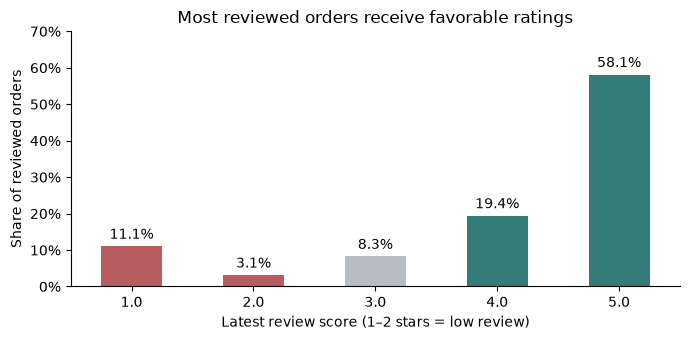

In [27]:
# Highlight the low-review target within the full rating distribution.
ax = review_distribution["percent"].plot.bar(
    color=["#B55D60", "#B55D60", "#B7BDC5", "#347C78", "#347C78"],
    figsize=(7, 3.5), rot=0,
)
ax.bar_label(ax.containers[0], labels=[
    f"{share:.1%}" for share in review_distribution["percent"]
], padding=3)
ax.set_title("Most reviewed orders receive favorable ratings")
ax.set_xlabel("Latest review score (1–2 stars = low review)")
ax.set_ylabel("Share of reviewed orders")
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Of the 98,666 orders in the item baseline, 97,917 have an observed review. Low ratings of 1–2 stars account for 13,893 orders, or 14.2% of reviewed orders. The remaining reviewed orders receive 3–5 stars. This imbalance makes the proportion of low reviews an important reference point for later comparisons.

<a id="section-19"></a>
### Review Coverage by Recorded Order Status

Recorded status helps describe review availability, but it does not determine inclusion in the analysis. Processing and shipped statuses are source snapshots rather than proof of terminal outcomes. Rates below use reviewed orders for low-review prevalence and all orders within each status for review coverage.

In [28]:
status_coverage = order_info.groupby("order_status").agg(
    total_orders=("order_id", "size"),
    reviewed_orders=("reviewed", "sum"),
    low_reviews=("low_review", "sum"),
    low_review_rate=("low_review", "mean"),
)
status_coverage["no_review_orders"] = (
    status_coverage["total_orders"] - status_coverage["reviewed_orders"]
)
status_coverage["review_rate"] = (
    status_coverage["reviewed_orders"] / status_coverage["total_orders"]
)
display(status_coverage.rename(columns={
    "total_orders": "Total orders", "reviewed_orders": "Reviewed orders",
    "low_reviews": "Low reviews", "low_review_rate": "Low-review rate",
    "no_review_orders": "No review", "review_rate": "Review coverage",
}).rename_axis("Recorded status").style.format({
    "Total orders": "{:,.0f}", "Reviewed orders": "{:,.0f}",
    "Low reviews": "{:,.0f}", "No review": "{:,.0f}",
    "Low-review rate": "{:.1%}", "Review coverage": "{:.1%}",
}))

,Total orders,Reviewed orders,Low reviews,Low-review rate,No review,Review coverage
Recorded status,,,,,,
approved,2,2,1,50.0%,0,100.0%
canceled,461,444,369,83.1%,17,96.3%
delivered,"96,478","95,832","12,273",12.8%,646,99.3%
invoiced,312,307,254,82.7%,5,98.4%
processing,301,295,274,92.9%,6,98.0%
shipped,"1,106","1,031",717,69.5%,75,93.2%
unavailable,6,6,5,83.3%,0,100.0%


<a id="section-20"></a>
### Review Outcome Definition

The latest answered review defines the low-review outcome. The following sensitivity check compares that choice with first-review and average-review classifications. The results describe label agreement, rather than an additional prediction target.

In [29]:
reviewed_orders = order_info.loc[order_info["reviewed"]]
latest_low = reviewed_orders["last_review_score"].le(2)
review_checks = []
for name, column in [("First vs latest", "first_review_score"),
                     ("Mean vs latest", "avg_review_score")]:
    changed = reviewed_orders[column].le(2).ne(latest_low)
    multiple = reviewed_orders["review_count"].gt(1)
    review_checks.append(
        {"comparison": name, "changed_orders": changed.sum(),
         "share_of_reviewed": changed.mean(),
         "share_of_multiple_reviews": changed[multiple].mean()}
    )
display(pd.DataFrame(review_checks).set_index("comparison").rename(columns={
    "changed_orders": "Changed labels",
    "share_of_reviewed": "Share of reviewed orders",
    "share_of_multiple_reviews": "Share of multiple-review orders",
}).style.format({
    "Changed labels": "{:,.0f}", "Share of reviewed orders": "{:.3%}",
    "Share of multiple-review orders": "{:.1%}",
}))

,Changed labels,Share of reviewed orders,Share of multiple-review orders
comparison,,,
First vs latest,95,0.097%,17.5%
Mean vs latest,58,0.059%,10.7%


First versus latest review changes 95 labels (0.097% of reviewed orders); average versus latest changes 58 (0.059%). These small differences support the latest-review definition. Detailed review chronology and pre-purchase timestamp anomalies are documented in preprocessing.

<a id="section-21"></a>
## Historical Activity and Calendar Context

Historical volume and review prevalence describe the population available for modeling. The figure separates marketplace activity from the rate of low reviews among reviewed orders. Months with fewer than 100 reviews are omitted from the prevalence line because their rates are unstable.

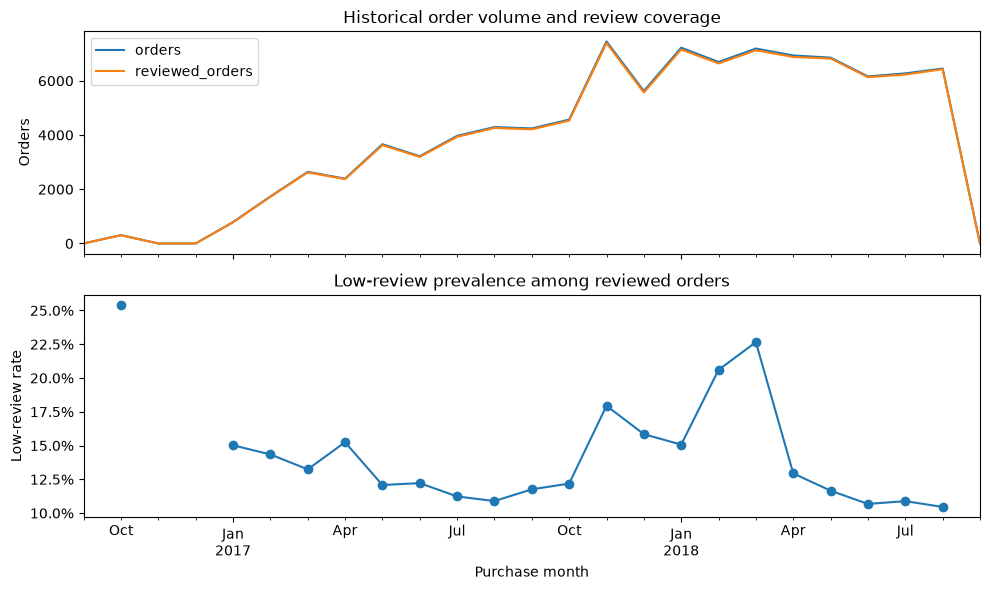

In [30]:
monthly = order_info.set_index("order_purchase_timestamp").resample("MS").agg(
    orders=("order_id", "size"),
    reviewed_orders=("reviewed", "sum"),
    low_review_rate=("low_review", "mean"),
)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
monthly[["orders", "reviewed_orders"]].plot(ax=axes[0])
axes[0].set_ylabel("Orders")
monthly["low_review_rate"].where(
    monthly["reviewed_orders"].ge(100)
).plot(ax=axes[1], marker="o")
axes[1].set_ylabel("Low-review rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_title("Historical order volume and review coverage")
axes[1].set_title("Low-review prevalence among reviewed orders")
axes[1].set_xlabel("Purchase month")
plt.tight_layout()
plt.show()

<a id="section-22"></a>
### Purchase Month-year Diagnostic

The detailed table retains all months with reviewed orders, including sparse periods omitted from the figure. Its reviewed-order population follows the modeling aggregation rules. Comparing the same months across years provides context for calendar predictors without assuming that a historical pattern recurs each year.

In [31]:
# Reconstruct the reviewed order population using the modeling aggregation rules.
eda_reviewed_orders = (
    olist_df.groupby("order_id")
    .agg(
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        order_estimated_delivery_date=("order_estimated_delivery_date", "first"),
        last_review_score=("last_review_score", "first"),
    )
    .reset_index()
    .dropna(subset=["last_review_score"])
    .reset_index(drop=True)
)
eda_reviewed_orders["low_review_2"] = (
    eda_reviewed_orders["last_review_score"].le(2).astype(int)
)

# Compare prevalence for each observed year-month at order grain.
month_year = (
    eda_reviewed_orders.set_index("order_purchase_timestamp")
    .resample("MS")["low_review_2"]
    .agg(reviewed_orders="size", low_review_rate="mean")
)
month_year = month_year.loc[month_year["reviewed_orders"].gt(0)]
display(month_year.rename(columns={
    "reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate",
}).rename_axis("Purchase month").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}).format_index(lambda date: date.strftime("%Y-%m")))

,Reviewed orders,Low-review rate
Purchase month,,
2016-09,3,100.0%
2016-10,303,25.4%
2016-12,1,0.0%
2017-01,779,15.0%
2017-02,"1,722",14.3%
2017-03,"2,621",13.2%
2017-04,"2,374",15.2%
2017-05,"3,626",12.1%
2017-06,"3,192",12.2%


<a id="section-23"></a>
### Monthly Review Prevalence Across Years

Comparing the same calendar months highlights differences between 2017 and 2018. The figure shows months with at least 100 reviewed orders, consistent with the historical prevalence plot; missing months are not filled or extrapolated. The detailed table above retains every observed month.

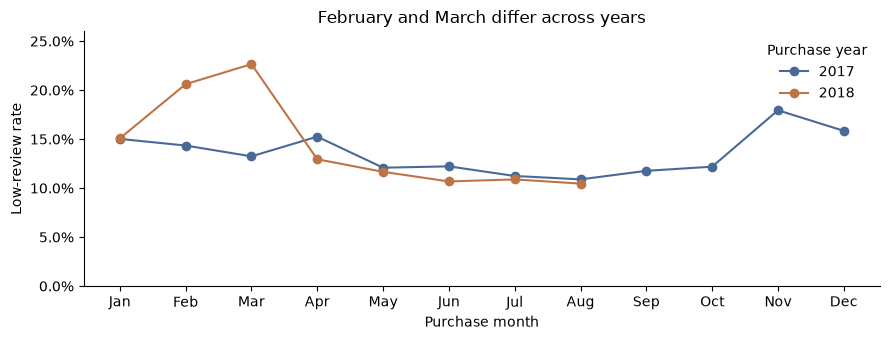

In [32]:
monthly_comparison = month_year.loc[
    month_year.index.year.isin([2017, 2018])
    & month_year["reviewed_orders"].ge(100)
].copy()
monthly_comparison["Year"] = monthly_comparison.index.year
monthly_comparison["Month"] = monthly_comparison.index.month
monthly_comparison = monthly_comparison.pivot(
    index="Month", columns="Year", values="low_review_rate"
).reindex(range(1, 13))

ax = monthly_comparison.plot(
    marker="o", color=["#496A96", "#BE7545"], figsize=(9, 3.5)
)
ax.set_title("February and March differ across years")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Low-review rate")
ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
])
ax.set_ylim(0, 0.26)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Purchase year", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

February and March have higher low-review prevalence in 2018 (20.6% and 22.7%) than in 2017 (14.3% and 13.2%). July and August are more consistent across the two years. These differences support interpreting calendar predictors as historical context rather than established seasonality, and motivate the chronological sensitivity evaluation in modeling. They do not identify a disruption or separate timing from changes in order composition.

<a id="section-24"></a>
## Repeat Purchasing and Analytical Focus

Repeat purchasing provides context for the choice of an order-risk objective. The distribution counts unique orders per customer within the observed dataset; it does not establish long-term retention.

In [33]:
customer_orders = (
    olist_df[["customer_unique_id", "order_id"]]
    .drop_duplicates()
    .groupby("customer_unique_id")
    .size()
)

repeat_customer_rate = (customer_orders > 1).mean()
customer_frequency = customer_orders.value_counts().sort_index().to_frame("Customers")
customer_frequency["Share of customers"] = (
    customer_frequency["Customers"] / len(customer_orders)
)
display(customer_frequency.rename_axis("Observed orders per customer").style.format({
    "Customers": "{:,.0f}", "Share of customers": "{:.2%}",
}))

,Customers,Share of customers
Observed orders per customer,,
1,"92,507",96.95%
2,"2,673",2.80%
3,192,0.20%
4,29,0.03%
5,9,0.01%
6,5,0.01%
7,3,0.00%
9,1,0.00%
16,1,0.00%


Only 3.05% of customers have multiple observed orders. Sparse repeat history supports the order-level customer-experience focus; it does not establish long-term retention rates.

<a id="section-25"></a>
## Marketplace categories
Product mix provides context for order composition and merchandise value. The category summaries describe item activity, not low-review risk. Category order counts can overlap when an order contains multiple categories.

In [34]:
# Source tables for category and seller summaries.
items = pd.read_csv(str(resolve_data_file("olist_order_items_dataset.csv", "raw")))
products = pd.read_csv(str(resolve_data_file("olist_products_dataset.csv", "raw")))
category_translation = pd.read_csv(
    str(resolve_data_file("product_category_name_translation.csv", "raw"))
)
orders = pd.read_csv(str(resolve_data_file("olist_orders_dataset.csv", "raw")))
reviews = pd.read_csv(str(resolve_data_file("olist_order_reviews_dataset.csv", "raw")))
sellers = pd.read_csv(str(resolve_data_file("olist_sellers_dataset.csv", "raw")))
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])


In [35]:
products_en = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

product_items = items.merge(
    products_en,
    on="product_id",
    how="left"
)

category_summary = (
    product_items.groupby("product_category_name_english", dropna=False)
    .agg(
        item_lines=("order_item_id", "count"),
        orders=("order_id", "nunique"),
        sellers=("seller_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        avg_price=("price", "mean"),
        avg_weight_g=("product_weight_g", "mean")
    )
    .sort_values("merchandise_value", ascending=False)
)

category_summary.head(20)

,item_lines,orders,sellers,merchandise_value,freight_value,avg_price,avg_weight_g
product_category_name_english,,,,,,,
health_beauty,9670,8836,492,1258681.34,182566.73,130.163531,1048.766391
watches_gifts,5991,5624,101,1205005.68,100535.93,201.135984,580.976632
bed_bath_table,11115,9417,196,1036988.68,204693.04,93.296327,2116.753396
sports_leisure,8641,7720,481,988048.97,168607.51,114.344285,1743.061567
computers_accessories,7827,6689,287,911954.32,147318.08,116.513903,902.509135
furniture_decor,8334,6449,370,729762.49,172749.30,87.564494,2653.128870
cool_stuff,3796,3632,267,635290.85,84039.10,167.357969,2548.971286
housewares,6964,5884,468,632248.66,146149.11,90.788148,3214.587881
auto,4235,3897,383,592720.11,92664.21,139.957523,2594.148288


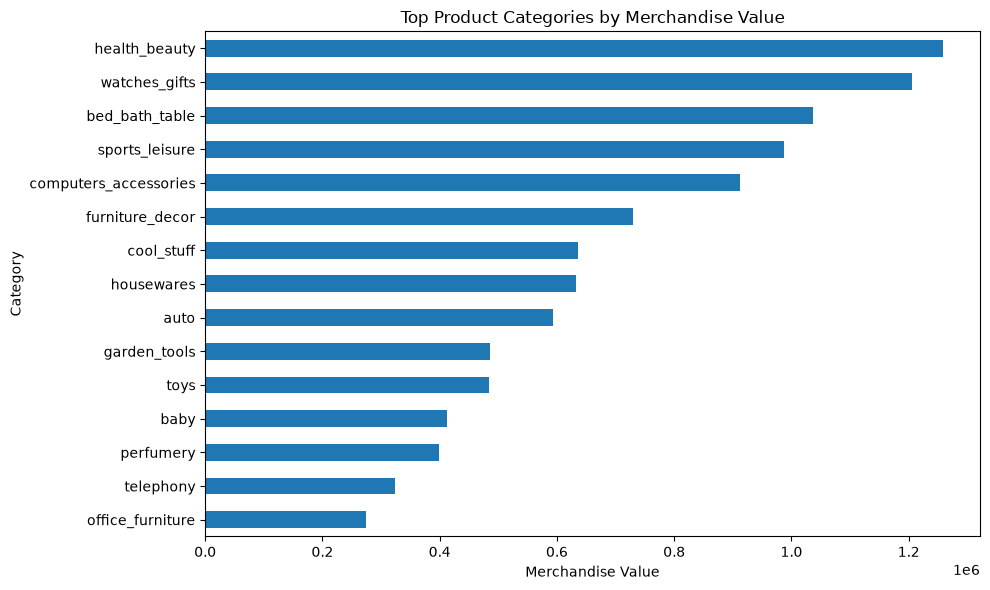

In [36]:
top_cat_plot = category_summary.head(15).sort_values("merchandise_value")
plt.figure(figsize=(10, 6))
top_cat_plot["merchandise_value"].plot(kind="barh")
plt.title("Top Product Categories by Merchandise Value")
plt.xlabel("Merchandise Value")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

<a id="section-26"></a>
## Seller activity and marketplace concentration
Seller transaction depth and merchandise-sales concentration provide context for seller-support prioritization. For consistency with the order-level analysis, the seller summaries below classify lateness by promised **calendar date**, select the latest review by **answer timestamp**, and calculate review rates **among reviewed seller-orders only**. Seller-order reviews are associated with each seller appearing on an order and cannot establish individual seller responsibility for the rating.

<a id="section-27"></a>
### Delivery timing definition

A delivery is late only if the actual **calendar date** is after the estimated delivery calendar date. Orders without both dates have an unknown late-delivery status. The separate continuous `delivery_vs_estimate_days` measure retains its original timestamp-based definition.

In [37]:
orders_dt = orders.copy()

date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
    orders_dt[col] = pd.to_datetime(orders_dt[col], errors="coerce")

orders_dt["purchase_to_approval_hours"] = (
    orders_dt["order_approved_at"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 3600

orders_dt["purchase_to_carrier_days"] = (
    orders_dt["order_delivered_carrier_date"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders_dt["purchase_to_delivery_days"] = (
    orders_dt["order_delivered_customer_date"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders_dt["delivery_vs_estimate_days"] = (
    orders_dt["order_delivered_customer_date"] - orders_dt["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

orders_dt["promised_window_days"] = (
    orders_dt["order_estimated_delivery_date"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders_dt["late_delivery"] = np.where(
    orders_dt["order_delivered_customer_date"].notna()
    & orders_dt["order_estimated_delivery_date"].notna(),
    (orders_dt["order_delivered_customer_date"].dt.normalize()
     > orders_dt["order_estimated_delivery_date"].dt.normalize()),
    np.nan
)

orders_dt["purchase_year_month"] = orders_dt["order_purchase_timestamp"].dt.to_period("M").astype(str)
orders_dt["purchase_weekday"] = orders_dt["order_purchase_timestamp"].dt.day_name()
orders_dt["purchase_hour"] = orders_dt["order_purchase_timestamp"].dt.hour

orders_dt[[
    "purchase_to_approval_hours",
    "purchase_to_carrier_days",
    "purchase_to_delivery_days",
    "delivery_vs_estimate_days",
    "promised_window_days"
]].describe()

,purchase_to_approval_hours,purchase_to_carrier_days,purchase_to_delivery_days,delivery_vs_estimate_days,promised_window_days
count,99281.000000,97658.000000,96476.000000,96476.000000,99441.000000
mean,10.419094,3.234050,12.558702,-11.179120,23.767650
std,26.038004,3.611996,9.546530,10.186113,8.832371
min,0.000000,-171.212419,0.533414,-146.016123,1.648993
25%,0.215000,1.128967,6.766403,-16.244384,18.331690
50%,0.343333,2.204676,10.217755,-11.948941,23.240370
75%,14.580833,4.071777,15.720327,-6.390000,28.424861
max,4509.180556,125.775521,209.628611,188.975081,155.135463


In [38]:
reviews_dt = reviews.copy()
reviews_dt["review_creation_date"] = pd.to_datetime(
    reviews_dt["review_creation_date"], errors="coerce"
)
reviews_dt["review_answer_timestamp"] = pd.to_datetime(
    reviews_dt["review_answer_timestamp"], errors="coerce"
)

review_count_per_order = reviews_dt.groupby("order_id").size().rename("review_record_count")
review_count_per_order.value_counts().sort_index()

review_record_count
1    98126
2      543
3        4
Name: count, dtype: int64

<a id="section-28"></a>
### Latest-review selection

Review records are ordered by `review_answer_timestamp` to align the seller-level descriptive analysis with the order-level target definition in preprocessing. If several reviews exist for one order, the last answered review supplies `last_review_score`.

In [39]:
review_sequence = reviews_dt.sort_values(
    ["order_id", "review_answer_timestamp"]
).copy()

review_sequence["review_sequence_number"] = (
    review_sequence.groupby("order_id").cumcount() + 1
)

review_change_summary = (
    review_sequence.groupby("order_id")
    .agg(
        review_count=("review_score", "size"),
        first_review_score=("review_score", "first"),
        last_review_score=("review_score", "last"),
        mean_review_score=("review_score", "mean"),
        min_review_score=("review_score", "min"),
        max_review_score=("review_score", "max"),
        first_review_date=("review_creation_date", "first"),
        last_review_date=("review_creation_date", "last")
    )
    .reset_index()
)

review_change_summary["score_change"] = (
    review_change_summary["last_review_score"] -
    review_change_summary["first_review_score"]
)

review_change_summary["score_change_direction"] = np.select(
    [
        review_change_summary["score_change"] > 0,
        review_change_summary["score_change"] < 0,
        review_change_summary["score_change"] == 0,
    ],
    ["Improved", "Declined", "No change"],
    default="Unknown"
)

review_change_summary.loc[
    review_change_summary["review_count"] > 1,
    "score_change_direction"
].value_counts()

score_change_direction
No change    346
Declined     113
Improved      88
Name: count, dtype: int64

In [40]:
seller_order = (
    items.groupby(["seller_id", "order_id"])
    .agg(
        seller_item_lines=("order_item_id", "count"),
        seller_unique_products=("product_id", "nunique"),
        seller_merchandise_value=("price", "sum"),
        seller_freight_value=("freight_value", "sum"),
        seller_first_shipping_limit=("shipping_limit_date", "min"),
        seller_last_shipping_limit=("shipping_limit_date", "max")
    )
    .reset_index()
)

seller_order = seller_order.merge(
    orders_dt[[
        "order_id", "order_status", "order_purchase_timestamp",
        "order_delivered_carrier_date", "order_delivered_customer_date",
        "order_estimated_delivery_date", "purchase_to_delivery_days",
        "delivery_vs_estimate_days", "late_delivery"
    ]],
    on="order_id",
    how="left"
)

seller_order = seller_order.merge(
    review_change_summary[[
        "order_id", "mean_review_score", "last_review_score",
        "review_count", "score_change"
    ]],
    on="order_id",
    how="left"
)

seller_order["seller_deadline_miss"] = np.where(
    seller_order["order_delivered_carrier_date"].notna() &
    seller_order["seller_last_shipping_limit"].notna(),
    seller_order["order_delivered_carrier_date"] >
    seller_order["seller_last_shipping_limit"],
    np.nan
)

seller_order["seller_shipping_delay_days"] = (
    seller_order["order_delivered_carrier_date"] -
    seller_order["seller_last_shipping_limit"]
).dt.total_seconds() / 86400

print("Seller-order rows:", len(seller_order))
print("Unique sellers:", seller_order["seller_id"].nunique())
print("Unique orders:", seller_order["order_id"].nunique())
seller_order.head()

Seller-order rows: 100010
Unique sellers: 3095
Unique orders: 98666


,seller_id,order_id,seller_item_lines,seller_unique_products,seller_merchandise_value,seller_freight_value,seller_first_shipping_limit,seller_last_shipping_limit,order_status,order_purchase_timestamp,...,order_estimated_delivery_date,purchase_to_delivery_days,delivery_vs_estimate_days,late_delivery,mean_review_score,last_review_score,review_count,score_change,seller_deadline_miss,seller_shipping_delay_days
0,0015a82c2db000af6aaaf3ae2ecb0532,7f39ba4c9052be115350065d07583cac,1,1,895.0,21.02,2017-10-24 23:56:20,2017-10-24 23:56:20,delivered,2017-10-18 08:16:34,...,2017-11-09,9.353831,-12.301331,0.0,1.0,1.0,1.0,0.0,0.0,-4.393970
1,0015a82c2db000af6aaaf3ae2ecb0532,9dc8d1a6f16f1b89874c29c9d8d30447,1,1,895.0,21.02,2017-10-18 14:49:22,2017-10-18 14:49:22,delivered,2017-10-12 13:33:22,...,2017-11-06,12.280810,-12.154352,0.0,5.0,5.0,1.0,0.0,0.0,-0.962963
2,0015a82c2db000af6aaaf3ae2ecb0532,d455a8cb295653b55abda06d434ab492,1,1,895.0,21.02,2017-10-12 22:24:16,2017-10-12 22:24:16,delivered,2017-09-26 22:17:05,...,2017-10-30,10.747014,-22.324456,0.0,5.0,5.0,1.0,0.0,0.0,-13.271678
3,001cca7ae9ae17fb1caed9dfb1094831,006e43460a55bc60c0a437521e426529,1,1,99.0,43.06,2017-05-17 01:30:22,2017-05-17 01:30:22,delivered,2017-05-11 00:24:35,...,2017-06-02,8.393542,-13.589387,0.0,5.0,5.0,1.0,0.0,0.0,-4.544329
4,001cca7ae9ae17fb1caed9dfb1094831,00dfb074b5c910fbd08e04691c4b712f,1,1,99.5,35.07,2017-06-19 19:55:19,2017-06-19 19:55:19,delivered,2017-06-08 19:43:35,...,2017-07-10,6.555833,-24.622234,0.0,5.0,5.0,1.0,0.0,0.0,-10.196273


<a id="section-29"></a>
### Seller review-rate denominators

Low-review and five-star rates use **only seller-orders with an observed review score**. Missing reviews are not treated as favorable ratings. Sellers with no reviewed orders have undefined (missing) review rates. Each order's review is attributed descriptively to all participating sellers; this does not identify which seller caused the review.

In [41]:
seller_profile = (
    seller_order.groupby("seller_id")
    .agg(
        orders=("order_id", "nunique"),
        item_lines=("seller_item_lines", "sum"),
        sales_value=("seller_merchandise_value", "sum"),
        freight_value=("seller_freight_value", "sum"),
        avg_order_value=("seller_merchandise_value", "mean"),
        avg_review=("mean_review_score", "mean"),
        median_review=("mean_review_score", "median"),
        low_review_rate=("last_review_score", lambda x: x.dropna().le(2).mean()),
        five_star_rate=("last_review_score", lambda x: x.dropna().eq(5).mean()),
        late_delivery_rate=("late_delivery", "mean"),
        seller_deadline_miss_rate=("seller_deadline_miss", "mean"),
        avg_delivery_days=("purchase_to_delivery_days", "mean"),
        avg_delivery_vs_estimate=("delivery_vs_estimate_days", "mean"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

seller_profile["active_span_days"] = (
    seller_profile["last_order"] - seller_profile["first_order"]
).dt.days

seller_profile = seller_profile.merge(sellers, on="seller_id", how="left")
seller_profile.describe(include="all").T.head(30)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
seller_id,3095,3095,0015a82c2db000af6aaaf3ae2ecb0532,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orders,3095.0,NaN,NaN,NaN,32.313409,1.0,2.0,6.0,21.5,1854.0,105.139763
item_lines,3095.0,NaN,NaN,NaN,36.397415,1.0,2.0,8.0,24.0,2033.0,119.193461
sales_value,3095.0,NaN,NaN,NaN,4391.484233,3.5,208.85,821.48,3280.83,229472.63,13921.997192
freight_value,3095.0,NaN,NaN,NaN,727.595974,6.66,46.17,155.52,558.17,51612.55,2327.157672
avg_order_value,3095.0,NaN,NaN,NaN,194.653787,3.5,60.124693,105.87,189.970833,6729.0,346.490015
avg_review,3090.0,NaN,NaN,NaN,3.998437,1.0,3.777778,4.184699,4.6,5.0,0.955809
median_review,3090.0,NaN,NaN,NaN,4.350971,1.0,4.0,5.0,5.0,5.0,1.114681
low_review_rate,3090.0,NaN,NaN,NaN,0.176948,0.0,0.0,0.1,0.214286,1.0,0.253815
five_star_rate,3090.0,NaN,NaN,NaN,0.57331,0.0,0.450176,0.590909,0.75,1.0,0.29624


<a id="section-30"></a>
### Seller transaction depth

Order counts describe the observed history per seller. These full-history thresholds are descriptive and do not reproduce the model's five-orders-in-180-days eligibility rule.

The observed marketplace includes 3,095 sellers, with a median of six orders per seller. Of these, 1,794 have at least five orders across the full dataset; the number eligible at a particular scoring date depends on its historical window.

In [42]:
seller_depth = pd.Series({
    "total_sellers": seller_profile["seller_id"].nunique(),
    "sellers_2plus_orders": int((seller_profile["orders"] >= 2).sum()),
    "sellers_5plus_orders": int((seller_profile["orders"] >= 5).sum()),
    "sellers_10plus_orders": int((seller_profile["orders"] >= 10).sum()),
    "sellers_25plus_orders": int((seller_profile["orders"] >= 25).sum()),
    "median_orders_per_seller": float(seller_profile["orders"].median()),
    "mean_orders_per_seller": float(seller_profile["orders"].mean())
})
seller_depth

total_sellers               3095.000000
sellers_2plus_orders        2524.000000
sellers_5plus_orders        1794.000000
sellers_10plus_orders       1271.000000
sellers_25plus_orders        709.000000
median_orders_per_seller       6.000000
mean_orders_per_seller        32.313409
dtype: float64

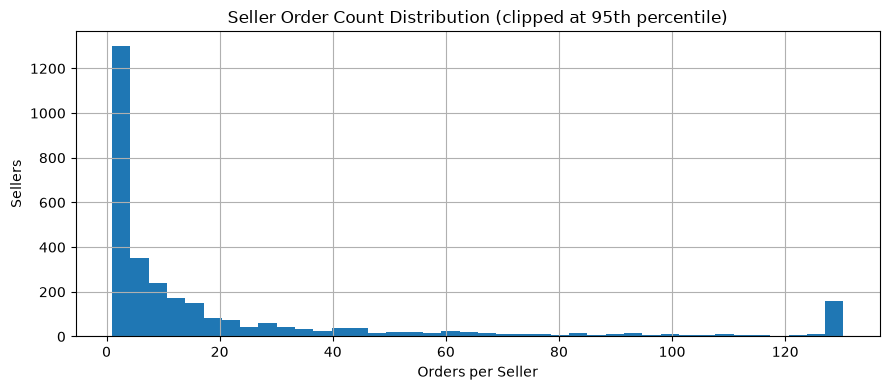

In [43]:
plt.figure(figsize=(9, 4))
seller_profile["orders"].clip(upper=seller_profile["orders"].quantile(.95)).hist(bins=40)
plt.title("Seller Order Count Distribution (clipped at 95th percentile)")
plt.xlabel("Orders per Seller")
plt.ylabel("Sellers")
plt.tight_layout()
plt.show()

<a id="section-31"></a>
### Merchandise-sales concentration

Sales shares show how much observed merchandise value is attributable to the largest sellers. Values are seller-attributable item prices; they exclude freight, payment totals, and any claim about profit or preventable losses.

The top 10 sellers account for 13.1% of merchandise value, the top 50 for 32.9%, and the top 100 for 45.1%. This concentration provides business context for seller-support prioritization without identifying which sellers provide poor customer experiences.

In [44]:
seller_sales_rank = seller_profile.sort_values("sales_value", ascending=False).copy()
seller_sales_rank["sales_share"] = (
    seller_sales_rank["sales_value"] / seller_sales_rank["sales_value"].sum()
)
seller_sales_rank["cumulative_sales_share"] = seller_sales_rank["sales_share"].cumsum()

concentration = pd.Series({
    "top_10_seller_sales_share": seller_sales_rank.head(10)["sales_share"].sum(),
    "top_50_seller_sales_share": seller_sales_rank.head(50)["sales_share"].sum(),
    "top_100_seller_sales_share": seller_sales_rank.head(100)["sales_share"].sum(),
})
concentration

top_10_seller_sales_share     0.131496
top_50_seller_sales_share     0.328888
top_100_seller_sales_share    0.450614
dtype: float64

<a id="section-32"></a>
## Placement-time Order Characteristics

Order value, shipping cost share, delivery promises, and seller geography describe information assumed available at placement. The summaries below compare low-review rates across existing feature groups. Category, listing metadata, and exported delivery promises retain the documented checkout-snapshot assumptions; fulfillment, payment, and review outcomes are excluded from predictive inputs.

In [45]:
order_eda = (
    olist_df.groupby("order_id")
    .agg(
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        customer_state=("customer_state", "first"),
        order_estimated_delivery_date=(
            "order_estimated_delivery_date",
            "first",
        ),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "count"),
        unique_products=("product_id", "nunique"),
        last_review_score=("last_review_score", "first"),
    )
    .reset_index()
)

order_eda["low_review"] = np.where(
    order_eda["last_review_score"].isna(),
    np.nan,
    (order_eda["last_review_score"] <= 2).astype(int),
)

order_eda["freight_share"] = (
    order_eda["freight_value"]
    / (
        order_eda["merchandise_value"]
        + order_eda["freight_value"]
    )
)

order_eda["promised_delivery_days"] = (
    order_eda["order_estimated_delivery_date"]
    - order_eda["order_purchase_timestamp"]
).dt.total_seconds() / 86400

cross_state = (
    olist_df["seller_state"].ne(olist_df["customer_state"])
    .where(olist_df["seller_state"].notna() & olist_df["customer_state"].notna())
    .groupby(olist_df["order_id"]).max().rename("any_cross_state")
)
order_eda = order_eda.join(cross_state, on="order_id")

<a id="section-33"></a>
### Distributions of selected order characteristics

Four distributions describe the baseline orders, including those without reviews. Merchandise value uses a logarithmic horizontal scale to show its full range. Missing values are omitted separately for each plot; no orders or predictor values are changed. Item counts of five or more are grouped for display only. These plots describe the population rather than relationships with review outcomes.

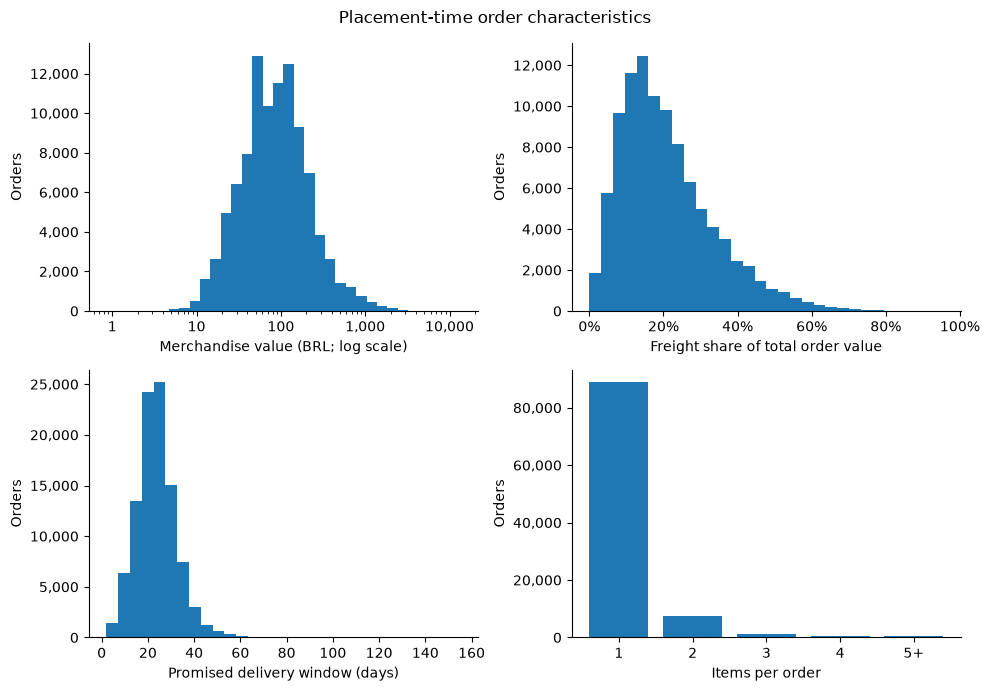

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
value_ax, freight_ax, promise_ax, items_ax = axes.flat
number_format = plt.FuncFormatter(lambda x, _: f"{x:,.0f}")

# Log-spaced bins retain the full merchandise-value range.
values = order_eda["merchandise_value"].dropna()
value_ax.hist(values, bins=np.geomspace(values.min(), values.max(), 35))
value_ax.set(
    xscale="log",
    xlabel="Merchandise value (BRL; log scale)",
)
value_ax.xaxis.set_major_formatter(number_format)

freight_ax.hist(order_eda["freight_share"].dropna(), bins=30)
freight_ax.set_xlabel("Freight share of total order value")
freight_ax.xaxis.set_major_formatter(PercentFormatter(1))

promise_ax.hist(order_eda["promised_delivery_days"].dropna(), bins=30)
promise_ax.set_xlabel("Promised delivery window (days)")

# Combine orders with five or more items for display.
item_counts = order_eda["item_count"].clip(upper=5).value_counts().sort_index()
items_ax.bar(item_counts.index, item_counts.values)
items_ax.set_xticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5+"])
items_ax.set_xlabel("Items per order")

for ax in axes.flat:
    ax.set_ylabel("Orders")
    ax.yaxis.set_major_formatter(number_format)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Placement-time order characteristics")
plt.tight_layout()
plt.show()

In [47]:
features = [
    "merchandise_value",
    "freight_share",
    "promised_delivery_days",
    "item_count",
]

feature_labels = {
    "merchandise_value": "Merchandise value (BRL)",
    "freight_share": "Freight share",
    "promised_delivery_days": "Promised delivery window (days)",
    "item_count": "Item count",
}
feature_tables = {}
for feature in features:
    temp = order_eda.dropna(
        subset=[feature, "low_review"]
    ).copy()

    temp["quartile"] = pd.qcut(
        temp[feature],
        q=4,
        duplicates="drop",
    )

    result = (
        temp.groupby(
            "quartile",
            observed=True,
        )
        .agg(
            orders=("order_id", "count"),
            low_review_rate=("low_review", "mean"),
        )
    )

    feature_tables[feature] = result

feature_summary = pd.concat(feature_tables, names=["Feature", "Observed interval"])
feature_summary.index = feature_summary.index.set_levels(
    feature_summary.index.levels[0].map(feature_labels), level=0
)
display(feature_summary.rename(columns={
    "orders": "Reviewed orders", "low_review_rate": "Low-review rate",
}).style.format({"Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}"}))

Low-review prevalence increases from 12.2% in the lowest merchandise-value group to 17.2% in the highest. Longer promised delivery windows also have higher low-review prevalence, while differences across freight-share groups are modest. These are unadjusted associations and do not establish effects of changing prices or delivery promises.

Item-count quantiles collapse into a single interval because many orders have the same count. That row reproduces overall prevalence and does not demonstrate a relationship between basket size and reviews. No alternative bins are introduced here.

In [48]:
cross_state_summary = order_eda.groupby("any_cross_state").agg(
    reviewed_orders=("low_review", "count"),
    low_review_rate=("low_review", "mean"),
)
display(cross_state_summary.rename(
    index={False: "All observed sellers in customer state", True: "Any cross-state seller"},
    columns={"reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate"},
).rename_axis("Seller geography").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate
Seller geography,,
All observed sellers in customer state,"35,110",11.8%
Any cross-state seller,"62,807",15.5%


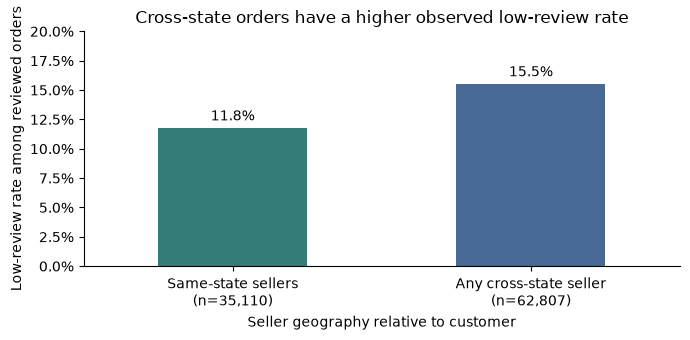

In [49]:
# Compare conditional rates, with reviewed-order counts visible.
ax = cross_state_summary["low_review_rate"].plot.bar(
    color=["#347C78", "#496A96"], figsize=(7, 3.5), rot=0,
)
ax.set_xticklabels([
    f"Same-state sellers\n(n={cross_state_summary.loc[False, 'reviewed_orders']:,.0f})",
    f"Any cross-state seller\n(n={cross_state_summary.loc[True, 'reviewed_orders']:,.0f})",
])
ax.bar_label(ax.containers[0], labels=[
    f"{rate:.1%}" for rate in cross_state_summary["low_review_rate"]
], padding=3)
ax.set_title("Cross-state orders have a higher observed low-review rate")
ax.set_xlabel("Seller geography relative to customer")
ax.set_ylabel("Low-review rate among reviewed orders")
ax.set_ylim(0, 0.2)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Orders involving a cross-state seller have a 15.5% low-review rate, compared with 11.8% for orders whose observed sellers are in the customer's state. This difference identifies geographic context for further interpretation; it does not establish that shipping across states causes dissatisfaction. Missing seller or customer states remain unknown in the underlying indicator.

<a id="section-34"></a>
## Delivery Performance and Customer Experience

Actual customer delivery provides retrospective context rather than a placement-time predictor. An absent delivery timestamp indicates missing evidence, not confirmed non-delivery. Timing comparisons use calendar dates and, in the following summaries, require delivery at or after purchase and an observed promised date.

In [50]:
delivery = order_info.copy()
delivery["delivery_group"] = np.where(
    delivery["order_delivered_customer_date"].notna(),
    "Observed delivery", "No observed delivery",
)
delivery_coverage = delivery.groupby("delivery_group").agg(
    orders=("order_id", "size"), reviewed_orders=("reviewed", "sum"),
    low_reviews=("low_review", "sum"), low_review_rate=("low_review", "mean"),
)
display(delivery_coverage.rename(columns={
    "orders": "All orders", "reviewed_orders": "Reviewed orders",
    "low_reviews": "Low reviews", "low_review_rate": "Low-review rate",
}).rename_axis("Delivery evidence").style.format({
    "All orders": "{:,.0f}", "Reviewed orders": "{:,.0f}",
    "Low reviews": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,All orders,Reviewed orders,Low reviews,Low-review rate
Delivery evidence,,,,
No observed delivery,"2,190","2,087","1,617",77.5%
Observed delivery,"96,476","95,830","12,276",12.8%


In [51]:
valid = delivery["order_delivered_customer_date"].ge(
    delivery["order_purchase_timestamp"]
) & delivery["order_estimated_delivery_date"].notna()
days = (
    delivery["order_delivered_customer_date"].dt.normalize()
    - delivery["order_estimated_delivery_date"].dt.normalize()
).dt.days.where(valid)
delivery["timing_band"] = pd.cut(
    days, bins=[-np.inf, -7, -1, 0, 3, 7, 14, np.inf],
    labels=["7+ days early", "1–6 days early", "On promised date",
            "1–3 days late", "4–7 days late", "8–14 days late", "15+ days late"],
)
delivery["late"] = np.where(valid, days.gt(0), np.nan)
timing_summary = delivery.groupby("late").agg(
    reviewed_orders=("low_review", "count"),
    low_review_rate=("low_review", "mean"),
    low_reviews=("low_review", "sum"),
)
display(timing_summary.rename(
    index={0.0: "Early/on-time", 1.0: "Late"},
    columns={"reviewed_orders": "Reviewed orders", "low_reviews": "Low reviews",
             "low_review_rate": "Low-review rate"},
).rename_axis("Calendar-date delivery timing").style.format({
    "Reviewed orders": "{:,.0f}", "Low reviews": "{:,.0f}",
    "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate,Low reviews
Calendar-date delivery timing,,,
Early/on-time,"89,448",9.3%,"8,293"
Late,"6,382",62.4%,"3,983"


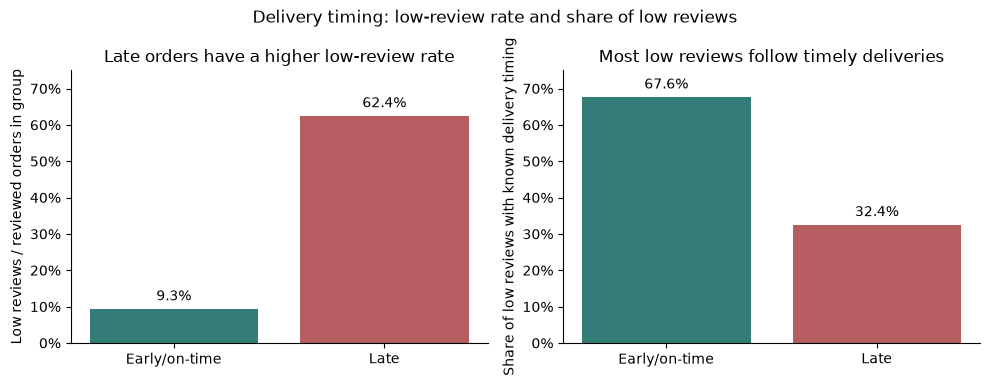

In [52]:
delivery_labels = ["Early/on-time", "Late"]
delivery_colors = ["#347C78", "#B55D60"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

rate_bars = axes[0].bar(
    delivery_labels, timing_summary["low_review_rate"], color=delivery_colors
)
axes[0].bar_label(rate_bars, labels=[
    f"{rate:.1%}" for rate in timing_summary["low_review_rate"]
], padding=4)
axes[0].set_title("Late orders have a higher low-review rate")
axes[0].set_ylabel("Low reviews / reviewed orders in group")
axes[0].set_ylim(0, 0.75)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))

low_review_share = (
    timing_summary["low_reviews"] / timing_summary["low_reviews"].sum()
)
share_bars = axes[1].bar(
    delivery_labels, low_review_share, color=delivery_colors
)
axes[1].bar_label(share_bars, labels=[
    f"{share:.1%}" for share in low_review_share
], padding=4)
axes[1].set_title("Most low reviews follow timely deliveries")
axes[1].set_ylabel("Share of low reviews with known delivery timing")
axes[1].set_ylim(0, 0.75)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Delivery timing: low-review rate and share of low reviews", fontsize=12)
plt.tight_layout()
plt.show()

<a id="section-35"></a>
### Calendar-date Delivery and Review Summary

Each order is counted once using the established latest answered review: 1–2 stars is low, and 3–5 stars is other. Delivery is late only when the actual calendar date is after the estimated calendar date; delivery on the promised date is on time regardless of hour. Overall low-review prevalence includes all reviewed orders. Delivery shares and row percentages use only reviewed orders with both dates; low-review case shares use only low-reviewed orders with both dates. Orders without an actual delivery date cannot be classified and are excluded from delivery comparisons, not from overall review prevalence. Missing estimated dates are also excluded. The contingency table reports the corresponding counts and conditional review rates.

In [53]:
calendar_reviewed = order_info.loc[order_info["reviewed"]]
calendar_known = calendar_reviewed.dropna(subset=[
    "order_delivered_customer_date", "order_estimated_delivery_date",
])
calendar_status = np.where(
    calendar_known["order_delivered_customer_date"].dt.normalize()
    > calendar_known["order_estimated_delivery_date"].dt.normalize(),
    "Late", "On time or early",
)
calendar_review_group = np.where(
    calendar_known["last_review_score"].le(2), "Low review", "Other review"
)
calendar_summary = pd.crosstab(calendar_status, calendar_review_group).reindex(
    index=["On time or early", "Late"], columns=["Low review", "Other review"],
    fill_value=0,
)
calendar_summary.loc["Total"] = calendar_summary.sum()
calendar_summary["Total orders"] = calendar_summary.sum(axis=1)
calendar_summary["Reviewed-order share"] = (
    calendar_summary["Total orders"] / len(calendar_known)
)
calendar_summary["Low review row %"] = (
    calendar_summary["Low review"] / calendar_summary["Total orders"]
)
calendar_summary["Other review row %"] = (
    calendar_summary["Other review"] / calendar_summary["Total orders"]
)
calendar_summary["Share of low-review cases"] = (
    calendar_summary["Low review"] / calendar_summary.loc["Total", "Low review"]
)
print(
    f"All reviewed orders: {len(calendar_reviewed):,}; low reviews: "
    f"{int(calendar_reviewed['low_review'].sum()):,} "
    f"({calendar_reviewed['low_review'].mean():.1%})."
)
print(
    f"Delivery comparison: {len(calendar_known):,} reviewed orders; "
    f"{len(calendar_reviewed) - len(calendar_known):,} excluded for missing dates "
    f"(actual: {calendar_reviewed['order_delivered_customer_date'].isna().sum():,}; "
    f"estimated: {calendar_reviewed['order_estimated_delivery_date'].isna().sum():,})."
)
display(calendar_summary.rename_axis("Delivery status").style.format({
    "Low review": "{:,.0f}", "Other review": "{:,.0f}",
    "Total orders": "{:,.0f}", "Reviewed-order share": "{:.1%}",
    "Low review row %": "{:.1%}", "Other review row %": "{:.1%}",
    "Share of low-review cases": "{:.1%}",
}))


All reviewed orders: 97,917; low reviews: 13,893 (14.2%).
Delivery comparison: 95,830 reviewed orders; 2,087 excluded for missing dates (actual: 2,087; estimated: 0).


col_0,Low review,Other review,Total orders,Reviewed-order share,Low review row %,Other review row %,Share of low-review cases
Delivery status,,,,,,,
On time or early,"8,293","81,155","89,448",93.3%,9.3%,90.7%,67.6%
Late,"3,983","2,399","6,382",6.7%,62.4%,37.6%,32.4%
Total,"12,276","83,554","95,830",100.0%,12.8%,87.2%,100.0%


Late deliveries have a 62.4% low-review rate, compared with 9.3% for early/on-time deliveries. However, timely deliveries are much more common: among orders with valid observed timing, 8,293 low reviews occur after timely delivery versus 3,983 after late delivery. Lateness is therefore a strong warning signal, but it does not account for most observed low reviews in this timing population.

In [54]:
band_rates = delivery.groupby("timing_band", observed=False).agg(
    reviewed_orders=("low_review", "count"),
    low_review_rate=("low_review", "mean"),
)
display(band_rates.rename(columns={
    "reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate",
}).rename_axis("Delivery timing").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate
Delivery timing,,
7+ days early,"75,749",9.0%
1–6 days early,"12,419",10.6%
On promised date,"1,280",12.4%
1–3 days late,"1,852",32.1%
4–7 days late,"1,748",67.7%
8–14 days late,"1,447",80.1%
15+ days late,"1,335",78.4%


<a id="section-36"></a>
### Review Ratings by Delivery-delay Severity

Low (1–2), neutral (3), and high (4–5) ratings distinguish different experiences among delayed orders. Percentages below use reviewed orders within each lateness band. This breakdown retains the original calendar-date lateness definition without adding the preceding summaries' valid-chronology restriction.

In [55]:
# Calculate delivery delays in calendar days.
late_df = eda_reviewed_orders.copy()

late_df["delivery_date"] = late_df["order_id"].map(
    olist_df.groupby("order_id")["order_delivered_customer_date"].first()
)

late_df["days_late"] = (
    late_df["delivery_date"].dt.normalize()
    - late_df["order_estimated_delivery_date"].dt.normalize()
).dt.days

# Restrict to reviewed orders delivered after their promised date.
late_df = late_df.loc[late_df["days_late"] > 0].copy()

late_df["lateness_band"] = pd.cut(
    late_df["days_late"],
    bins=[0, 3, 7, 14, np.inf],
    labels=["1–3 days", "4–7 days", "8–14 days", "15+ days"],
)

late_df["review_group"] = pd.cut(
    late_df["last_review_score"],
    bins=[0, 2, 3, 5],
    labels=["Low (1–2)", "Neutral (3)", "High (4–5)"],
)

late_review_table = pd.crosstab(
    late_df["lateness_band"],
    late_df["review_group"],
    normalize="index",
)

late_review_table["orders"] = (
    late_df["lateness_band"].value_counts().sort_index()
)

display(late_review_table.rename(columns={"orders": "Reviewed orders"})
    .rename_axis("Delay beyond promised date").style.format({
        "Low (1–2)": "{:.1%}", "Neutral (3)": "{:.1%}",
        "High (4–5)": "{:.1%}", "Reviewed orders": "{:,.0f}",
    }))

review_group,Low (1–2),Neutral (3),High (4–5),Reviewed orders
Delay beyond promised date,,,,
1–3 days,32.1%,14.7%,53.2%,"1,852"
4–7 days,67.7%,9.8%,22.5%,"1,748"
8–14 days,80.1%,8.9%,11.0%,"1,447"
15+ days,78.4%,9.1%,12.5%,"1,335"


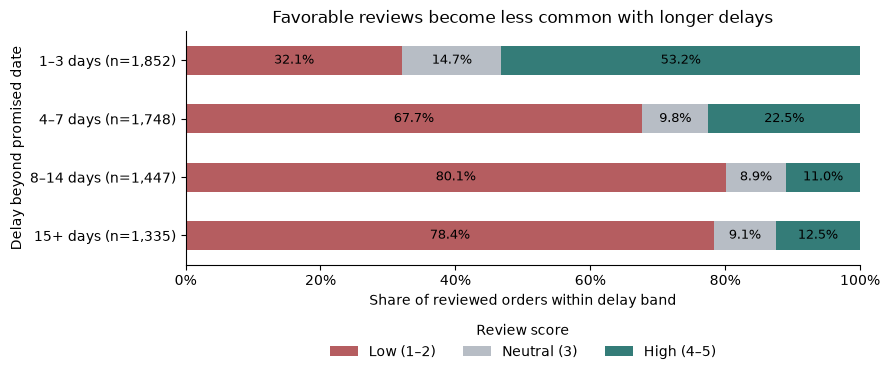

In [56]:
review_composition = late_review_table.drop(columns="orders")
ax = review_composition.plot.barh(
    stacked=True, color=["#B55D60", "#B7BDC5", "#347C78"], figsize=(9, 4)
)
ax.set_yticklabels([
    f"{band} (n={orders:,.0f})"
    for band, orders in late_review_table["orders"].items()
])
ax.invert_yaxis()
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{bar.get_width():.1%}" for bar in bars],
                 label_type="center", fontsize=9)
ax.set_title("Favorable reviews become less common with longer delays")
ax.set_xlabel("Share of reviewed orders within delay band")
ax.set_ylabel("Delay beyond promised date")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Review score", loc="upper center", bbox_to_anchor=(0.5, -0.20),
          ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

High ratings account for 53.2% of reviews when delivery is 1–3 days late, compared with 22.5% when it is 4–7 days late. Low ratings are more common in the longer-delay groups. The relationship is not strictly increasing across every band, and these associations do not establish causation. Meeting a delivery promise does not guarantee satisfaction, while missing it does not guarantee dissatisfaction.

<a id="section-37"></a>
## Seller Shipping-deadline Context

The shipping-deadline indicator compares order-level carrier handoff with the earliest item deadline. It is an order-context proxy and cannot identify which seller caused a delay. Joint results with customer-delivery lateness help distinguish this association from eventual delivery performance.

In [57]:
limits = olist_df.assign(
    shipping_limit_date=pd.to_datetime(olist_df["shipping_limit_date"])
).groupby("order_id")["shipping_limit_date"].min()
delivery = delivery.join(limits.rename("first_shipping_limit"), on="order_id")
valid_handoff = delivery["order_delivered_carrier_date"].ge(
    delivery["order_purchase_timestamp"]
) & delivery["first_shipping_limit"].notna()
delivery["any_deadline_miss"] = np.where(
    valid_handoff,
    delivery["order_delivered_carrier_date"].gt(delivery["first_shipping_limit"]),
    np.nan,
)
deadline_summary = delivery.groupby("any_deadline_miss").agg(
    reviewed_orders=("low_review", "count"), low_review_rate=("low_review", "mean"),
)
deadline_timing_summary = delivery.groupby(["any_deadline_miss", "late"]).agg(
    reviewed_orders=("low_review", "count"), low_review_rate=("low_review", "mean"),
)
display(deadline_summary.rename(
    index={0.0: "No observed miss", 1.0: "Observed miss"},
    columns={"reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate"},
).rename_axis("Shipping-deadline proxy").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))
display(deadline_timing_summary.rename(
    index={0.0: "No", 1.0: "Yes"}, level=0,
).rename(index={0.0: "Early/on-time", 1.0: "Late"}, level=1).rename(
    columns={"reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate"},
).rename_axis(["Deadline miss", "Customer delivery"]).style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate
Shipping-deadline proxy,,
No observed miss,"88,011",12.4%
Observed miss,"8,750",24.4%


Orders with an observed deadline miss have a 24.4% low-review rate, compared with 12.4% without an observed miss. Within late deliveries, the rates are much closer (63.2% versus 62.1%). Among timely deliveries, a difference remains (13.7% versus 8.9%). These comparisons qualify the unconditional association without establishing a causal pathway or seller responsibility.

<a id="section-38"></a>
## Findings and Implications for Modeling

| Finding | Implication |
|---|---|
| Review outcomes are imbalanced, with 14.2% low reviews | Overall prevalence provides a baseline for evaluating risk concentration. |
| Historical prevalence changes across periods | Chronological evaluation complements the random historical benchmark; calendar patterns are not assumed to recur. |
| Repeat purchasing is uncommon in the observed history | Order-level customer-experience risk is the project's focus. |
| Order value, promised windows, and geography show descriptive associations | Placement-time characteristics provide a basis for modeling; their effects are not established by EDA. |
| Late delivery is strongly associated with low reviews, but most timing-observable low reviews follow timely delivery | Placement-time risk scoring can complement fulfillment monitoring rather than duplicate it. |
| Favorable reviews occur even after delays | Delivery performance and customer experience are related but not equivalent. |

<a id="section-39"></a>
### Scope and Limitations

Review-based comparisons are conditional on customers leaving an observed review; missing reviews are not treated as favorable outcomes. The baseline excludes orders without items. Short historical coverage, sparse months, repeated customers, and shared reviews limit generalization and independence. Missing delivery timestamps do not establish non-delivery, and seller-deadline indicators are proxies rather than seller-specific evidence.

Listing metadata and delivery promises retain the documented assumptions about availability at checkout. EDA associations do not establish causal effects or predict the benefit of an intervention. Fulfillment outcomes remain outside the placement-time feature set, and zero physical weights remain missing for modeling imputation.

Seller depth and sales concentration provide context for the secondary seller-support use case. Category-value summaries describe marketplace composition rather than customer-experience risk.

<a id="section-40"></a>
# Modeling

Two complementary models support customer-experience monitoring. The primary model ranks individual orders at placement using the probability of an eventual low review. The secondary model ranks historically active sellers using the probability of at least one observed low-review event among the next month's orders.

The models have different prediction units, targets, eligibility rules, and evaluation periods. Their AP and lift values are interpreted within each task, not compared as competing models.

In [58]:
# Resolve data files using the GitHub repository folder structure.

def resolve_data_file(filename, data_type="raw"):
    data_path = Path("..") / "01_data" / data_type / filename
    if not data_path.is_file():
        raise FileNotFoundError(
            f"Could not find {filename} at {data_path}. "
            "Run this notebook from the repository's 03_final folder."
        )
    return data_path


<a id="section-41"></a>
## Order-level Risk at Placement

<a id="section-42"></a>
### Objective

Delivery performance is an important indicator of customer experience, but
fulfillment outcomes are not available when an order is placed. Identifying
potentially dissatisfied customers earlier could help Olist prioritize
transactions for proactive monitoring and support.

This analysis develops a classification model to predict the risk of an
eventual low customer review using information available at order placement.
The target, `low_review_2`, identifies orders receiving a final observed
review of 1–2 stars, compared with orders receiving 3–5 stars.

The primary objective is to **rank orders by relative risk**, rather than
automatically classify or intervene on every potentially dissatisfied
customer. Model performance is therefore evaluated using average precision
and risk concentration among the highest-ranked orders, with a hypothetical
top-decile monitoring capacity.

The analysis compares multiple classification approaches, evaluates their
ability to generalize to later orders, and examines whether predictive
signal remains among orders that ultimately meet their delivery promise.

<a id="section-43"></a>
### Order-level Modeling Population

The item-level baseline is aggregated to one observation per order. Aggregated
features describe basket value and complexity, product characteristics, seller
geography, and product-category composition. An order is considered cross-state
if at least one seller is located outside the customer's state. Missing aggregate product weights and zero-valued weight totals are treated as missing for subsequent imputation.

The supervised population consists of orders with an observed customer review.
The binary target, `low_review_2`, identifies orders whose latest answered
review received 1–2 stars, with 3–5 stars representing the comparison group.

Review-answer timestamps are retained to establish when outcomes became
observable for chronological training, but are excluded from the predictors.

In [59]:
# Load the item baseline and raw review timestamps.
olist_df = pd.read_csv(
    str(resolve_data_file("olist_order_item_baseline.csv", "preprocessed")),
    parse_dates=[
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
        "order_delivered_customer_date",
    ],
)

reviews = pd.read_csv(
    str(resolve_data_file("olist_order_reviews_dataset.csv", "raw")),
    parse_dates=["review_answer_timestamp"],
)

In [60]:
# Collapse item rows to one row per order.
order_df = (
    olist_df.groupby("order_id")
    .agg(
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "size"),
        unique_product_count=("product_id", "nunique"),
        unique_seller_count=("seller_id", "nunique"),
        total_product_weight_g=(
            "product_weight_g", lambda values: values.sum(min_count=1)
        ),
        avg_product_photos=("product_photos_qty", "mean"),
        avg_product_name_length=("product_name_lenght", "mean"),
        avg_product_description_length=("product_description_lenght", "mean"),
        unique_category_count=(
            "product_category_name",
            lambda values: values.fillna("unknown").nunique(),
        ),
        customer_unique_id=("customer_unique_id", "first"),
        customer_state=("customer_state", "first"),
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        order_estimated_delivery_date=("order_estimated_delivery_date", "first"),
        last_review_score=("last_review_score", "first"),
    )
    .reset_index()
)
# Treat zero total weights as missing for later imputation.
order_df["total_product_weight_g"] = order_df["total_product_weight_g"].replace(
    0, np.nan
)
order_df["freight_share"] = order_df["freight_value"] / (
    order_df["merchandise_value"] + order_df["freight_value"]
)
order_df["promised_delivery_days"] = (
    order_df["order_estimated_delivery_date"]
    - order_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Represent category presence, not the number of matching items.
categories = pd.crosstab(
    olist_df["order_id"], olist_df["product_category_name"].fillna("unknown")
)
categories = (categories > 0).astype(int).add_prefix("category_")

# Flag any seller outside the customer state.
cross_state = (
    olist_df["seller_state"].ne(olist_df["customer_state"])
    .where(olist_df["seller_state"].notna() & olist_df["customer_state"].notna())
    .groupby(olist_df["order_id"]).max().rename("any_cross_state")
)

# Track when the selected review outcome became observable.
latest_reviews = (
    reviews.sort_values(["order_id", "review_answer_timestamp"])
    .groupby("order_id").tail(1)
    .set_index("order_id")["review_answer_timestamp"]
    .rename("latest_review_answer_timestamp")
)
order_df = (
    order_df.join(categories, on="order_id")
    .join(cross_state, on="order_id")
    .join(latest_reviews, on="order_id")
    .dropna(subset=["last_review_score"])  # Unreviewed outcomes are unknown.
    .reset_index(drop=True)
)
order_df["low_review_2"] = order_df["last_review_score"].le(2).astype(int)
order_df["purchase_month"] = order_df["order_purchase_timestamp"].dt.month
order_df["purchase_day_of_week"] = order_df["order_purchase_timestamp"].dt.dayofweek

# Define the supervised target and summarize the modeling population.
print(f"Orders: {len(order_df):,}")
print(f"Low reviews: {order_df['low_review_2'].sum():,}")
print(f"Low-review rate: {order_df['low_review_2'].mean():.2%}")

Orders: 97,917
Low reviews: 13,893
Low-review rate: 14.19%


<a id="section-44"></a>
### Placement-time Predictors

The model uses 90 predictors representing information assumed available at order
placement. These include order value and basket complexity, product listing
characteristics, customer geography, purchase timing, and product-category
composition. Post-purchase outcomes and other unavailable information are
excluded to prevent data leakage.

Predictors are grouped according to their preprocessing requirements: numeric,
categorical, and binary. Product-category indicators represent category presence
within an order rather than the number of items in each category.

In [61]:
numeric_features = [
    "merchandise_value",
    "freight_value",
    "item_count",
    "unique_product_count",
    "unique_seller_count",
    "total_product_weight_g",
    "avg_product_photos",
    "avg_product_name_length",
    "avg_product_description_length",
    "unique_category_count",
    "freight_share",
    "promised_delivery_days",
]

categorical_features = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
]

# Binary category-presence indicators
product_category_features = [
    col for col in order_df.columns
    if col.startswith("category_")
]

binary_features = ["any_cross_state", *product_category_features]

feature_cols = numeric_features + categorical_features + binary_features

print(f"Predictors: {len(feature_cols)}")

Predictors: 90


<a id="section-45"></a>
### Evaluation Methodology

Two evaluation strategies assess the model's ability to identify orders at
risk of receiving a low customer review.

**Randomized evaluation:** A stratified 80/20 train/test split (`random_state=1`)
provides a benchmark for predicting unseen orders drawn from the historical
population. Hyperparameters are selected through cross-validation using
training data only.

**Chronological evaluation:** A time-based split assesses how well the model
generalizes to later orders. Training includes purchases before May 1, 2018,
whose latest review outcomes were observable before that date. Testing includes
orders placed afterward, with at least 60 days of potential review follow-up
before the dataset's final observed review.

The 60-day follow-up window accommodates 99.50% of valid historical review
delays without redefining the target. Both evaluations exclude orders without
observed reviews, so performance is conditional on review availability.

Model performance is assessed using average precision, ROC-AUC, and
top-decile risk concentration. The top 10% represents a hypothetical monitoring
capacity rather than an optimized intervention threshold.

<a id="section-46"></a>
#### Review Follow-up Coverage

The calculation below supports the 60-day potential-follow-up allowance. Coverage is measured among reviewed orders with observed, nonnegative purchase-to-latest-answer intervals; negative and missing intervals are excluded from this calculation only. It measures when observed outcomes arrived, not the proportion of all orders that receive a review or a guarantee that every eventual review has arrived. The target and modeling population remain unchanged.

In [62]:
# Measure follow-up among observed order-level reviews, not review completeness.
review_delay_days = (
    order_df["latest_review_answer_timestamp"]
    - order_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400
valid_review_delay = review_delay_days.loc[review_delay_days.ge(0)]
review_followup_summary = pd.DataFrame({
    "Valid reviewed orders": [len(valid_review_delay)],
    "Latest answer within 60 days (%)": [100 * valid_review_delay.le(60).mean()],
    "Negative intervals excluded": [int(review_delay_days.lt(0).sum())],
    "Missing intervals excluded": [int(review_delay_days.isna().sum())],
})
display(review_followup_summary.round(2))


,Valid reviewed orders,Latest answer within 60 days (%),Negative intervals excluded,Missing intervals excluded
0,97912,99.5,5,0


In [63]:
# Randomized evaluation: stratified 80/20 split.
random_train, random_test = train_test_split(
    order_df,
    test_size=0.20,
    random_state=1,
    stratify=order_df["low_review_2"],
)

# Chronological evaluation: training labels must be observable before the cutoff.
boundary = pd.Timestamp("2018-05-01")
review_end = reviews["review_answer_timestamp"].max()
test_end = review_end - pd.Timedelta(days=60)

chronological_train = order_df.loc[
    (order_df["order_purchase_timestamp"] < boundary)
    & (order_df["latest_review_answer_timestamp"] < boundary)
]

# Allow at least 60 days of potential review follow-up for test orders.
chronological_test = order_df.loc[
    order_df["order_purchase_timestamp"].between(boundary, test_end)
]

evaluation_sets = {
    "Random": (random_train, random_test),
    "Chronological": (chronological_train, chronological_test),
}

# Summarize split proportions and low-review prevalence.
evaluation_summary = pd.DataFrame(
    [
        {
            "Evaluation": name,
            "Train orders": len(train),
            "Train (%)": len(train) / (len(train) + len(test)),
            "Train prevalence": train["low_review_2"].mean(),
            "Test orders": len(test),
            "Test (%)": len(test) / (len(train) + len(test)),
            "Test prevalence": test["low_review_2"].mean(),
        }
        for name, (train, test) in evaluation_sets.items()
    ]
).set_index("Evaluation")

display(
    evaluation_summary.style.format(
        {
            "Train orders": "{:,.0f}",
            "Train (%)": "{:.1%}",
            "Train prevalence": "{:.2%}",
            "Test orders": "{:,.0f}",
            "Test (%)": "{:.1%}",
            "Test prevalence": "{:.2%}",
        }
    )
)

,Train orders,Train (%),Train prevalence,Test orders,Test (%),Test prevalence
Evaluation,,,,,,
Random,"78,333",80.0%,14.19%,"19,584",20.0%,14.19%
Chronological,"68,890",72.9%,15.28%,"25,608",27.1%,10.93%


The randomized evaluation preserves an 80/20 split and approximately equal class prevalence, while the chronological evaluation uses a historical cutoff, resulting in different split proportions and lower low-review prevalence in the later test period.

<a id="section-47"></a>
### Model Training

<a id="section-48"></a>
#### Logistic Regression

Logistic regression provides an interpretable linear benchmark for predicting
low-review risk. Numeric predictors are median-imputed and standardized,
categorical predictors are one-hot encoded, and existing binary indicators
are retained without transformation.

Preprocessing is incorporated into the modeling pipeline so that imputation,
scaling, and encoding are fitted independently within each cross-validation
training fold, preventing information leakage. Regularization strength and
class weighting are selected using five-fold stratified cross-validation,
with average precision as the optimization metric.

The initial tree and ensemble searches selected boundary values. A modest expanded search checks neighboring settings using the same training folds and AP metric. The predictor specification and evaluation sets remain fixed. Holdouts have already been inspected, so subsequent results are comparative validation rather than a fresh final test.

The expanded grids are fixed as the final modest search budget. Some selected values remain at a boundary; these are the best tested configurations, not established global optima. Small CV differences do not establish a meaningful performance advantage.

In [64]:
# Fit imputation, scaling, and encoding within each training fold.
numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_features,
        ),
        ("binary", "passthrough", binary_features),
    ]
)

pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000)),
    ]
)

In [65]:
# Select hyperparameters using training-only cross-validation.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

param_grid = {
    "model__C": [0.001, 0.01, 0.1],
    "model__class_weight": [None, "balanced"],
}

logistic_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=2,
)

logistic_search.fit(random_train[feature_cols], random_train["low_review_2"])

cv_results = (
    pd.DataFrame(logistic_search.cv_results_)[
        [
            "param_model__C",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__C": "C",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(cv_results.round(4))
print("Selected parameters:", logistic_search.best_params_)
print(f"Best mean CV AP: {logistic_search.best_score_:.4f}")

,C,class_weight,Mean CV AP,CV SD,Rank
2,0.010,NaN,0.2507,0.0068,1
4,0.100,NaN,0.2501,0.0063,2
3,0.010,balanced,0.2498,0.0066,3
5,0.100,balanced,0.2490,0.0061,4
1,0.001,balanced,0.2474,0.0061,5
0,0.001,NaN,0.2457,0.0060,6


Selected parameters: {'model__C': 0.01, 'model__class_weight': None}
Best mean CV AP: 0.2507


<a id="section-49"></a>
#### Decision Tree

A decision tree provides a nonlinear alternative to logistic regression,
capturing interactions between predictors without requiring explicit
interaction terms.

Hyperparameters are selected using the same five-fold stratified
cross-validation and average precision metric. Maximum tree depth and
minimum leaf size are constrained to reduce overfitting. Numeric predictors
are median-imputed but do not require standardization.

Selected: depth 20, minimum leaf size 250, no class weighting (mean CV AP 0.2361). Depth remains at the search ceiling, while leaf size is bracketed by smaller and larger values.

In [66]:
# Reuse preprocessing without numeric scaling.
tree_preprocessor = clone(preprocessor).set_params(
    numeric=SimpleImputer(strategy="median")
)

tree_pipeline = Pipeline(
    [
        ("preprocessor", tree_preprocessor),
        ("model", DecisionTreeClassifier(random_state=1)),
    ]
)

tree_param_grid = {
    "model__max_depth": [5, 10, 20],
    "model__min_samples_leaf": [100, 250, 500],
    "model__class_weight": [None, "balanced"],
}

tree_search = GridSearchCV(
    tree_pipeline,
    tree_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)

tree_search.fit(random_train[feature_cols], random_train["low_review_2"])

tree_cv_results = (
    pd.DataFrame(tree_search.cv_results_)[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__max_depth": "max_depth",
            "param_model__min_samples_leaf": "min_samples_leaf",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(tree_cv_results.head().round(4))
print("Selected parameters:", tree_search.best_params_)
print(f"Best mean CV AP: {tree_search.best_score_:.4f}")

,max_depth,min_samples_leaf,class_weight,Mean CV AP,CV SD,Rank
7,20,250,NaN,0.2361,0.0083,1
16,20,250,balanced,0.2358,0.0067,2
8,20,500,NaN,0.2344,0.0088,3
17,20,500,balanced,0.2338,0.0073,4
13,10,250,balanced,0.2322,0.0069,5


Selected parameters: {'model__class_weight': None, 'model__max_depth': 20, 'model__min_samples_leaf': 250}
Best mean CV AP: 0.2361


<a id="section-50"></a>
#### Random Forest

Random forest extends the decision tree approach by combining predictions
from multiple trees, reducing the variance associated with individual trees.

The model uses the same preprocessing and five-fold stratified cross-validation
as the decision tree. Hyperparameters controlling tree depth, minimum leaf
size, and class weighting are selected using average precision.

Selected: depth 25, minimum leaf size 5, balanced class weights (mean CV AP 0.2676). Depth remains at the search ceiling. Leading configurations have similar CV AP, so the selection does not establish a meaningful advantage over nearby settings.

In [67]:
# Compare forest configurations using the same CV folds.
forest_pipeline = Pipeline(
    [
        ("preprocessor", clone(tree_preprocessor)),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_features="sqrt",
                random_state=1,
                n_jobs=1,
            ),
        ),
    ]
)

forest_param_grid = {
    "model__max_depth": [15, 20, 25],
    "model__min_samples_leaf": [1, 5, 10],
    "model__class_weight": [None, "balanced"],
}

forest_search = GridSearchCV(
    forest_pipeline,
    forest_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)

forest_search.fit(random_train[feature_cols], random_train["low_review_2"])

forest_cv_results = (
    pd.DataFrame(forest_search.cv_results_)[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__max_depth": "max_depth",
            "param_model__min_samples_leaf": "min_samples_leaf",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(forest_cv_results.head().round(4))
print("Selected parameters:", forest_search.best_params_)
print(f"Best mean CV AP: {forest_search.best_score_:.4f}")

,max_depth,min_samples_leaf,class_weight,Mean CV AP,CV SD,Rank
16,25,5,balanced,0.2676,0.0097,1
7,25,5,NaN,0.2674,0.0081,2
6,25,1,NaN,0.2670,0.0067,3
8,25,10,NaN,0.2670,0.0094,4
3,20,1,NaN,0.2659,0.0068,5


Selected parameters: {'model__class_weight': 'balanced', 'model__max_depth': 25, 'model__min_samples_leaf': 5}
Best mean CV AP: 0.2676


<a id="section-51"></a>
#### Histogram Gradient Boosting

Histogram gradient boosting builds trees sequentially, with each new tree
improving upon the predictions of the preceding ensemble. This provides
another nonlinear approach capable of capturing complex relationships
between predictors.

The model uses the same five-fold stratified cross-validation and average
precision metric as the other classifiers. Categorical features are
one-hot encoded into a dense representation, and internal early stopping
is disabled to maintain consistent training populations across folds.

Selected: learning rate 0.05, maximum 60 leaves, no class weighting (mean CV AP 0.2711). Learning rate is bracketed; the leaf limit remains at the search ceiling.

In [68]:
# Histogram boosting requires dense encoded inputs.
boosting_preprocessor = clone(tree_preprocessor).set_params(
    categorical=OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
    ),
    sparse_threshold=0,
)

boosting_pipeline = Pipeline(
    [
        ("preprocessor", boosting_preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=100,
                early_stopping=False,
                random_state=1,
            ),
        ),
    ]
)

boosting_param_grid = {
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_leaf_nodes": [15, 30, 60],
    "model__class_weight": [None, "balanced"],
}

boosting_search = GridSearchCV(
    boosting_pipeline,
    boosting_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)

boosting_search.fit(random_train[feature_cols], random_train["low_review_2"])

boosting_cv_results = (
    pd.DataFrame(boosting_search.cv_results_)[
        [
            "param_model__learning_rate",
            "param_model__max_leaf_nodes",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__learning_rate": "learning_rate",
            "param_model__max_leaf_nodes": "max_leaf_nodes",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(boosting_cv_results.head().round(4))
print("Selected parameters:", boosting_search.best_params_)
print(f"Best mean CV AP: {boosting_search.best_score_:.4f}")

,learning_rate,max_leaf_nodes,class_weight,Mean CV AP,CV SD,Rank
5,0.05,60,NaN,0.2711,0.0109,1
8,0.10,60,NaN,0.2693,0.0102,2
4,0.05,30,NaN,0.2688,0.0111,3
7,0.10,30,NaN,0.2663,0.0090,4
6,0.10,15,NaN,0.2658,0.0100,5


Selected parameters: {'model__class_weight': None, 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 60}
Best mean CV AP: 0.2711


<a id="section-52"></a>
### Model Evaluation

<a id="section-53"></a>
#### Randomized Model Comparison

The four classifiers are evaluated on the random holdout using average
precision (AP), ROC-AUC, and risk concentration at different monitoring
capacities.

Because the business objective is to prioritize orders for proactive
monitoring, the analysis examines how many eventual low reviews fall
within the highest-ranked 5%, 10%, 20%, and 30% of orders. A 10%
monitoring capacity serves as an illustrative operational scenario,
not an established Olist constraint or an optimized probability threshold.

The random-holdout comparison informs model selection. The selected
approach is subsequently refitted and evaluated on the chronological
population to assess generalization to later orders.

In [69]:
candidates = {
    "Logistic regression": logistic_search.best_estimator_,
    "Decision tree": tree_search.best_estimator_,
    "Random forest": forest_search.best_estimator_,
    "Gradient boosting": boosting_search.best_estimator_,
}

models = {(name, "Random"): model for name, model in candidates.items()}

predictions = {
    (name, "Random"): model.predict_proba(random_test[feature_cols])[:, 1]
    for name, model in candidates.items()
}

In [70]:
# Evaluate discrimination and risk concentration at fixed capacities.
metric_rows = []
capacity_rows = []

for (name, evaluation), probability in predictions.items():
    test = evaluation_sets[evaluation][1]
    actual = test["low_review_2"]

    metric_rows.append(
        {
            "model": name,
            "evaluation": evaluation,
            "prevalence": actual.mean(),
            "ap": average_precision_score(actual, probability),
            "roc_auc": roc_auc_score(actual, probability),
        }
    )

    ranked = pd.DataFrame(
        {"actual": actual.to_numpy(), "probability": probability}
    ).sort_values("probability", ascending=False, kind="stable")

    for fraction in [0.05, 0.10, 0.20, 0.30]:
        count = int(np.ceil(len(ranked) * fraction))
        selected = ranked.head(count)
        precision = selected["actual"].mean()

        capacity_rows.append(
            {
                "model": name,
                "evaluation": evaluation,
                "capacity": fraction,
                "orders_monitored": count,
                "low_reviews_captured": selected["actual"].sum(),
                "capture": selected["actual"].sum() / actual.sum(),
                "precision": precision,
                "lift": precision / actual.mean(),
            }
        )

model_metrics = pd.DataFrame(metric_rows)
capacity_results = pd.DataFrame(capacity_rows)

print("Random holdout: overall model performance")
display(
    model_metrics.loc[model_metrics["evaluation"].eq("Random")]
    .drop(columns="evaluation")
    .round(4)
)

print("Random holdout: low-review capture by monitoring capacity")
display(
    capacity_results.loc[capacity_results["evaluation"].eq("Random")]
    .pivot(index="model", columns="capacity", values="capture")
    .round(4)
)

print("Random holdout: top-decile performance")
display(
    capacity_results.loc[
        capacity_results["evaluation"].eq("Random")
        & capacity_results["capacity"].eq(0.10)
    ]
    .drop(columns=["evaluation", "capacity"])
    .round(4)
)

Random holdout: overall model performance


,model,prevalence,ap,roc_auc
0,Logistic regression,0.1419,0.2541,0.6348
1,Decision tree,0.1419,0.2463,0.6282
2,Random forest,0.1419,0.2705,0.6583
3,Gradient boosting,0.1419,0.2835,0.6663


Random holdout: low-review capture by monitoring capacity


capacity,0.05,0.10,0.20,0.30
model,,,,
Decision tree,0.1317,0.2249,0.3631,0.4649
Gradient boosting,0.1515,0.2425,0.3940,0.5059
Logistic regression,0.1367,0.2303,0.3688,0.4707
Random forest,0.1418,0.2418,0.3814,0.5031


Random holdout: top-decile performance


,model,orders_monitored,low_reviews_captured,capture,precision,lift
1,Logistic regression,1959,640,0.2303,0.3267,2.3023
5,Decision tree,1959,625,0.2249,0.3190,2.2483
9,Random forest,1959,672,0.2418,0.3430,2.4174
13,Gradient boosting,1959,674,0.2425,0.3441,2.4246


<a id="section-54"></a>
#### Model Discrimination

ROC curves compare overall discrimination on the same random holdout. Model selection also considers AP and capture at the monitoring capacities above. Gradient boosting has the strongest overall metrics, but its top-decile capture is effectively tied with random forest.

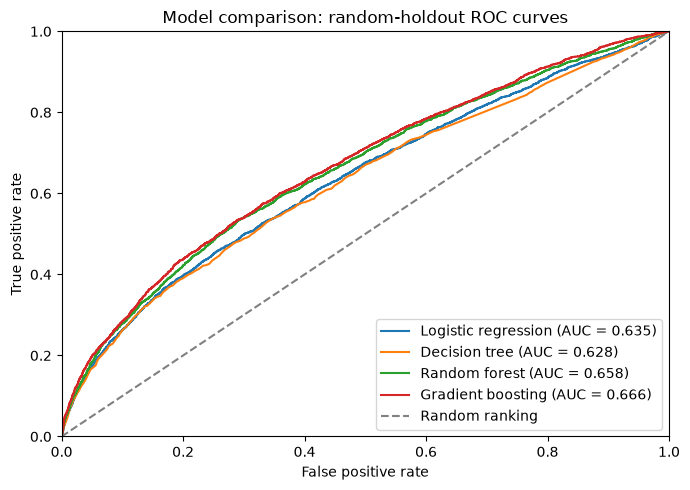

In [71]:
# Compare overall discrimination on the same random holdout.
fig, ax = plt.subplots(figsize=(7, 5))

for name in [
    "Logistic regression",
    "Decision tree",
    "Random forest",
    "Gradient boosting",
]:
    probability = predictions[name, "Random"]
    false_positive_rate, true_positive_rate, _ = roc_curve(
        random_test["low_review_2"], probability
    )
    auc = roc_auc_score(random_test["low_review_2"], probability)
    ax.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name} (AUC = {auc:.3f})",
    )

ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="Model comparison: random-holdout ROC curves",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

<a id="section-55"></a>
#### Selected Model: Cumulative Gains

The random-holdout gains curve shows the share of low-review outcomes captured as monitoring expands through the highest-risk orders. The diagonal represents random selection; the marked top decile illustrates a hypothetical monitoring capacity.

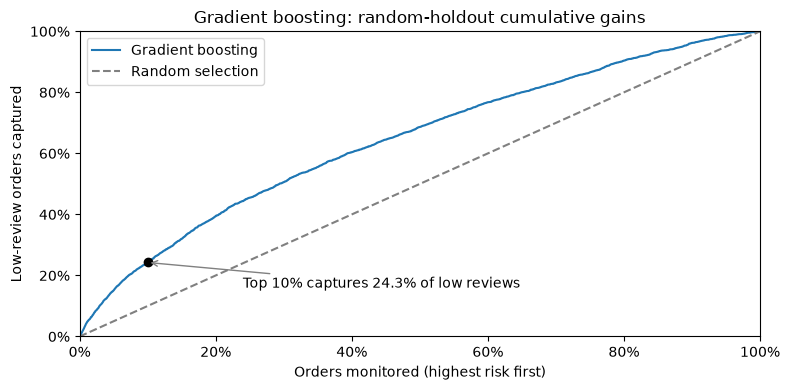

In [72]:
# Show cumulative low-review capture in the primary random holdout.
gains_orders = pd.DataFrame({
    "low_review": random_test["low_review_2"].to_numpy(),
    "risk": predictions["Gradient boosting", "Random"],
}).sort_values("risk", ascending=False, kind="stable")

monitored_share = np.arange(1, len(gains_orders) + 1) / len(gains_orders)
captured_share = (
    gains_orders["low_review"].cumsum().to_numpy()
    / gains_orders["low_review"].sum()
)
top_n = int(np.ceil(len(gains_orders) * 0.10))
top_capture = captured_share[top_n - 1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    np.r_[0, monitored_share],
    np.r_[0, captured_share],
    label="Gradient boosting",
)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random selection")
ax.scatter(monitored_share[top_n - 1], top_capture, color="black", zorder=3)
ax.annotate(
    f"Top 10% captures {top_capture:.1%} of low reviews",
    (monitored_share[top_n - 1], top_capture),
    xytext=(0.24, 0.16),
    arrowprops={"arrowstyle": "->", "color": "gray"},
)
ax.set(
    xlabel="Orders monitored (highest risk first)",
    ylabel="Low-review orders captured",
    title="Gradient boosting: random-holdout cumulative gains",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.set_xticks(np.linspace(0, 1, 6), labels=["0%", "20%", "40%", "60%", "80%", "100%"])
ax.set_yticks(np.linspace(0, 1, 6), labels=["0%", "20%", "40%", "60%", "80%", "100%"])
ax.legend()
plt.tight_layout()
plt.show()

<a id="section-56"></a>
#### Chronological Evaluation

Gradient boosting was selected based on the randomized model comparison.
To assess performance on later orders, the model is refitted using the
same hyperparameters on orders with labels observable before May 1, 2018,
and evaluated on subsequent purchases with at least 60 days of potential
review follow-up.

This out-of-time evaluation provides a more realistic assessment of
forward-looking risk ranking than the randomized holdout.

In [73]:
# Refit gradient boosting on chronologically eligible training data.
sensitivity_model = clone(candidates["Gradient boosting"])

sensitivity_model.fit(
    chronological_train[feature_cols],
    chronological_train["low_review_2"],
)

models["Gradient boosting", "Chronological"] = sensitivity_model

probability = sensitivity_model.predict_proba(
    chronological_test[feature_cols]
)[:, 1]

predictions["Gradient boosting", "Chronological"] = probability

actual = chronological_test["low_review_2"]

# Overall evaluation metrics.
model_metrics.loc[len(model_metrics)] = {
    "model": "Gradient boosting",
    "evaluation": "Chronological",
    "prevalence": actual.mean(),
    "ap": average_precision_score(actual, probability),
    "roc_auc": roc_auc_score(actual, probability),
}

# Rank orders by predicted risk.
ranked = pd.DataFrame(
    {"actual": actual.to_numpy(), "probability": probability}
).sort_values("probability", ascending=False, kind="stable")

# Evaluate cumulative monitoring capacities.
for fraction in [0.05, 0.10, 0.20, 0.30]:
    count = int(np.ceil(len(ranked) * fraction))
    selected = ranked.head(count)
    precision = selected["actual"].mean()

    capacity_results.loc[len(capacity_results)] = {
        "model": "Gradient boosting",
        "evaluation": "Chronological",
        "capacity": fraction,
        "orders_monitored": count,
        "low_reviews_captured": selected["actual"].sum(),
        "capture": selected["actual"].sum() / actual.sum(),
        "precision": precision,
        "lift": precision / actual.mean(),
    }

print("Gradient boosting: randomized vs. chronological evaluation")

display(
    model_metrics.loc[model_metrics["model"].eq("Gradient boosting")]
    .drop(columns="model")
    .round(4)
)

display(
    capacity_results.loc[
        capacity_results["model"].eq("Gradient boosting")
        & capacity_results["capacity"].eq(0.10)
    ]
    .drop(columns=["model", "capacity"])
    .round(4)
)

Gradient boosting: randomized vs. chronological evaluation


,evaluation,prevalence,ap,roc_auc
3,Random,0.1419,0.2835,0.6663
4,Chronological,0.1093,0.1825,0.5929


,evaluation,orders_monitored,low_reviews_captured,capture,precision,lift
13,Random,1959,674,0.2425,0.3441,2.4246
17,Chronological,2561,575,0.2054,0.2245,2.0534


On the later-period evaluation, gradient boosting achieves AP **0.182** and ROC-AUC **0.593**, compared with AP **0.283** and ROC-AUC **0.666** in the random holdout. The highest-ranked 10% of later orders contains **575** eventual low-review cases, approximately **20.5%** of all low-review cases in that evaluation. Its low-review prevalence is approximately **22.5%**, compared with **10.9%** overall (**2.05× lift**). The chronological population's lower low-review prevalence also affects the comparison of AP across evaluations.

This demonstrates concentration above random selection; the simple-rule comparison below evaluates whether the model adds value beyond item count. The chronological fit uses only labels available before the cutoff, but model selection used the broader random-split workflow and the holdouts had already been inspected. These results are therefore a retrospective temporal sensitivity check rather than a fully independent prospective evaluation.

<a id="section-57"></a>
##### Selected Model: Risk by Predicted Decile

The chronological holdout is divided into ten groups ranked by predicted
low-review risk. Lift compares each group's observed low-review rate with
the overall chronological prevalence. A lift above 1 indicates greater
risk than the population average.

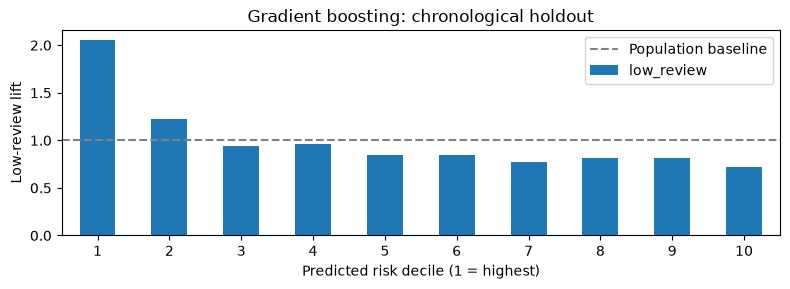

In [74]:
# Decile 1 contains the highest predicted-risk orders.
ranked_orders = pd.DataFrame({
    "low_review": chronological_test["low_review_2"].to_numpy(),
    "risk": predictions["Gradient boosting", "Chronological"],
}).sort_values("risk", ascending=False, kind="stable")

ranked_orders["decile"] = (
    np.arange(len(ranked_orders)) * 10 // len(ranked_orders) + 1
)

decile_lift = (
    ranked_orders.groupby("decile")["low_review"].mean()
    / ranked_orders["low_review"].mean()
)

decile_lift.plot.bar(figsize=(8, 3), rot=0)

plt.axhline(1, color="gray", linestyle="--", label="Population baseline")
plt.xlabel("Predicted risk decile (1 = highest)")
plt.ylabel("Low-review lift")
plt.title("Gradient boosting: chronological holdout")
plt.legend()
plt.tight_layout()
plt.show()

<a id="section-58"></a>
#### Item-count Benchmark Across Both Holdouts

This comparison assesses whether the selected model captures more low reviews than item-count ranking at the same monitoring capacity. Both holdouts target the top 10% of orders, rounded up. Capture is the percentage of actual low-review cases selected; differences are percentage points of capture, not changes in review prevalence. Cutoff ties use exact expected capture under uniform selection, and random selection is shown by its expectation. The supporting calculations and separate benchmark tables are retained in collapsed cells; the combined table is the main comparison.

In [75]:
# Expected capture with uniform selection among orders tied at the cutoff.
def item_benchmark_capture(actual, scores, count):
    scores = np.asarray(scores)
    cutoff = np.sort(scores)[-count]
    above, tied = scores > cutoff, scores == cutoff
    captured = actual[above].sum() + (count - above.sum()) * actual[tied].mean()
    return 100 * captured / actual.sum()

random_rule_actual = random_test["low_review_2"].to_numpy()
random_rule_count = int(np.ceil(len(random_rule_actual) * 0.10))
random_rule_scores = {
    "Random selection (expected)": np.zeros(len(random_rule_actual)),
    "Item-count ranking": random_test["item_count"].to_numpy(),
    "Final predictive model": predictions["Gradient boosting", "Random"],
}
random_rule_comparison = pd.DataFrame({
    "Strategy": list(random_rule_scores),
    "Orders targeted (%)": 100 * random_rule_count / len(random_rule_actual),
    "Low-review cases captured (%)": [
        item_benchmark_capture(random_rule_actual, scores, random_rule_count)
        for scores in random_rule_scores.values()
    ],
})
display(random_rule_comparison.round(2))


,Strategy,Orders targeted (%),Low-review cases captured (%)
0,Random selection (expected),10.0,10.00
1,Item-count ranking,10.0,20.75
2,Final predictive model,10.0,24.25


In [76]:
rule_actual = chronological_test["low_review_2"].to_numpy()
rule_count = int(np.ceil(len(rule_actual) * 0.10))
rule_scores = {
    "Random selection (expected)": np.zeros(len(rule_actual)),
    "Item-count ranking": chronological_test["item_count"].to_numpy(),
    "Seller-count ranking": chronological_test["unique_seller_count"].to_numpy(),
    "Final predictive model": predictions["Gradient boosting", "Chronological"],
}
rule_comparison = pd.DataFrame({
    "Strategy": list(rule_scores),
    "Orders targeted (%)": 100 * rule_count / len(rule_actual),
    "Low-review cases captured (%)": [
        item_benchmark_capture(rule_actual, scores, rule_count)
        for scores in rule_scores.values()
    ],
})
display(rule_comparison.round(2))


,Strategy,Orders targeted (%),Low-review cases captured (%)
0,Random selection (expected),10.0,10.00
1,Item-count ranking,10.0,21.64
2,Seller-count ranking,10.0,14.41
3,Final predictive model,10.0,20.54


In [77]:
# Combined tie-adjusted benchmark results.
benchmark_summary = pd.concat({
    "Random holdout": random_rule_comparison.set_index("Strategy")[
        "Low-review cases captured (%)"
    ],
    "Chronological holdout": rule_comparison.set_index("Strategy")[
        "Low-review cases captured (%)"
    ],
}, axis=1).reindex([
    "Random selection (expected)", "Item-count ranking", "Final predictive model",
]).T
benchmark_summary["Model minus item rule (pp)"] = (
    benchmark_summary["Final predictive model"]
    - benchmark_summary["Item-count ranking"]
)
display(benchmark_summary.round(2))


Strategy,Random selection (expected),Item-count ranking,Final predictive model,Model minus item rule (pp)
Random holdout,10.0,20.75,24.25,3.5
Chronological holdout,10.0,21.64,20.54,-1.1


The model captures **3.50 percentage points more** low-review cases than item count on the random holdout (**24.25% versus 20.75%**), but **1.10 points fewer** on the chronological holdout (**20.54% versus 21.64%**). Its incremental targeting advantage does not persist into the later period at the evaluated top-10% capacity. Seller-count ranking captures **14.41%** on the chronological holdout, versus **10.00%** expected from random selection.

These results support item count as a strong, simple targeting baseline. Lift above random selection alone does not establish added value over that rule. The comparisons do not establish equivalent performance at other capacities, statistical significance, or the benefit of an intervention.

<a id="section-59"></a>
### Model Interpretation

<a id="section-60"></a>
#### Permutation Importance

Permutation importance measures how much the selected gradient boosting
model's average precision decreases when each predictor is shuffled
individually in the chronological holdout.

Larger decreases indicate greater contributions to predictive performance
in this evaluation population. Correlated predictors may share importance,
and these results do not establish causal relationships.

In [78]:
permutation = permutation_importance(
    models["Gradient boosting", "Chronological"],
    chronological_test[feature_cols],
    chronological_test["low_review_2"],
    scoring="average_precision",
    n_repeats=5,
    random_state=1,
)

permutation_top = pd.DataFrame(
    {
        "feature": feature_cols,
        "mean_ap_decrease": permutation.importances_mean,
        "std_ap_decrease": permutation.importances_std,
    }
).sort_values("mean_ap_decrease", ascending=False).head(15)

display(permutation_top.round(4))

,feature,mean_ap_decrease,std_ap_decrease
2,item_count,0.0478,0.0023
4,unique_seller_count,0.0177,0.0008
11,promised_delivery_days,0.0050,0.0009
15,any_cross_state,0.0047,0.0009
0,merchandise_value,0.0042,0.0004
12,customer_state,0.0041,0.0009
5,total_product_weight_g,0.0032,0.0008
8,avg_product_description_length,0.0016,0.0006
1,freight_value,0.0015,0.0012
10,freight_share,0.0012,0.0006


<a id="section-61"></a>
#### Interpretation

Item count and distinct seller count lead the chronological AP-based permutation importance, with decreases of approximately **0.048** and **0.018**, respectively. They contribute most to this model's predictive ranking in the evaluated population.

Other predictors, including promised delivery time and customer geography, contribute more modestly. Permutation importance does not establish the direction or cause of an association, and correlated predictors can share importance. The simple-rule benchmark remains necessary: strong feature importance does not establish that the model ranks orders better than item count alone.

<a id="section-62"></a>
#### Interpretation Implications

Item count and seller count lead the chronological AP-based permutation results. Purchase month is absent from the displayed top 15, so this output does not support assigning it a ninth-place rank. The May-onward chronological test also cannot validate February/March effects.

The February/March elevation is concentrated in 2018, while July/August rates are reasonably consistent across 2017–2018. Month is interpreted as historical context rather than established seasonality. These descriptive comparisons do not explain the cause; months with only 1–3 reviewed orders have unstable rates. The diagnostics qualify the interpretation without changing the model, predictors, or evaluation protocol.

The supporting month-year distributions are documented in the Purchase Month-year Diagnostic subsection of `02_eda.ipynb`.

<a id="section-63"></a>
### Customer-Experience Risk Beyond Late Delivery

Late delivery is strongly associated with low reviews, but most low-reviewed
orders with valid observed delivery timing arrived by their promised date.

This retrospective sensitivity analysis examines whether the selected
placement-time model retains predictive signal among orders that were
eventually delivered on time.

The analysis compares the primary chronological model's performance on the
full holdout and timely-delivery subgroup, then refits the same gradient
boosting pipeline using only timely chronological training orders.

All predictors and hyperparameters remain unchanged. Actual delivery timing
is used only to define the retrospective subgroup, not as a model predictor
or proposed deployment criterion.

In [79]:
# Identify orders delivered on or before their promised calendar date.
delivery_dates = (
    olist_df.groupby("order_id")["order_delivered_customer_date"]
    .first()
)

order_df["timely_delivery"] = (
    order_df["order_id"].map(delivery_dates).dt.normalize()
    <= order_df["order_estimated_delivery_date"].dt.normalize()
)

timely_order_ids = set(
    order_df.loc[order_df["timely_delivery"], "order_id"]
)

chrono_train, chrono_test = evaluation_sets["Chronological"]

train_timely = chrono_train.loc[
    chrono_train["order_id"].isin(timely_order_ids)
].copy()

test_timely_mask = chrono_test["order_id"].isin(timely_order_ids)
test_timely = chrono_test.loc[test_timely_mask].copy()

print(
    f"Timely chronological training: {len(train_timely):,} orders "
    f"({train_timely['low_review_2'].mean():.2%} low reviews)"
)

print(
    f"Timely chronological test: {len(test_timely):,} orders "
    f"({test_timely['low_review_2'].mean():.2%} low reviews)"
)

Timely chronological training: 62,276 orders (9.58% low reviews)
Timely chronological test: 24,149 orders (8.34% low reviews)


<a id="section-64"></a>
#### Chronological Sensitivity Analysis

Three evaluations distinguish the effects of restricting the test population
from those of restricting the training population:

1. Original model evaluated on all chronological test orders.
2. Original model evaluated only on timely chronological test orders.
3. Timely-only refit evaluated on those same timely test orders.

Average precision, ROC-AUC, and top-decile lift and capture are reported.
Differences in low-review prevalence are considered when comparing results.

In [80]:
def ranking_metrics(y_true, y_prob):
    y_true = pd.Series(y_true).reset_index(drop=True)
    prevalence = y_true.mean()

    top_n = int(np.ceil(len(y_true) * 0.10))
    top_idx = np.argsort(-np.asarray(y_prob), kind="stable")[:top_n]
    top_rate = y_true.iloc[top_idx].mean()

    return {
        "Prevalence": prevalence,
        "AP": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Top 10% lift": top_rate / prevalence,
        "Top 10% capture": y_true.iloc[top_idx].sum() / y_true.sum(),
    }

In [81]:
# Refit the selected pipeline using timely chronological training orders.
timely_model = clone(models["Gradient boosting", "Chronological"])

timely_model.fit(
    train_timely[feature_cols],
    train_timely["low_review_2"],
)

timely_prob = timely_model.predict_proba(
    test_timely[feature_cols]
)[:, 1]

# Original chronological predictions, preserving test-row alignment.
primary_prob = predictions["Gradient boosting", "Chronological"]
primary_timely_prob = primary_prob[test_timely_mask.to_numpy()]

comparisons = {
    "Primary / full holdout": (
        chrono_test["low_review_2"],
        primary_prob,
    ),
    "Primary / timely holdout": (
        test_timely["low_review_2"],
        primary_timely_prob,
    ),
    "Timely refit / timely holdout": (
        test_timely["low_review_2"],
        timely_prob,
    ),
}

timely_results = pd.DataFrame({
    name: ranking_metrics(y_true, y_prob)
    for name, (y_true, y_prob) in comparisons.items()
}).T

display(timely_results.round(4))

,Prevalence,AP,ROC-AUC,Top 10% lift,Top 10% capture
Primary / full holdout,0.1093,0.1825,0.5929,2.0534,0.2054
Primary / timely holdout,0.0834,0.1721,0.6214,2.4726,0.2473
Timely refit / timely holdout,0.0834,0.1825,0.6329,2.7059,0.2706


<a id="section-65"></a>
##### Risk Concentration Among Timely Deliveries

Top-decile lift compares the monitored group with its own evaluation population. The full and timely populations have different low-review prevalence, so taller bars do not by themselves indicate better absolute precision. Timely delivery defines a retrospective subgroup, not a placement-time eligibility rule.

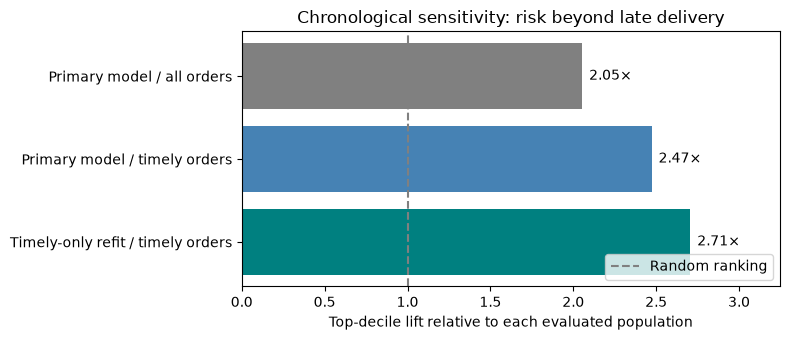

In [82]:
# Top-decile concentration across sensitivity populations.
lift = timely_results["Top 10% lift"]
labels = [
    "Primary model / all orders",
    "Primary model / timely orders",
    "Timely-only refit / timely orders",
]

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(labels, lift, color=["gray", "steelblue", "teal"])
ax.bar_label(bars, labels=[f"{value:.2f}×" for value in lift], padding=5)
ax.axvline(1, color="gray", linestyle="--", label="Random ranking")
ax.set(
    xlabel="Top-decile lift relative to each evaluated population",
    title="Chronological sensitivity: risk beyond late delivery",
    xlim=(0, lift.max() * 1.2),
)
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

<a id="section-66"></a>
#### Predictive Characteristics Among Timely Deliveries

Permutation importance is calculated for the timely-only chronological
refit using average precision on the timely chronological test population.

This examines whether the leading predictive characteristics remain
consistent after restricting the analysis to orders that ultimately
met their delivery promise.

In [83]:
timely_importance = permutation_importance(
    timely_model,
    test_timely[feature_cols],
    test_timely["low_review_2"],
    scoring="average_precision",
    n_repeats=5,
    random_state=1,
)

timely_importance_df = pd.DataFrame({
    "feature": feature_cols,
    "mean_ap_decrease": timely_importance.importances_mean,
    "std_ap_decrease": timely_importance.importances_std,
}).sort_values("mean_ap_decrease", ascending=False)

display(timely_importance_df.head(10).round(4))

,feature,mean_ap_decrease,std_ap_decrease
2,item_count,0.0752,0.0019
4,unique_seller_count,0.0202,0.0007
11,promised_delivery_days,0.0090,0.0009
1,freight_value,0.0046,0.0020
5,total_product_weight_g,0.0039,0.0013
8,avg_product_description_length,0.0036,0.0017
60,category_informatica_acessorios,0.0034,0.0004
7,avg_product_name_length,0.0032,0.0007
0,merchandise_value,0.0027,0.0004
10,freight_share,0.0021,0.0015


<a id="section-67"></a>
#### Comparison of Leading Predictors

The charts show the top five permutation importances on a shared scale. The comparison concerns leading features and their relative prominence; magnitudes reflect different fitted models and evaluation populations and do not establish causal effects.

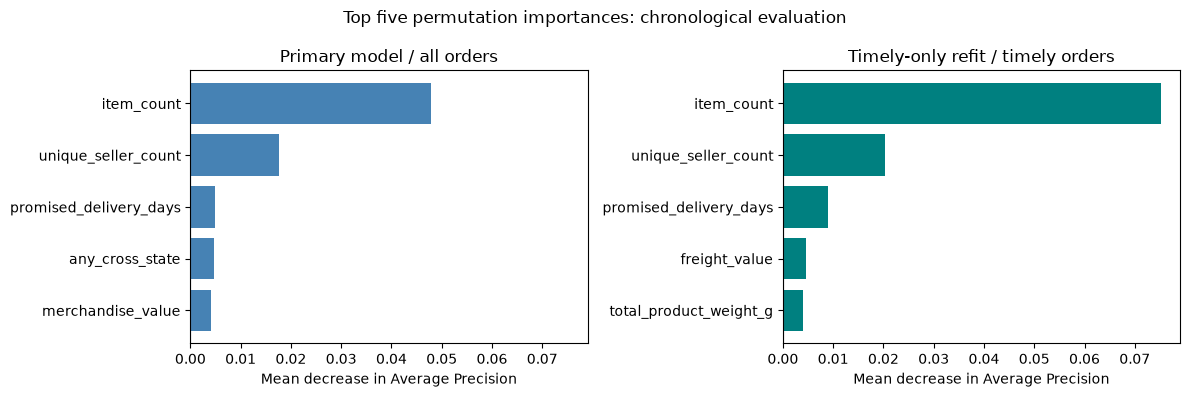

In [84]:
# AP-based permutation importances across evaluation populations.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for ax, importance, title, color in zip(
    axes,
    [permutation_top, timely_importance_df],
    ["Primary model / all orders", "Timely-only refit / timely orders"],
    ["steelblue", "teal"],
):
    top_features = importance.nlargest(5, "mean_ap_decrease")
    ax.barh(
        top_features["feature"],
        top_features["mean_ap_decrease"],
        color=color,
    )
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Mean decrease in Average Precision")
    ax.axvline(0, color="gray", linewidth=0.8)

fig.suptitle("Top five permutation importances: chronological evaluation")
plt.tight_layout()
plt.show()

<a id="section-68"></a>
#### Interpretation

The primary placement-time model retains useful ranking signal among orders that ultimately arrive on time. On the timely chronological holdout, its highest-risk 10% captures 24.7% of low-review outcomes (2.47× lift). The timely-only refit captures 27.1% on the same test population (2.71× lift). This is an observed improvement in top-decile concentration, not evidence that the difference is statistically reliable. Timely delivery defines a retrospective diagnostic subgroup; it is not known at placement.

The importance charts show a consistent leading pattern: item count, seller count, and promised delivery days are the three strongest predictors in both evaluations. Cross-state participation and merchandise value complete the primary model's top five, while freight value and product weight complete the timely-only refit's top five. Basket complexity therefore remains informative even when eventual late delivery is excluded from evaluation.

Permutation importance measures contribution to AP, not the direction or cause of an association. The different models and evaluation populations also prevent interpreting larger importance values as a direct improvement or stronger causal effect.

These findings support investigating customer-experience risk beyond delivery delays, particularly complex-order processes. However, at top-10% capacity the primary model captures fewer low reviews than item-count ranking on the full chronological holdout (20.54% versus 21.64%). The timely-subgroup results do not demonstrate incremental value over a subgroup-specific item-count rule, which was not evaluated here. Operational model use would require evidence of added value over simple targeting rules and a prospective assessment of support interventions.

<a id="section-69"></a>
### Investigating Basket Complexity and Product Mix

The model's importance results motivate this exploratory follow-up. Comparisons describe low-review rates by basket size and seller count, then examine whether the basket pattern persists within product categories and among timely deliveries. They do not independently validate the model or isolate causal effects.

Item counts of four or more are grouped for display. Category and product comparisons count each order once per category or listing; mixed baskets can appear in several groups. Category names follow the source dataset. Support thresholds are descriptive safeguards, not significance tests. No predictors, populations, or fitted models are changed.

reviewed_orders  low_review_rate
population       items sellers                                           
All reviewed     1     Single seller               88227           0.1271
                 2     Multiple sellers              949           0.4584
                       Single seller                6491           0.2346
                 3     Multiple sellers              201           0.4726
                       Single seller                1099           0.2657
                 4     Multiple sellers              114           0.5965
                       Single seller                 836           0.3206
Timely delivered 1     Single seller               80411           0.0755
                 2     Multiple sellers              935           0.4535
                       Single seller                6001           0.1971
                 3     Multiple sellers              200           0.4700
                       Single seller                1024           0.2334
                 4     Multiple sellers              114           0.5965
                       Single seller                 763           0.2805

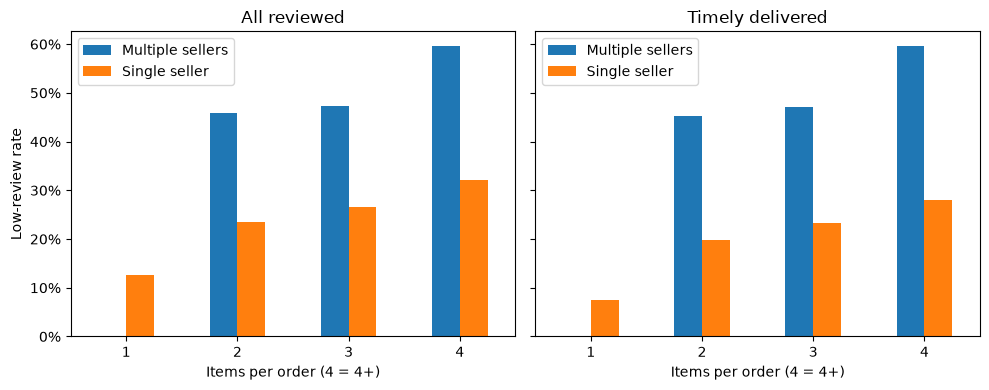

In [85]:
# Count each reviewed order once; delivery timing is retrospective context.
basket_orders = olist_df.groupby("order_id").agg(
    item_count=("order_item_id", "size"),
    seller_count=("seller_id", "nunique"),
    review_score=("last_review_score", "first"),
    delivered=("order_delivered_customer_date", "first"),
    promised=("order_estimated_delivery_date", "first"),
).dropna(subset=["review_score"])
basket_orders["low_review"] = basket_orders["review_score"].le(2)
basket_orders["timely"] = (
    basket_orders["delivered"].dt.normalize()
    <= basket_orders["promised"].dt.normalize()
)
basket_orders["items"] = basket_orders["item_count"].clip(upper=4)
basket_orders["sellers"] = np.where(
    basket_orders["seller_count"].eq(1), "Single seller", "Multiple sellers"
)

basket_rates = pd.concat({
    "All reviewed": basket_orders,
    "Timely delivered": basket_orders.loc[basket_orders["timely"]],
}, names=["population"]).groupby(
    ["population", "items", "sellers"]
).agg(
    reviewed_orders=("low_review", "size"),
    low_review_rate=("low_review", "mean"),
)
display(basket_rates.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, population in zip(axes, ["All reviewed", "Timely delivered"]):
    basket_rates.loc[population, "low_review_rate"].unstack().plot.bar(
        ax=ax, rot=0
    )
    ax.set_title(population)
    ax.set_xlabel("Items per order (4 = 4+)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.legend(title=None)
axes[0].set_ylabel("Low-review rate")
plt.tight_layout()
plt.show()

<a id="section-70"></a>
#### Basket Size and Seller Participation

Item count is the number of order-item rows, including repeated products, rather than distinct products or a separate quantity-field total. Distinct seller count is the number of unique seller IDs per order. The baseline contains no duplicate order/item keys. These three groups cover all reviewed orders in the existing basket analysis; shares use that reviewed population, and low-review rates use its existing 1–2-star outcome. The correlation describes how the counts move together, not independent or causal effects.

In [86]:
basket_group_labels = [
    "Single-item, single-seller",
    "Multi-item, single-seller",
    "Multi-item, multi-seller",
]
basket_groups = np.select(
    [basket_orders["item_count"].eq(1), basket_orders["seller_count"].eq(1)],
    basket_group_labels[:2],
    default=basket_group_labels[2],
)
basket_group_summary = (
    basket_orders.groupby(basket_groups)
    .agg(
        order_count=("low_review", "size"),
        low_review_rate=("low_review", "mean"),
    )
    .reindex(basket_group_labels)
    .rename_axis("Order group")
)
basket_group_summary.insert(
    1, "share_of_reviewed_orders_pct",
    100 * basket_group_summary["order_count"] / len(basket_orders),
)
basket_group_summary["low_review_rate"] *= 100
basket_group_summary = basket_group_summary.rename(
    columns={"low_review_rate": "low_review_rate_pct"}
)
display(basket_group_summary.round(2))
print(
    "Item-count / seller-count correlation: "
    f"{basket_orders['item_count'].corr(basket_orders['seller_count']):.3f}"
)


,order_count,share_of_reviewed_orders_pct,low_review_rate_pct
Order group,,,
"Single-item, single-seller",88227,90.10,12.71
"Multi-item, single-seller",8426,8.61,24.72
"Multi-item, multi-seller",1264,1.29,47.31


Item-count / seller-count correlation: 0.285


<a id="section-71"></a>
#### Investigating Order Complexity Beyond Delivery Delays

Using the same three order-composition groups as the basket EDA, this retrospective comparison includes all reviewed orders delivered on or before their promised calendar date, not only the chronological holdout. Percentages use this timely-delivered population. Delivery timing defines descriptive context and does not change model eligibility or predictors.

In [87]:
# Use observed delivery timing only for this retrospective comparison.
timely_composition = order_df.loc[
    order_df["order_id"].isin(olist_df.loc[
        olist_df["order_delivered_customer_date"].dt.normalize()
        <= olist_df["order_estimated_delivery_date"].dt.normalize(),
        "order_id",
    ])
]
timely_group_labels = [
    "Single-item, single-seller",
    "Multi-item, single-seller",
    "Multi-item, multi-seller",
]
timely_groups = np.select(
    [
        timely_composition["item_count"].eq(1),
        timely_composition["unique_seller_count"].eq(1),
    ],
    timely_group_labels[:2],
    default=timely_group_labels[2],
)
timely_composition_summary = (
    timely_composition.groupby(timely_groups)
    .agg(
        order_count=("low_review_2", "size"),
        low_review_rate_pct=("low_review_2", "mean"),
    )
    .reindex(timely_group_labels)
    .rename_axis("Order group")
)
timely_composition_summary.insert(
    1, "share_of_timely_orders_pct",
    100 * timely_composition_summary["order_count"] / len(timely_composition),
)
timely_composition_summary["low_review_rate_pct"] *= 100
display(timely_composition_summary.round(2))


,order_count,share_of_timely_orders_pct,low_review_rate_pct
Order group,,,
"Single-item, single-seller",80411,89.90,7.55
"Multi-item, single-seller",7788,8.71,21.01
"Multi-item, multi-seller",1249,1.40,46.92


Among timely deliveries, low-review rates rise from **7.6%** for single-item, single-seller orders to **21.0%** for multi-item, single-seller orders and **46.9%** for multi-item, multi-seller orders. The order-complexity pattern therefore persists when late deliveries are excluded. Multi-seller orders remain a small subgroup; these unadjusted rates do not establish causation or incremental model value over the simple rules.

<a id="section-72"></a>
#### Seller Concentration and Order-complexity Robustness

This descriptive check uses reviewed orders delivered on or before their estimated calendar date, with both dates observed. Item bands are 1, 2, 3, and 4+ order-item rows. Low reviews use the established latest answered 1–2-star outcome. Each order contributes once to rates; a seller-order association records one distinct seller participating in one order.

Activity leaders are ranked by their unique-order involvement within timely multi-seller orders, without using review outcomes. Top 1, 5, and 10 are fixed descriptive sensitivity checks, not optimized cutoffs. Activity ties follow seller-ID order. The low-review concentration ranking instead uses each seller's low-reviewed-order count, breaking ties by activity then seller ID; it is descriptive only. The first table uses the same five activity leaders across item bands. Coverage counts orders involving any selected seller once, so seller participation percentages need not add to 100%.

For robustness, every timely order involving a selected activity leader is removed from both single- and multi-seller groups before comparing rates within item-count bands. Missing multi-seller rates for one-item orders are structural: one item cannot involve multiple sellers. Reviews belong to orders and cannot identify which participating seller, if any, caused dissatisfaction.

<a id="section-73"></a>
#### Findings for the Order-complexity Narrative

The 1,249 timely multi-seller orders involve **819 distinct sellers** and **2,564 seller-order associations**. Their 586 low-reviewed orders involve **535 sellers**, while 663 other-reviewed orders involve **572 sellers**; **288 sellers appear in both outcome groups**. The 2-, 3-, and 4+-item groups involve 695, 259, and 179 sellers respectively, with overlap across groups.

The ten activity leaders participate in **26.7% of all timely multi-seller orders**, **27.6% of low-reviewed orders**, and **25.8% of other-reviewed orders**. The ten sellers with the most low-reviewed-order associations collectively participate in **29.0% of low-reviewed orders**. These shares indicate some concentration but do not suggest that a handful of sellers accounts for most low-review cases. Among the ten activity leaders, individual involvement differences between low and other outcomes range from approximately **−1.6 to +1.6 percentage points**; this is not an exhaustive search for problematic sellers.

After excluding orders involving the ten activity leaders, multi-seller low-review rates remain **45.2%, 43.3%, and 61.3%** for 2, 3, and 4+ items, versus **19.7%, 23.0%, and 28.1%** for single-seller orders in the same bands. The corresponding gaps remain **25.5, 20.3, and 33.3 percentage points**. The remaining multi-seller groups contain 714, 127, and 75 orders, so larger baskets still have limited support.

This sensitivity check supports the descriptive interpretation: the elevated low-review rate among timely multi-seller orders is not explained solely by the most frequently represented sellers. It does not establish that multiple sellers cause dissatisfaction, isolate coordination effects, or rule out other seller, product, period, or customer differences. Whole-order ratings also prevent assigning responsibility to individual sellers.

In [88]:
# Reuse the reviewed order-level basket data and calendar-date timely flag.
complexity_orders = basket_orders.loc[
    basket_orders["timely"], ["item_count", "seller_count", "low_review"],
].reset_index()
complexity_orders["item_band"] = complexity_orders["item_count"].clip(upper=4)
seller_links = olist_df[["order_id", "seller_id"]].drop_duplicates()
complexity_multi = complexity_orders.loc[complexity_orders["seller_count"].gt(1)]
complexity_links = seller_links.merge(
    complexity_multi[["order_id", "item_band", "low_review"]],
    on="order_id", validate="many_to_one",
)
# One seller-order association per row; rank sellers without using outcomes.
seller_frequency = (
    complexity_links.groupby("seller_id").agg(
        orders=("order_id", "size"), low_review_orders=("low_review", "sum"),
    )
    .sort_values("orders", ascending=False, kind="stable")
)
seller_frequency["other_review_orders"] = (
    seller_frequency["orders"] - seller_frequency["low_review_orders"]
)
complexity_support = []
for band, group in complexity_multi.groupby("item_band"):
    links = complexity_links.loc[complexity_links["item_band"].eq(band)]
    top_ids = seller_frequency.head(5).index
    complexity_support.append({
        "Items (4 = 4+)": band,
        "Unique orders": len(group),
        "Unique sellers": links["seller_id"].nunique(),
        "Seller-order associations": len(links),
        "Low-reviewed orders": int(group["low_review"].sum()),
        "Low-review rate (%)": 100 * group["low_review"].mean(),
        "Orders involving top 5 sellers (%)": 100 * group["order_id"].isin(
            links.loc[links["seller_id"].isin(top_ids), "order_id"]
        ).mean(),
    })
display(pd.DataFrame(complexity_support).set_index("Items (4 = 4+)").round(1))


,Unique orders,Unique sellers,Seller-order associations,Low-reviewed orders,Low-review rate (%),Orders involving top 5 sellers (%)
Items (4 = 4+),,,,,,
2,935,695,1870,424,45.3,15.7
3,200,259,432,94,47.0,28.5
4,114,179,262,68,59.6,21.9


In [89]:
# Count each order once even when it contains several selected sellers.
low_order_ids = complexity_multi.loc[
    complexity_multi["low_review"].eq(1), "order_id"
]
other_order_ids = complexity_multi.loc[
    complexity_multi["low_review"].eq(0), "order_id"
]
low_seller_frequency = seller_frequency.sort_values(
    "low_review_orders", ascending=False, kind="stable",
)
concentration_rows = []
for count in [1, 5, 10]:
    frequent_ids = seller_frequency.head(count).index
    frequent_orders = complexity_links.loc[
        complexity_links["seller_id"].isin(frequent_ids), "order_id"
    ].unique()
    low_ranked_orders = complexity_links.loc[
        complexity_links["seller_id"].isin(low_seller_frequency.head(count).index),
        "order_id",
    ].unique()
    concentration_rows.append({
        "Top sellers": count,
        "All orders involving activity leaders (%)": 100 * complexity_multi[
            "order_id"
        ].isin(frequent_orders).mean(),
        "Low orders involving activity leaders (%)": 100 * low_order_ids.isin(
            frequent_orders
        ).mean(),
        "Other orders involving activity leaders (%)": 100 * other_order_ids.isin(
            frequent_orders
        ).mean(),
        "Low orders involving low-review leaders (%)": 100 * low_order_ids.isin(
            low_ranked_orders
        ).mean(),
    })
print(
    f"Timely multi-seller orders: {len(complexity_multi):,}; "
    f"unique sellers: {len(seller_frequency):,}; "
    f"seller-order associations: {len(complexity_links):,}."
)
print(
    f"Low-reviewed orders: {len(low_order_ids):,}; contributing sellers: "
    f"{seller_frequency['low_review_orders'].gt(0).sum():,}. "
    f"Other-reviewed orders: {len(other_order_ids):,}; contributing sellers: "
    f"{seller_frequency['other_review_orders'].gt(0).sum():,}."
)
display(pd.DataFrame(concentration_rows).set_index("Top sellers").round(1))


Timely multi-seller orders: 1,249; unique sellers: 819; seller-order associations: 2,564.
Low-reviewed orders: 586; contributing sellers: 535. Other-reviewed orders: 663; contributing sellers: 572.


,All orders involving activity leaders (%),Low orders involving activity leaders (%),Other orders involving activity leaders (%),Low orders involving low-review leaders (%)
Top sellers,,,,
1,7.5,6.7,8.3,6.7
5,18.3,17.9,18.7,17.7
10,26.7,27.6,25.8,29.0


In [90]:
# Compare seller involvement in low versus other multi-seller orders.
seller_overlap = seller_frequency.head(10).copy()
seller_overlap["Low orders involving seller (%)"] = (
    100 * seller_overlap["low_review_orders"] / len(low_order_ids)
)
seller_overlap["Other orders involving seller (%)"] = (
    100 * seller_overlap["other_review_orders"] / len(other_order_ids)
)
seller_overlap["Low minus other involvement (pp)"] = (
    seller_overlap["Low orders involving seller (%)"]
    - seller_overlap["Other orders involving seller (%)"]
)
display(seller_overlap.rename(columns={
    "orders": "Seller-order associations", "low_review_orders": "Low orders",
    "other_review_orders": "Other orders",
}).round(1))


,Seller-order associations,Low orders,Other orders,Low orders involving seller (%),Other orders involving seller (%),Low minus other involvement (pp)
seller_id,,,,,,
4a3ca9315b744ce9f8e9374361493884,94,39,55,6.7,8.3,-1.6
1900267e848ceeba8fa32d80c1a5f5a8,45,19,26,3.2,3.9,-0.7
1835b56ce799e6a4dc4eddc053f04066,42,22,20,3.8,3.0,0.7
da8622b14eb17ae2831f4ac5b9dab84a,37,18,19,3.1,2.9,0.2
1f50f920176fa81dab994f9023523100,35,20,15,3.4,2.3,1.2
cca3071e3e9bb7d12640c9fbe2301306,32,20,12,3.4,1.8,1.6
1025f0e2d44d7041d6cf58b6550e0bfa,30,13,17,2.2,2.6,-0.3
6560211a19b47992c3666cc44a7e94c0,30,17,13,2.9,2.0,0.9
391fc6631aebcf3004804e51b40bcf1e,28,11,17,1.9,2.6,-0.7


In [91]:
# Exclude whole orders involving the activity leaders from both comparison groups.
robustness_rows = []
for count in [0, 1, 5, 10]:
    excluded_order_ids = seller_links.loc[
        seller_links["seller_id"].isin(seller_frequency.head(count).index),
        "order_id",
    ]
    retained = complexity_orders.loc[
        ~complexity_orders["order_id"].isin(excluded_order_ids)
    ]
    for band in [1, 2, 3, 4]:
        group = retained.loc[retained["item_band"].eq(band)]
        single = group.loc[group["seller_count"].eq(1), "low_review"]
        multi = group.loc[group["seller_count"].gt(1), "low_review"]
        robustness_rows.append({
            "Top sellers excluded": count,
            "Items (4 = 4+)": band,
            "Single-seller orders": len(single),
            "Single-seller low-review rate (%)": 100 * single.mean(),
            "Multi-seller orders": len(multi),
            "Multi-seller low-review rate (%)": 100 * multi.mean(),
            "Multi minus single (pp)": 100 * (multi.mean() - single.mean()),
        })
complexity_robustness = pd.DataFrame(robustness_rows).set_index([
    "Top sellers excluded", "Items (4 = 4+)",
])
display(complexity_robustness.round(1))


Single-seller orders  \
Top sellers excluded Items (4 = 4+)                         
0                    1                              80411   
                     2                               6001   
                     3                               1024   
                     4                                763   
1                    1                              79045   
                     2                               5895   
                     3                               1012   
                     4                                758   
5                    1                              76599   
                     2                               5427   
                     3                                918   
                     4                                693   
10                   1                              72547   
                     2                               5056   
                     3                                778   
                     4                                652   

                                     Single-seller low-review rate (%)  \
Top sellers excluded Items (4 = 4+)                                      
0                    1                                             7.5   
                     2                                            19.7   
                     3                                            23.3   
                     4                                            28.0   
1                    1                                             7.5   
                     2                                            19.7   
                     3                                            23.3   
                     4                                            28.1   
5                    1                                             7.6   
                     2                                            19.7   
                     3                                            23.1   
                     4                                            27.4   
10                   1                                             7.4   
                     2                                            19.7   
                     3                                            23.0   
                     4                                            28.1   

                                     Multi-seller orders  \
Top sellers excluded Items (4 = 4+)                        
0                    1                                 0   
                     2                               935   
                     3                               200   
                     4                               114   
1                    1                                 0   
                     2                               859   
                     3                               185   
                     4                               111   
5                    1                                 0   
                     2                               788   
                     3                               143   
                     4                                89   
10                   1                                 0   
                     2                               714   
                     3                               127   
                     4                                75   

                                     Multi-seller low-review rate (%)  \
Top sellers excluded Items (4 = 4+)                                     
0                    1                                            NaN   
                     2                                           45.3   
                     3                                           47.0   
                     4                                           59.6   
1                    1                                            NaN   
             

In [92]:
# Deduplicate order-category pairs so repeated units do not inflate rates.
category_orders = (
    olist_df[["order_id", "product_category_name"]]
    .fillna({"product_category_name": "unknown"})
    .drop_duplicates()
    .join(basket_orders[["item_count", "low_review", "timely"]], on="order_id")
    .dropna(subset=["low_review"])
)
category_orders["low_review"] = category_orders["low_review"].astype(int)
category_orders["basket"] = np.where(
    category_orders["item_count"].eq(1), "Single item", "Multiple items"
)
category_rates = category_orders.groupby("product_category_name").agg(
    reviewed_orders=("low_review", "size"),
    low_reviews=("low_review", "sum"),
    low_review_rate=("low_review", "mean"),
).sort_values("reviewed_orders", ascending=False)
display(category_rates.head(10).round(4))

category_basket_rates = pd.concat({
    "All reviewed": category_orders,
    "Timely delivered": category_orders.loc[category_orders["timely"]],
}, names=["population"]).groupby(
    ["population", "product_category_name", "basket"]
).agg(
    reviewed_orders=("low_review", "size"),
    low_review_rate=("low_review", "mean"),
)
# Require 100 reviewed orders in each basket group for this comparison.
category_counts = category_basket_rates["reviewed_orders"].unstack("basket")
category_comparison = category_basket_rates["low_review_rate"].unstack("basket")
category_comparison = category_comparison.loc[
    category_counts.ge(100).all(axis=1)
]
category_comparison["difference_pp"] = 100 * (
    category_comparison["Multiple items"] - category_comparison["Single item"]
)
print("Categories with higher multi-item low-review rates / eligible categories:")
for population, group in category_comparison.groupby(level="population"):
    print(population, int(group["difference_pp"].gt(0).sum()), "/", len(group))

top_categories = category_rates.head(10).index
display(category_comparison.loc[
    category_comparison.index.get_level_values("product_category_name")
    .isin(top_categories)
].round(4))

,reviewed_orders,low_reviews,low_review_rate
product_category_name,,,
cama_mesa_banho,9313,1561,0.1676
beleza_saude,8771,1114,0.1270
esporte_lazer,7669,998,0.1301
informatica_acessorios,6649,1070,0.1609
moveis_decoracao,6398,1067,0.1668
utilidades_domesticas,5843,772,0.1321
relogios_presentes,5576,848,0.1521
telefonia,4168,645,0.1548
automotivo,3877,562,0.1450


Categories with higher multi-item low-review rates / eligible categories:
All reviewed 21 / 21
Timely delivered 21 / 21


basket                                   Multiple items  Single item  \
population       product_category_name                                 
All reviewed     automotivo                      0.2747       0.1351   
                 beleza_saude                    0.2344       0.1181   
                 brinquedos                      0.2991       0.1158   
                 cama_mesa_banho                 0.3008       0.1434   
                 esporte_lazer                   0.2640       0.1152   
                 informatica_acessorios          0.3000       0.1422   
                 moveis_decoracao                0.2826       0.1353   
                 relogios_presentes              0.3455       0.1410   
                 telefonia                       0.3368       0.1412   
                 utilidades_domesticas           0.2676       0.1117   
Timely delivered automotivo                      0.2724       0.0788   
                 beleza_saude                    0.2032       0.0643   
                 brinquedos                      0.2593       0.0655   
                 cama_mesa_banho                 0.2760       0.0931   
                 esporte_lazer                   0.2364       0.0584   
                 informatica_acessorios          0.2661       0.0932   
                 moveis_decoracao                0.2555       0.0810   
                 relogios_presentes              0.3110       0.0863   
                 telefonia                       0.2985       0.0953   
                 utilidades_domesticas           0.2452       0.0663   

basket                                   difference_pp  
population       product_category_name                  
All reviewed     automotivo                    13.9598  
                 beleza_saude                  11.6353  
                 brinquedos                    18.3367  
                 cama_mesa_banho               15.7367  
                 esporte_lazer                 14.8762  
                 informatica_acessorios        15.7826  
                 moveis_decoracao              14.7243  
                 relogios_presentes            20.4472  
                 telefonia                     19.5568  
                 utilidades_domesticas         15.5944  
Timely delivered automotivo                    19.3563  
                 beleza_saude                  13.8861  
                 brinquedos                    19.3715  
                 cama_mesa_banho               18.2821  
                 esporte_lazer                 17.8000  
                 informatica_acessorios        17.2869  
                 moveis_decoracao              17.4546  
                 relogios_presentes            22.4653  
                 telefonia                     20.3175  
                 utilidades_domesticas         17.8952

In [93]:
# Product IDs identify listings, not readable product names.
product_orders = (
    olist_df[["order_id", "product_id", "product_category_name"]]
    .drop_duplicates(["order_id", "product_id"])
    .join(basket_orders[["item_count", "low_review"]], on="order_id")
    .dropna(subset=["low_review", "product_id"])
)
product_orders["low_review"] = product_orders["low_review"].astype(int)
product_orders["multiple_items"] = product_orders["item_count"].gt(1)
product_review_summary = product_orders.groupby("product_id").agg(
    category=("product_category_name", "first"),
    reviewed_orders=("low_review", "size"),
    low_reviews=("low_review", "sum"),
    low_review_rate=("low_review", "mean"),
    multi_item_share=("multiple_items", "mean"),
)
# A descriptive support threshold limits very sparse listing comparisons.
top_low_review_products = (
    product_review_summary.loc[product_review_summary["reviewed_orders"].ge(30)]
    .sort_values(["low_reviews", "reviewed_orders"], ascending=False)
    .head(10)
)
display(top_low_review_products.round(4))

,category,reviewed_orders,low_reviews,low_review_rate,multi_item_share
product_id,,,,,
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,458,74,0.1616,0.1507
53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,285,53,0.1860,0.3053
aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,429,52,0.1212,0.1958
422879e10f46682990de24d770e7f83d,ferramentas_jardim,351,50,0.1425,0.2906
e53e557d5a159f5aa2c5e995dfdf244b,informatica_acessorios,153,46,0.3007,0.3595
7c1bd920dbdf22470b68bde975dd3ccf,beleza_saude,221,43,0.1946,0.0407
389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,310,42,0.1355,0.2742
e0d64dcfaa3b6db5c54ca298ae101d05,relogios_presentes,192,42,0.2188,0.0260
368c6c730842d78016ad823897a372db,ferramentas_jardim,289,41,0.1419,0.2907


<a id="section-74"></a>
#### Category Comparison Among Timely Deliveries

Each pair compares single-item and multi-item orders within a category, using the ten most common categories and the existing minimum of 100 reviewed orders per group. Multi-item rates are higher in every displayed category. Mixed-category baskets overlap across groups; these are unadjusted associations.

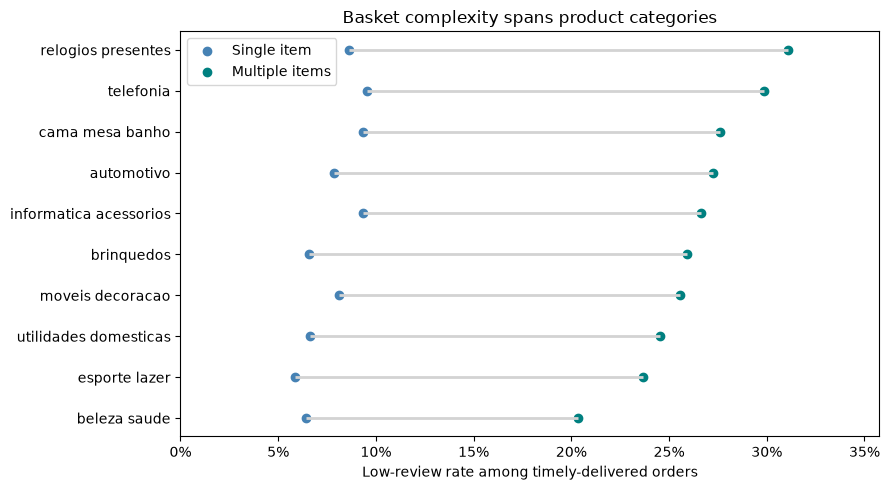

In [94]:
# Compare basket types within the ten most common categories.
category_plot = category_comparison.loc["Timely delivered"].reindex(
    category_rates.head(10).index
).dropna()
category_plot = category_plot.sort_values("Multiple items")
category_labels = category_plot.index.str.replace("_", " ")
y_positions = np.arange(len(category_plot))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hlines(
    y_positions,
    category_plot["Single item"],
    category_plot["Multiple items"],
    color="lightgray",
    linewidth=2,
)
for column, color in [("Single item", "steelblue"), ("Multiple items", "teal")]:
    ax.scatter(category_plot[column], y_positions, label=column, color=color)
ax.set_yticks(y_positions, labels=category_labels)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(
    xlabel="Low-review rate among timely-delivered orders",
    title="Basket complexity spans product categories",
    xlim=(0, category_plot[["Single item", "Multiple items"]].max().max() * 1.15),
)
ax.legend()
plt.tight_layout()
plt.show()

<a id="section-75"></a>
#### Product Frequency Versus Low-review Rate

The same ten listings are shown in both panels. Counts identify listings frequently present in low-reviewed orders; rates account for their reviewed-order exposure. Labels use category and shortened product ID because product names are unavailable. The annotations show reviewed-order counts. The overall prevalence line is contextual, not an adjusted product benchmark; an order rating cannot identify a responsible item.

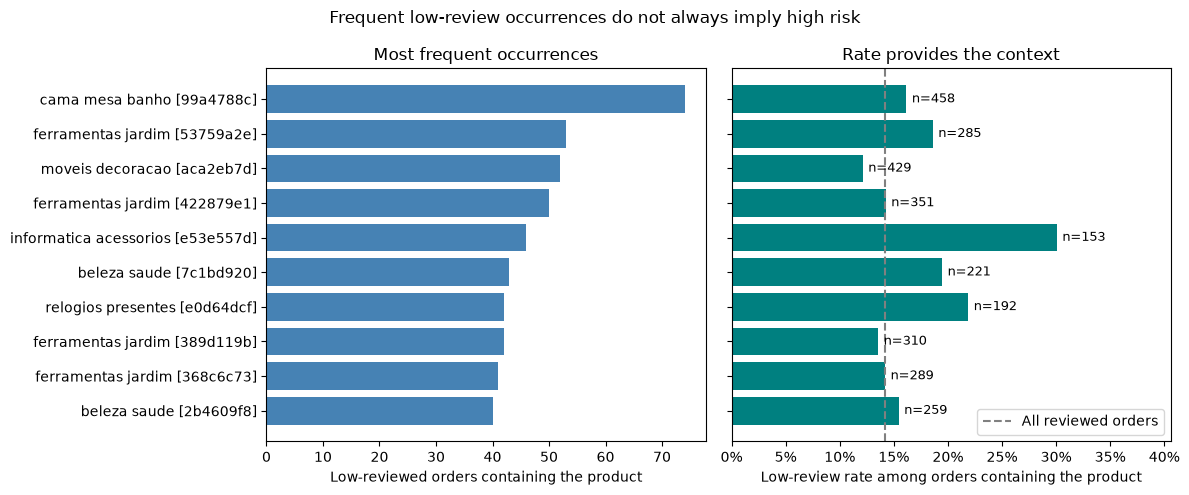

In [95]:
# Distinguish frequent low-review occurrences from elevated review rates.
product_plot = top_low_review_products.sort_values("low_reviews")
product_labels = [
    f"{row.category.replace('_', ' ')} [{product_id[:8]}]"
    for product_id, row in product_plot.iterrows()
]
y_positions = np.arange(len(product_plot))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(y_positions, product_plot["low_reviews"], color="steelblue")
axes[0].set_yticks(y_positions, labels=product_labels)
axes[0].set_xlabel("Low-reviewed orders containing the product")
axes[0].set_title("Most frequent occurrences")

bars = axes[1].barh(y_positions, product_plot["low_review_rate"], color="teal")
axes[1].bar_label(
    bars,
    labels=[f"n={count}" for count in product_plot["reviewed_orders"]],
    padding=4,
    fontsize=9,
)
axes[1].axvline(
    basket_orders["low_review"].mean(),
    color="gray",
    linestyle="--",
    label="All reviewed orders",
)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[1].set_xlim(0, product_plot["low_review_rate"].max() * 1.35)
axes[1].set_xlabel("Low-review rate among orders containing the product")
axes[1].set_title("Rate provides the context")
axes[1].legend(loc="lower right")
fig.suptitle("Frequent low-review occurrences do not always imply high risk")
plt.tight_layout()
plt.show()

<a id="section-76"></a>
#### Findings and Operational Implications

**Two distinct findings emerge: basket-complexity risk spans broad product categories, while frequent appearance in low-reviewed orders does not necessarily indicate a high-risk product.**

Among single-seller orders, low-review rates increase from 12.7% for one item to 23.5%, 26.6%, and 32.1% for two, three, and four or more items. Among timely single-seller orders, the corresponding rates are 7.6%, 19.7%, 23.3%, and 28.0%. Multiple-seller orders show still higher rates at the same item-count bands, but those groups are much smaller (114–949 reviewed orders overall).

Multi-item orders have higher low-review rates in all 21 categories meeting the minimum of 100 reviewed orders in each basket group, both overall and among timely deliveries. The pattern therefore is not confined to one broad category or eventual late delivery. These comparisons remain unadjusted for purchase period, individual products, seller mix, value, and other characteristics; mixed-category baskets also overlap across category groups.

Frequently occurring products in low-reviewed orders are not uniformly high-risk. For example, a furniture/decor listing appears in 52 low-reviewed orders out of 429 reviewed orders (12.1%, below the 14.2% overall rate), whereas a computer-accessories listing appears in 46 out of 153 (30.1%). Raw counts mix popularity with risk. Product IDs do not identify readable item names, and an order rating cannot attribute dissatisfaction to a particular item.

The findings support investigating multi-item and multi-seller order processes alongside product-specific issues. Operational records on completeness, damage, split shipments, communication, and support contacts could help distinguish possible explanations. The analysis does not establish that basket complexity itself causes dissatisfaction or that reducing basket size would improve outcomes.

The product summary does not test the same listing in single-item versus multi-item baskets, so it cannot establish whether individual-product composition explains the complexity pattern. The supported recommendation is to investigate both complex-order processes and listings with elevated low-review rates, rather than assign dissatisfaction exclusively to products or basket complexity.

<a id="order-model-brief"></a>
### Order-level Technical Model Brief

**Decision and approach.** The order analysis asks whether information reasonably available at placement can concentrate eventual 1–2-star reviews within a limited monitoring queue. It retains reviewed orders regardless of eventual status and excludes fulfillment outcomes from predictors. Logistic regression supplies a regularized linear benchmark; a decision tree tests simple nonlinear rules; random forest and histogram gradient boosting test richer interactions. Modest training-only, five-fold stratified searches compare hyperparameters and class weighting using average precision.

**Selection and what was learned.** Logistic regression establishes a linear ranking baseline; the single tree performs less well, while random forest improves on both in mean cross-validation average precision. Gradient boosting provides a further modest improvement over random forest. Gradient boosting has the strongest mean cross-validation average precision and is carried into ranking evaluation. The random holdout supports its historical discrimination, while the later-period sensitivity shows weaker performance. The main business benchmark is item-count ranking at equal 10% capacity: model capture is 24.25% versus 20.75% on the random holdout, but 20.54% versus 21.64% on the chronological holdout. Selection among fitted models does not establish superiority to this simpler operational alternative.

**Interpretation and limits.** Item and seller counts lead chronological permutation importance. Signal remains among retrospectively timely deliveries, and descriptive basket comparisons motivate investigation beyond lateness. Neither feature importance nor these comparisons establishes causality. Outcomes are conditional on observed reviews; checkout-time estimates and listing metadata rely on documented availability assumptions. Short history, related observations, repeated evaluation, and hyperparameters chosen using the random training sample limit claims about future deployment. The 60-day follow-up rule limits right censoring without converting missing reviews into negatives.

**Recommended next step.** Retain the model as a research comparator and assess a simple item-count queue before deployment. A prospective, capacity-matched pilot should establish whether either targeting approach improves customer outcomes enough to justify its operating cost. No intervention benefit is demonstrated by the retrospective results.


<a id="section-77"></a>
## Seller-level Event Prioritization
The following section uses seller history at scoring dates to prioritize review and support. Its data and model objects are constructed separately from the order section. Shared variable names are reused only after the order analysis is complete; rerunning an earlier cell in isolation requires restoring that section's preceding setup.

<a id="section-78"></a>
### Seller-model objective

Historical seller information is used to identify sellers likely to generate at least one observed 1–2-star review among the next month's orders. Scores support allocating seller-management review and support; they do not establish seller fault or an underlying dissatisfaction rate.

The design uses historical eligibility, non-overlapping future order windows, review-maturation deadlines, and chronological train/validation/test periods. Reviews are selected at order grain before attribution to each participating seller.

In [96]:
# 1. Imports and reproducibility



warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
RANDOM_STATE = 42

<a id="section-79"></a>
### Seller source-data preparation

The seller section reconstructs its source tables and timestamps using the shared setup. Both sections use the repository's shared Olist source files. The raw-table audits and general exploration are documented in preprocessing and EDA rather than repeated here.

In [97]:
required_files = {
    'customers': 'olist_customers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'orders': 'olist_orders_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'category_translation': 'product_category_name_translation.csv',
}

# Source CSV paths follow the repository directory structure.
data = {name: pd.read_csv(resolve_data_file(fname, 'raw')) for name, fname in required_files.items()}
for name, df in data.items():
    print(f'{name:22s}: {df.shape[0]:,} rows x {df.shape[1]} columns')

customers             : 99,441 rows x 5 columns
geolocation           : 1,000,163 rows x 5 columns
order_items           : 112,650 rows x 7 columns
payments              : 103,886 rows x 5 columns
reviews               : 99,224 rows x 7 columns
orders                : 99,441 rows x 8 columns
products              : 32,951 rows x 9 columns
sellers               : 3,095 rows x 4 columns
category_translation  : 71 rows x 2 columns


In [98]:
customers = data['customers'].copy()
geolocation = data['geolocation'].copy()
order_items = data['order_items'].copy()
payments = data['payments'].copy()
reviews = data['reviews'].copy()
orders = data['orders'].copy()
products = data['products'].copy()
sellers = data['sellers'].copy()
category_translation = data['category_translation'].copy()

for col in [
    'order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
    'order_delivered_customer_date','order_estimated_delivery_date'
]:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'], errors='coerce')
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'], errors='coerce')
reviews['review_time'] = reviews['review_answer_timestamp'].fillna(reviews['review_creation_date'])
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'], errors='coerce')

<a id="section-80"></a>
### Build one seller-order table
Each row below represents one seller within one order. This avoids duplicating seller totals while retaining product, freight, delivery, and shipping-deadline information.

In [99]:
items_enriched = order_items.merge(
    products[['product_id','product_category_name']], on='product_id', how='left'
)
seller_order = (
    items_enriched.groupby(['order_id','seller_id'], as_index=False)
    .agg(
        item_lines=('order_item_id','count'), sales=('price','sum'), freight=('freight_value','sum'),
        unique_products=('product_id','nunique'), unique_categories=('product_category_name','nunique'),
        last_shipping_limit=('shipping_limit_date','max')
    )
    .merge(orders[[
        'order_id','order_purchase_timestamp','order_delivered_carrier_date',
        'order_delivered_customer_date','order_estimated_delivery_date','order_status'
    ]], on='order_id', how='left')
)
seller_first_purchase = seller_order.groupby('seller_id').order_purchase_timestamp.min()
seller_order.head()

,order_id,seller_id,item_lines,sales,freight,unique_products,unique_categories,last_shipping_limit,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_status
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,1,58.900,13.290,1,1,2017-09-19 09:45:35,2017-09-13 08:59:02,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,delivered
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,1,239.900,19.930,1,1,2017-05-03 11:05:13,2017-04-26 10:53:06,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,delivered
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,1,199.000,17.870,1,1,2018-01-18 14:48:30,2018-01-14 14:33:31,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,delivered
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,1,12.990,12.790,1,1,2018-08-15 10:10:18,2018-08-08 10:00:35,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,delivered
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,1,199.900,18.140,1,1,2017-02-13 13:57:51,2017-02-04 13:57:51,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,delivered


<a id="section-81"></a>
### Leakage-safe seller snapshots with label maturation

**Unit:** one historically eligible seller at one scoring date.  
**Eligibility:** at least 5 orders in the prior 180 days, using historical information only.  
**Outcome window:** the next calendar month.  
**Maturation window:** one additional month for reviews to arrive before the next scoring date.  
**Target:** 1 if the seller generates at least one observed 1–2 star review in the next-month order cohort; otherwise 0.

Scoring dates are two months apart. Therefore future order windows do not overlap, and each snapshot’s labels are fully defined by the next scoring date.

<a id="section-82"></a>
#### Historical delivery timing definition
Historical lateness uses calendar dates, consistent with the order-level analysis and final EDA. An order is counted as historically late only when its actual delivery calendar date is after its estimated delivery calendar date. The delivery must have been observed before the scoring cutoff, and both delivery and estimated dates must be available; otherwise this feature remains missing for that seller-order.

In [100]:
def build_seller_cx_snapshot(cutoff, review_strategy='latest', history_days=180, min_history_orders=5):
    cutoff = pd.Timestamp(cutoff)
    outcome_end = cutoff + pd.offsets.MonthBegin(1)      # next-month order window ends
    label_deadline = cutoff + pd.DateOffset(months=2)    # reviews must be observable by next score date
    history_start = cutoff - pd.Timedelta(days=history_days)

    hist = seller_order[(seller_order.order_purchase_timestamp>=history_start) & (seller_order.order_purchase_timestamp<cutoff)].copy()
    hist['known_delivery'] = hist.order_delivered_customer_date.notna() & (hist.order_delivered_customer_date<cutoff)
    hist['late_known'] = np.where(
        hist.known_delivery & hist.order_estimated_delivery_date.notna(),
        hist.order_delivered_customer_date.dt.normalize()
        > hist.order_estimated_delivery_date.dt.normalize(),
        np.nan
    )
    hist['delivery_days_known'] = np.where(
        hist.known_delivery,
        (hist.order_delivered_customer_date-hist.order_purchase_timestamp).dt.total_seconds()/86400,
        np.nan
    )
    hist['known_handoff'] = hist.order_delivered_carrier_date.notna() & (hist.order_delivered_carrier_date<cutoff)
    hist['deadline_miss_known'] = np.where(
        hist.known_handoff & hist.last_shipping_limit.notna(),
        hist.order_delivered_carrier_date>hist.last_shipping_limit, np.nan
    )

    hist_agg = hist.groupby('seller_id', as_index=False).agg(
        hist_orders=('order_id','nunique'), hist_sales=('sales','sum'), hist_freight=('freight','sum'),
        hist_item_lines=('item_lines','sum'), hist_unique_products=('unique_products','sum'),
        hist_unique_categories=('unique_categories','sum'), hist_late_rate=('late_known','mean'),
        hist_avg_delivery_days=('delivery_days_known','mean'), hist_deadline_miss_rate=('deadline_miss_known','mean'),
        last_order_time=('order_purchase_timestamp','max')
    )
    hist_agg['hist_avg_order_value'] = hist_agg.hist_sales/hist_agg.hist_orders
    hist_agg['hist_freight_ratio'] = hist_agg.hist_freight/(hist_agg.hist_sales+hist_agg.hist_freight).replace(0,np.nan)
    hist_agg['hist_items_per_order'] = hist_agg.hist_item_lines/hist_agg.hist_orders
    hist_agg['hist_products_per_order'] = hist_agg.hist_unique_products/hist_agg.hist_orders
    hist_agg['hist_categories_per_order'] = hist_agg.hist_unique_categories/hist_agg.hist_orders
    hist_agg['seller_recency_days'] = (cutoff-hist_agg.last_order_time).dt.total_seconds()/86400
    hist_agg['seller_tenure_days'] = hist_agg.seller_id.map(seller_first_purchase)
    hist_agg['seller_tenure_days'] = (cutoff-hist_agg.seller_tenure_days).dt.total_seconds()/86400

    # Resolve review outcome at ORDER grain before attributing it to each seller.
    # This preserves every seller on multi-seller orders, without counting repeated
    # review records as separate orders.
    hist_orders = hist[['order_id', 'seller_id']].drop_duplicates()
    eligible_hist_reviews = reviews.loc[reviews.review_time < cutoff].copy()
    if review_strategy == 'latest':
        order_hist_review = (eligible_hist_reviews.sort_values(['order_id', 'review_time'])
                             .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
    elif review_strategy == 'first':
        order_hist_review = (eligible_hist_reviews.sort_values(['order_id', 'review_time'])
                             .drop_duplicates('order_id', keep='first')[['order_id', 'review_score']])
    elif review_strategy == 'mean':
        order_hist_review = eligible_hist_reviews.groupby('order_id', as_index=False)['review_score'].mean()
    else:
        raise ValueError('review_strategy must be latest, first, or mean')
    hist_review_order = hist_orders.merge(order_hist_review, on='order_id', how='inner')

    if len(hist_review_order):
        hist_review_order['hist_low_review']=(hist_review_order.review_score<=2).astype(int)
        hist_review_agg=hist_review_order.groupby('seller_id',as_index=False).agg(
            hist_avg_review=('review_score','mean'), hist_low_review_rate=('hist_low_review','mean'), hist_reviewed_orders=('order_id','nunique')
        )
    else:
        hist_review_agg=pd.DataFrame(columns=['seller_id','hist_avg_review','hist_low_review_rate','hist_reviewed_orders'])
    hist_agg=hist_agg.merge(hist_review_agg,on='seller_id',how='left')

    snapshot=hist_agg[hist_agg.hist_orders>=min_history_orders].copy()  # historical-only eligibility

    future_orders = seller_order[
        (seller_order.order_purchase_timestamp>=cutoff) & (seller_order.order_purchase_timestamp<outcome_end)
    ][['order_id','seller_id']].drop_duplicates()
    # Review records are selected once per order, then associated with ALL sellers
    # on that order. This is order-level attribution, not proof of seller causation.
    eligible_future_reviews = reviews.loc[reviews.review_time < label_deadline].copy()
    if review_strategy == 'latest':
        order_future_review = (eligible_future_reviews.sort_values(['order_id', 'review_time'])
                               .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
    elif review_strategy == 'first':
        order_future_review = (eligible_future_reviews.sort_values(['order_id', 'review_time'])
                               .drop_duplicates('order_id', keep='first')[['order_id', 'review_score']])
    elif review_strategy == 'mean':
        order_future_review = eligible_future_reviews.groupby('order_id', as_index=False)['review_score'].mean()
    else:
        raise ValueError('review_strategy must be latest, first, or mean')
    future_review_order = future_orders.merge(order_future_review, on='order_id', how='inner')

    if len(future_review_order):
        future_review_order['future_low_review']=(future_review_order.review_score<=2).astype(int)
        future_outcome=future_review_order.groupby('seller_id',as_index=False).agg(
            future_reviewed_orders=('order_id','nunique'), future_low_review_events=('future_low_review','sum'), future_avg_review=('review_score','mean')
        )
    else:
        future_outcome=pd.DataFrame(columns=['seller_id','future_reviewed_orders','future_low_review_events','future_avg_review'])

    snapshot=snapshot.merge(future_outcome,on='seller_id',how='left')
    snapshot['future_reviewed_orders']=snapshot.future_reviewed_orders.fillna(0)
    snapshot['future_low_review_events']=snapshot.future_low_review_events.fillna(0)
    snapshot['target']=(snapshot.future_low_review_events>=1).astype(int)
    snapshot['cutoff']=cutoff
    snapshot['outcome_end']=outcome_end
    snapshot['label_deadline']=label_deadline
    snapshot['review_strategy']=review_strategy
    return snapshot

<a id="section-83"></a>
### Build non-overlapping scoring snapshots
The six scoring dates are two months apart. Train, validation, and test periods are chronological.

,seller_snapshots,positive_rate,avg_future_reviewed_orders
cutoff,,,
2017-07-01,472,0.324,7.133
2017-09-01,580,0.291,6.202
2017-11-01,650,0.443,9.349
2018-01-01,791,0.382,7.630
2018-03-01,921,0.457,6.988
2018-05-01,1030,0.275,5.834


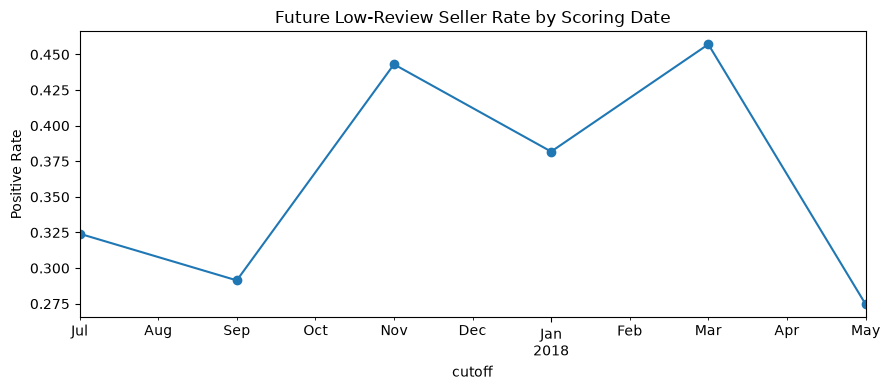

In [101]:
snapshot_dates = pd.to_datetime([
    '2017-07-01','2017-09-01','2017-11-01',
    '2018-01-01','2018-03-01','2018-05-01'
])
model_data = pd.concat([build_seller_cx_snapshot(d,'latest') for d in snapshot_dates], ignore_index=True)
snapshot_summary = model_data.groupby('cutoff').agg(
    seller_snapshots=('seller_id','size'), positive_rate=('target','mean'),
    avg_future_reviewed_orders=('future_reviewed_orders','mean')
)
display(snapshot_summary)
plt.figure(figsize=(9,4)); snapshot_summary.positive_rate.plot(marker='o');
plt.title('Future Low-Review Seller Rate by Scoring Date'); plt.ylabel('Positive Rate'); plt.tight_layout(); plt.show()

<a id="section-84"></a>
### Predictor set
All predictors are historical and available before the scoring date.

<a id="section-85"></a>
#### Interpretation of historical product and category features
`hist_unique_products` and `hist_unique_categories` **sum the distinct counts calculated within each historical seller-order**. They are not the number of distinct product IDs or categories across the entire 180-day history. The per-order average features divide these sums by historical order count. The feature calculations remain unchanged.

In [102]:
features = [
    'hist_orders','hist_sales','hist_freight','hist_item_lines','hist_unique_products','hist_unique_categories',
    'hist_late_rate','hist_avg_delivery_days','hist_deadline_miss_rate','hist_avg_order_value','hist_freight_ratio',
    'hist_items_per_order','hist_products_per_order','hist_categories_per_order','seller_recency_days','seller_tenure_days',
    'hist_avg_review','hist_low_review_rate','hist_reviewed_orders'
]
feature_dictionary = pd.DataFrame([
    ['hist_orders','Historical order count'],['hist_sales','Historical merchandise sales'],
    ['hist_freight','Historical freight value'],['hist_item_lines','Historical item-line volume'],
    ['hist_unique_products','Sum of per-order distinct product counts in history'],['hist_unique_categories','Sum of per-order distinct category counts in history'],
    ['hist_late_rate','Known historical late-delivery rate'],['hist_avg_delivery_days','Average known historical delivery time'],
    ['hist_deadline_miss_rate','Known seller shipping-deadline miss rate'],['hist_avg_order_value','Historical average order value'],
    ['hist_freight_ratio','Freight share of merchandise + freight'],['hist_items_per_order','Historical item lines per order'],
    ['hist_products_per_order','Historical products per order'],['hist_categories_per_order','Historical categories per order'],
    ['seller_recency_days','Days since most recent order'],['seller_tenure_days','Days since first observed seller order'],
    ['hist_avg_review','Average historical review known by cutoff'],['hist_low_review_rate','Historical 1–2 star review rate'],
    ['hist_reviewed_orders','Historical reviewed-order count']
], columns=['feature','business_meaning'])
feature_dictionary

,feature,business_meaning
0,hist_orders,Historical order count
1,hist_sales,Historical merchandise sales
2,hist_freight,Historical freight value
3,hist_item_lines,Historical item-line volume
4,hist_unique_products,Sum of per-order distinct product counts in hi...
5,hist_unique_categories,Sum of per-order distinct category counts in h...
6,hist_late_rate,Known historical late-delivery rate
7,hist_avg_delivery_days,Average known historical delivery time
8,hist_deadline_miss_rate,Known seller shipping-deadline miss rate
9,hist_avg_order_value,Historical average order value


<a id="section-86"></a>
### Chronological train / validation / test design
- **Train:** July, September, November 2017 snapshots  
- **Validation:** January and March 2018 snapshots  
- **Test:** May 2018 snapshot

The May test snapshot is untouched during model selection and tuning.

In [103]:
train=model_data[model_data.cutoff.isin(pd.to_datetime(['2017-07-01','2017-09-01','2017-11-01']))].copy()
validation=model_data[model_data.cutoff.isin(pd.to_datetime(['2018-01-01','2018-03-01']))].copy()
test=model_data[model_data.cutoff.eq(pd.Timestamp('2018-05-01'))].copy()
split_summary=pd.DataFrame({
    'split':['Train','Validation','Test'],'rows':[len(train),len(validation),len(test)],
    'positive_rate':[train.target.mean(),validation.target.mean(),test.target.mean()],
    'first_cutoff':[train.cutoff.min(),validation.cutoff.min(),test.cutoff.min()],
    'last_cutoff':[train.cutoff.max(),validation.cutoff.max(),test.cutoff.max()]
})
split_summary

,split,rows,positive_rate,first_cutoff,last_cutoff
0,Train,1702,0.358,2017-07-01,2017-11-01
1,Validation,1712,0.422,2018-01-01,2018-03-01
2,Test,1030,0.275,2018-05-01,2018-05-01


<a id="section-87"></a>
### Baseline and candidate models
A majority-class baseline can look accurate while identifying no positive sellers. The business use is ranking, so PR-AUC, ROC-AUC, lift, and capture are central.

In [104]:
baseline_accuracy=max(validation.target.mean(),1-validation.target.mean())
display(pd.DataFrame({'baseline':['Predict majority class'],'validation_accuracy':[baseline_accuracy],'positive_recall':[0.0]}))

target='target'
scaled=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
treeprep=Pipeline([('imputer',SimpleImputer(strategy='median'))])
models={
    'Logistic Regression':Pipeline([('prep',scaled),('model',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE))]),
    'Decision Tree':Pipeline([('prep',treeprep),('model',DecisionTreeClassifier(max_depth=6,min_samples_leaf=20,class_weight='balanced',random_state=RANDOM_STATE))]),
    'Random Forest':Pipeline([('prep',treeprep),('model',RandomForestClassifier(n_estimators=120,max_depth=10,min_samples_leaf=8,class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1))])
}

,baseline,validation_accuracy,positive_recall
0,Predict majority class,0.578,0.000


In [105]:
def top_fraction_metrics(y_true, probability, fraction=.10):
    frame=pd.DataFrame({'actual':np.asarray(y_true),'probability':np.asarray(probability)}).sort_values('probability',ascending=False)
    n=max(1,int(np.ceil(len(frame)*fraction))); selected=frame.head(n); base=frame.actual.mean()
    precision_sel=selected.actual.mean(); capture=selected.actual.sum()/frame.actual.sum() if frame.actual.sum()>0 else np.nan
    lift=precision_sel/base if base>0 else np.nan
    return precision_sel,capture,lift

def metric_row(name,y_true,probability,seconds=np.nan,threshold=.50):
    pred=(np.asarray(probability)>=threshold).astype(int); p10,c10,l10=top_fraction_metrics(y_true,probability,.10)
    return {'model':name,'seconds':seconds,'accuracy':accuracy_score(y_true,pred),'precision':precision_score(y_true,pred,zero_division=0),
            'recall':recall_score(y_true,pred,zero_division=0),'f1':f1_score(y_true,pred,zero_division=0),
            'roc_auc':roc_auc_score(y_true,probability),'pr_auc':average_precision_score(y_true,probability),
            'top10_precision':p10,'top10_capture':c10,'top10_lift':l10}

validation_probabilities={}; fitted_models={}; rows=[]
for name,model in models.items():
    print('Training',name,'...'); t0=perf_counter(); model.fit(train[features],train[target]); prob=model.predict_proba(validation[features])[:,1]; elapsed=perf_counter()-t0
    fitted_models[name]=model; validation_probabilities[name]=prob; rows.append(metric_row(name,validation[target],prob,elapsed)); print(f'Finished in {elapsed:.2f}s')
validation_results=pd.DataFrame(rows).sort_values(['top10_lift','pr_auc'],ascending=False).reset_index(drop=True)
validation_results

Training Logistic Regression ...
Finished in 0.01s
Training Decision Tree ...
Finished in 0.01s
Training Random Forest ...
Finished in 0.20s


,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift
0,Random Forest,0.200,0.709,0.692,0.557,0.618,0.757,0.715,0.866,0.206,2.051
1,Logistic Regression,0.012,0.695,0.653,0.595,0.622,0.754,0.707,0.849,0.202,2.010
2,Decision Tree,0.011,0.691,0.667,0.537,0.595,0.730,0.667,0.837,0.199,1.982


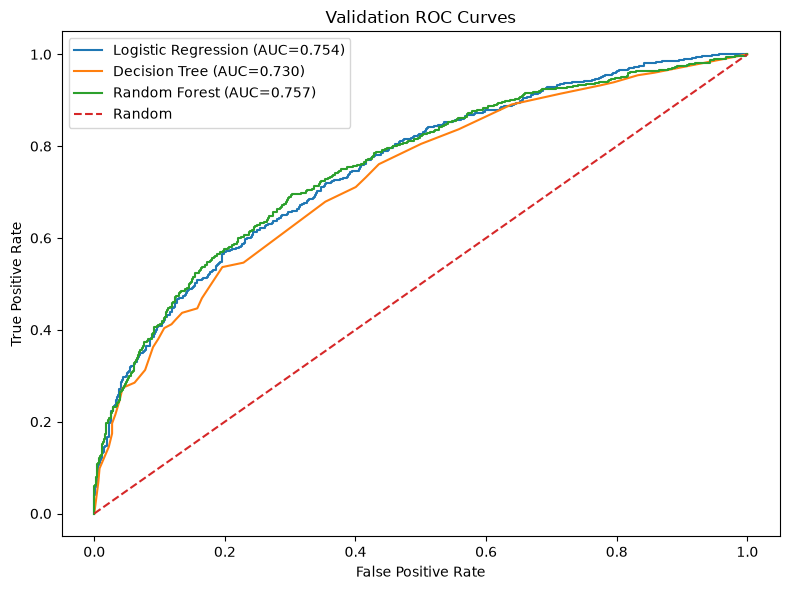

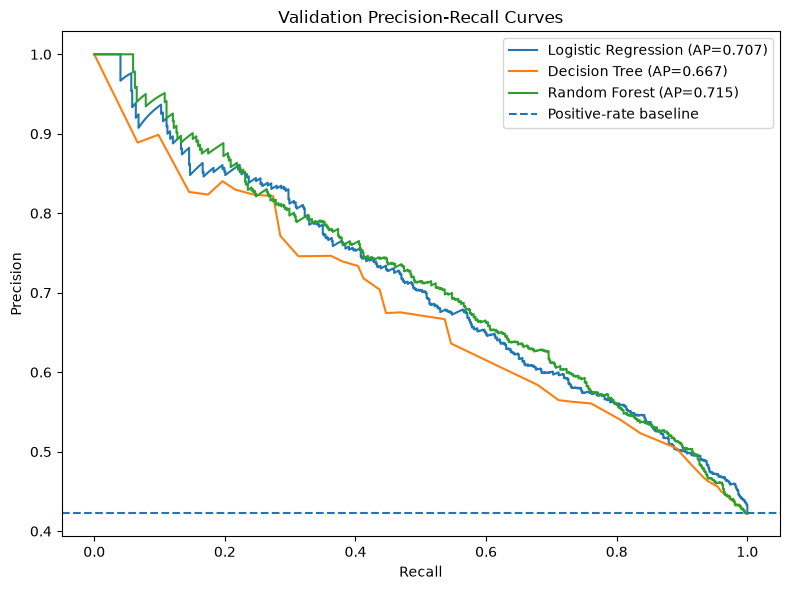

In [106]:
plt.figure(figsize=(8,6))
for name,prob in validation_probabilities.items():
    fpr,tpr,_=roc_curve(validation[target],prob); plt.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(validation[target],prob):.3f})')
plt.plot([0,1],[0,1],linestyle='--',label='Random'); plt.title('Validation ROC Curves'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,6))
for name,prob in validation_probabilities.items():
    precision_curve,recall_curve,_=precision_recall_curve(validation[target],prob); plt.plot(recall_curve,precision_curve,label=f'{name} (AP={average_precision_score(validation[target],prob):.3f})')
plt.axhline(validation[target].mean(),linestyle='--',label='Positive-rate baseline'); plt.title('Validation Precision-Recall Curves'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.tight_layout(); plt.show()

<a id="section-88"></a>
### Capacity analysis and tuning
The seller-success team may only have capacity to review a fraction of sellers. The analysis evaluates top 10%, 20%, and 30% ranking scenarios and uses top-decile lift as the primary selection metric because seller-success capacity is limited; PR-AUC is the secondary ranking metric. Random Forest is tuned only if it leads under this rule.

In [107]:
def capacity_metrics(y_true,probability,fractions=(.10,.20,.30)):
    frame=pd.DataFrame({'actual':np.asarray(y_true),'probability':np.asarray(probability)}).sort_values('probability',ascending=False)
    total=frame.actual.sum(); base=frame.actual.mean(); rows=[]
    for frac in fractions:
        n=max(1,int(np.ceil(len(frame)*frac))); sel=frame.head(n); precision_sel=sel.actual.mean(); capture=sel.actual.sum()/total if total>0 else np.nan; lift=precision_sel/base if base>0 else np.nan
        rows.append({'capacity':f'Top {int(frac*100)}%','selected_sellers':n,'precision_selected':precision_sel,'capture_of_all_positives':capture,'lift':lift})
    return pd.DataFrame(rows)

caps=[]
for name,prob in validation_probabilities.items():
    t=capacity_metrics(validation[target],prob); t.insert(0,'model',name); caps.append(t)
validation_capacity=pd.concat(caps,ignore_index=True); display(validation_capacity)

leading_model_name=validation_results.iloc[0].model; print('Leading validation model:',leading_model_name)
if leading_model_name=='Random Forest':
    candidates=[
        {'n_estimators':100,'max_depth':8,'min_samples_leaf':10,'max_features':'sqrt'},
        {'n_estimators':150,'max_depth':12,'min_samples_leaf':8,'max_features':'sqrt'},
        {'n_estimators':200,'max_depth':16,'min_samples_leaf':6,'max_features':'sqrt'}]
    tuning_rows=[]; tuned=[]
    for i,p in enumerate(candidates,1):
        m=Pipeline([('prep',SimpleImputer(strategy='median')),('model',RandomForestClassifier(**p,class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1))])
        m.fit(train[features],train[target]); prob=m.predict_proba(validation[features])[:,1]; row=metric_row(f'RF Candidate {i}',validation[target],prob); row.update(p); tuning_rows.append(row); tuned.append(m)
    rf_tuning_results=pd.DataFrame(tuning_rows).sort_values(['top10_lift','pr_auc'],ascending=False).reset_index(); display(rf_tuning_results)
    best_model=tuned[int(rf_tuning_results.loc[0,'index'])]
else:
    best_model=fitted_models[leading_model_name]
best_validation_probability=best_model.predict_proba(validation[features])[:,1]
print('Selected validation ROC-AUC:',round(roc_auc_score(validation[target],best_validation_probability),3))
print('Selected validation PR-AUC:',round(average_precision_score(validation[target],best_validation_probability),3))

,model,capacity,selected_sellers,precision_selected,capture_of_all_positives,lift
0,Logistic Regression,Top 10%,172,0.849,0.202,2.010
1,Logistic Regression,Top 20%,343,0.767,0.364,1.816
2,Logistic Regression,Top 30%,514,0.702,0.499,1.663
3,Decision Tree,Top 10%,172,0.837,0.199,1.982
4,Decision Tree,Top 20%,343,0.752,0.357,1.781
5,Decision Tree,Top 30%,514,0.669,0.476,1.585
6,Random Forest,Top 10%,172,0.866,0.206,2.051
7,Random Forest,Top 20%,343,0.778,0.369,1.843
8,Random Forest,Top 30%,514,0.712,0.506,1.686


Leading validation model: Random Forest


,index,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift,n_estimators,max_depth,min_samples_leaf,max_features
0,0,RF Candidate 1,NaN,0.701,0.682,0.546,0.607,0.756,0.715,0.872,0.207,2.065,100,8,10,sqrt
1,2,RF Candidate 3,NaN,0.699,0.687,0.526,0.596,0.752,0.709,0.860,0.205,2.038,200,16,6,sqrt
2,1,RF Candidate 2,NaN,0.704,0.686,0.553,0.613,0.753,0.710,0.855,0.203,2.024,150,12,8,sqrt


Selected validation ROC-AUC: 0.756
Selected validation PR-AUC: 0.715


<a id="section-89"></a>
### Seller target and business interpretation
The target is whether a historically eligible seller has **at least one observed 1–2-star reviewed order in the following month**, not the seller's underlying dissatisfaction rate. Sellers with no observed future low-review event, including those without reviewed future orders, receive a zero label; this is not evidence of satisfaction. Sellers with more future orders have more opportunities to trigger the event. For multi-seller orders, the same order-level review is associated with each participating seller without identifying responsibility. The model provides a candidate seller-support ranking, but incremental value over a simple historical-activity ranking has **not** been demonstrated and should be tested before recommending deployment.

<a id="section-90"></a>
### Final fit and held-out test evaluation
After model selection using training and validation data only, the selected model is refitted on both sets and evaluated on the May 2018 test snapshot.

,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift
0,Final Seller CX Risk Model,NaN,0.707,0.477,0.689,0.564,0.791,0.622,0.757,0.276,2.756


              precision    recall  f1-score   support

           0      0.858     0.714     0.779       747
           1      0.477     0.689     0.564       283

    accuracy                          0.707      1030
   macro avg      0.668     0.701     0.671      1030
weighted avg      0.753     0.707     0.720      1030



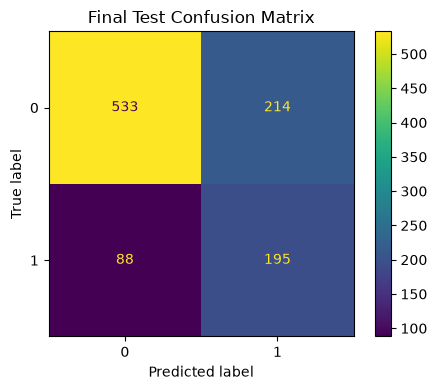

,capacity,selected_sellers,precision_selected,capture_of_all_positives,lift
0,Top 10%,103,0.757,0.276,2.756
1,Top 20%,206,0.597,0.435,2.173
2,Top 30%,309,0.528,0.576,1.920


In [108]:
train_validation=pd.concat([train,validation],ignore_index=True)
final_model=clone(best_model); final_model.fit(train_validation[features],train_validation[target])
test_probability=final_model.predict_proba(test[features])[:,1]
test_metrics=metric_row('Final Seller CX Risk Model',test[target],test_probability)
display(pd.DataFrame([test_metrics]))

test_prediction=(test_probability>=.50).astype(int)
print(classification_report(test[target],test_prediction,digits=3))
fig,ax=plt.subplots(figsize=(5,4)); ConfusionMatrixDisplay.from_predictions(test[target],test_prediction,ax=ax); plt.title('Final Test Confusion Matrix'); plt.tight_layout(); plt.show()

test_capacity=capacity_metrics(test[target],test_probability); display(test_capacity)

<a id="section-91"></a>
### Feature importance
Feature importance describes what the Random Forest uses for ranking; it does not prove causality.

,feature,importance
0,seller_recency_days,0.151
1,hist_item_lines,0.101
2,hist_orders,0.096
3,hist_unique_products,0.094
4,hist_freight,0.089
5,hist_unique_categories,0.087
6,seller_tenure_days,0.066
7,hist_reviewed_orders,0.053
8,hist_sales,0.039
9,hist_avg_delivery_days,0.033


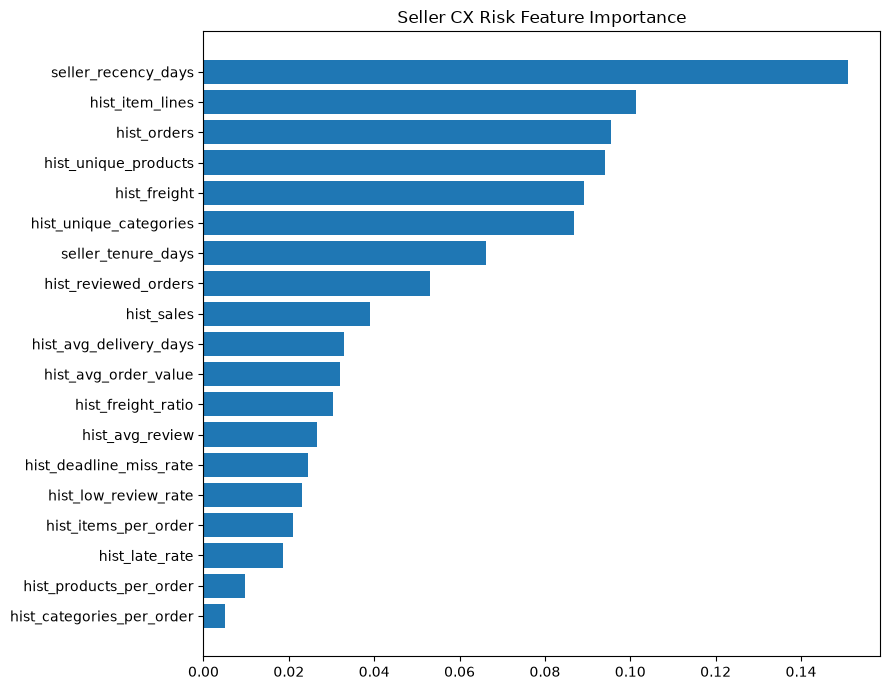

In [109]:
if hasattr(final_model.named_steps['model'],'feature_importances_'):
    importance=pd.DataFrame({'feature':features,'importance':final_model.named_steps['model'].feature_importances_}).sort_values('importance',ascending=False).reset_index(drop=True)
    display(importance)
    p=importance.sort_values('importance'); plt.figure(figsize=(9,7)); plt.barh(p.feature,p.importance); plt.title('Seller CX Risk Feature Importance'); plt.tight_layout(); plt.show()
else:
    print('Selected model does not expose tree feature importance.')

<a id="section-92"></a>
### Review-definition sensitivity
Seller snapshots are reconstructed using latest, mean, and first review definitions to assess whether multiple reviews change the conclusion.

In [110]:
sensitivity=[]
for strategy in ['latest','mean','first']:
    sd=pd.concat([build_seller_cx_snapshot(d,strategy) for d in snapshot_dates],ignore_index=True)
    st=sd[sd.cutoff.isin(pd.to_datetime(['2017-07-01','2017-09-01','2017-11-01','2018-01-01','2018-03-01']))].copy()
    ss=sd[sd.cutoff.eq(pd.Timestamp('2018-05-01'))].copy()
    sm=clone(final_model); sm.fit(st[features],st[target]); sp=sm.predict_proba(ss[features])[:,1]; top20=capacity_metrics(ss[target],sp,(.20,)).iloc[0]
    sensitivity.append({'review_strategy':strategy,'test_rows':len(ss),'positive_rate':ss[target].mean(),'roc_auc':roc_auc_score(ss[target],sp),'pr_auc':average_precision_score(ss[target],sp),'top20_precision':top20.precision_selected,'top20_capture':top20.capture_of_all_positives,'top20_lift':top20.lift})
review_sensitivity=pd.DataFrame(sensitivity); review_sensitivity

,review_strategy,test_rows,positive_rate,roc_auc,pr_auc,top20_precision,top20_capture,top20_lift
0,latest,1030,0.275,0.791,0.622,0.597,0.435,2.173
1,mean,1030,0.275,0.790,0.618,0.592,0.431,2.155
2,first,1030,0.276,0.788,0.616,0.583,0.423,2.113


<a id="section-93"></a>
### Technical Model Brief

<a id="section-94"></a>
#### What was tried
Logistic Regression, Decision Tree, and Random Forest were compared on chronological validation data. Model selection prioritizes top-decile lift because the business action is capacity-constrained seller review; PR-AUC is used as a secondary ranking metric. Random Forest is tuned if it leads under this rule.

<a id="section-95"></a>
#### Why
The models provide an interpretable linear benchmark, a simple nonlinear benchmark, and an ensemble capable of interactions.

<a id="section-96"></a>
#### What the model supports
The seller model estimates the probability that a historically active seller will generate at least one observed 1–2 star review in the next-month order cohort.

<a id="section-97"></a>
#### How it complements the order model
- **Order model:** early warning for individual orders at placement time.
- **Seller model:** next-month customer-experience risk for seller management.

<a id="section-98"></a>
#### Decision use
Scores support ranking sellers for review and support under limited capacity; they do not justify automatic penalties or removal.

<a id="section-99"></a>
#### Final model selection
Random Forest was selected because the business use case focuses on prioritizing sellers with limited review capacity. On validation data, the tuned model achieved a top-decile lift of 2.07×, PR-AUC of 0.715, and ROC-AUC of 0.756. These results supported its selection for the final evaluation.

On the May 2018 held-out test snapshot, the final Random Forest achieved ROC-AUC of 0.791 and PR-AUC of 0.622. At a top-20% seller-review capacity, the selected group captured 43.5% of sellers with an observed future low-review event, representing a 2.17× lift over random selection.


<a id="section-100"></a>
### Seller-model limitations and next steps

1. Historical public data may not represent current marketplace conditions.
2. Reviews are observational and not every order receives a review; no observed low review does not guarantee satisfaction.
3. Feature importance is predictive, not causal.
4. Sellers can appear in multiple snapshots, although future outcome windows are non-overlapping and labels mature before the next scoring date.
5. Eligibility is historical-only; future order volume is never used to decide who gets scored.
6. The dataset omits inventory availability, staffing, support history, and intervention history.
7. True intervention costs are unavailable, so dollar ROI should not be invented.
8. A prospective pilot and drift monitoring would be required before deployment.

9. **Multiple-seller order attribution:** A review belongs to the order. For multi-seller orders, the same order review is associated with each participating seller; it cannot identify which seller caused the outcome. Reviews are deduplicated at the order level before joining to sellers.
10. **Target exposure:** The target is at least one observed low-review event among the next month's orders, not a seller's underlying low-review rate. Higher-volume sellers have more opportunities for a positive event. Sellers without an observed low review (including sellers without reviewed future orders) receive a zero label; this is not proof of satisfaction.
11. **Review maturation:** The label deadline provides a consistent observation window, not a guarantee that all reviews have arrived.


Review-definition sensitivity reuses the May test cohort after the primary evaluation. This is a held-out historical evaluation with post-evaluation sensitivity checks, not an indefinitely untouched test. The one-month review-maturation gap defines an observed-by-deadline event and does not guarantee complete eventual review coverage.

<a id="section-101"></a>
#### Recommended next steps
- Evaluation of incremental targeting value over a simple historical-activity ranking before operational deployment.
- Definition of a prospective seller-review capacity, such as top 20%, for a controlled pilot if incremental value is demonstrated.
- Prospective tracking of seller outreach, low-review incidence, and fulfillment outcomes.
- Evaluation of richer operational features when available.



<a id="section-102"></a>
### Reproducibility and references

**GitHub repository:** https://github.com/asherdata1/supply-chain-decision-support

**Dataset citation (APA 7):**  
Olist. (2018). *Brazilian E-Commerce Public Dataset by Olist* [Data set]. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

**Execution environment:** The consolidated notebook was validated using Python 3.11.15, pandas 3.0.3, NumPy 2.4.6, scikit-learn 1.9.0, and Matplotlib 3.11.0. These identify the validation environment rather than guarantee identical results under other versions. All packages are imported in the first cell. Run cells in order using the source-data locations described at the beginning; preprocessing exports the shared baseline before downstream analysis. The repository commit history records the project's development.

<a id="section-103"></a>
## Project Interpretation

The order model provides the project's primary evidence for customer-experience risk ranking at placement. Its timely-delivery diagnostic examines whether that signal extends beyond eventual lateness; it does not change operational eligibility.

The seller model supports a separate queue for historically active sellers likely to generate observed low-review events. Greater future activity creates more opportunities for such events. Business claims about seller quality, intervention benefit, or incremental value beyond activity require separate evidence.

Both analyses are retrospective and conditional on their respective review-observation rules. No combined order/seller scoring system or intervention effect is evaluated here. Any model deployment recommendation should be conditional on an activity-ranking benchmark and prospective evaluation.

At the evaluated top-10% order-monitoring capacity, gradient boosting captures 24.25% of low reviews versus 20.75% for item-count ranking on the random holdout. On the chronological holdout, the corresponding captures are 20.54% and 21.64%. The model therefore demonstrates ranking signal, but not a consistent incremental advantage over the simple rule across these evaluations. The chronological exercise is a retrospective sensitivity analysis using settings selected on the random training sample, not a wholly independent temporal model-selection experiment.

The more defensible operational starting point is to assess simple basket-complexity targeting alongside existing fulfillment monitoring. Elevated low-review rates among timely complex orders, including within category comparisons and seller-concentration checks, motivate investigation of order coordination and customer communication. They do not identify a responsible item or seller, establish causality, or show that an intervention improves satisfaction.

Beyond this course, a prospective pilot could compare simple-rule and model-based queues at a fixed support capacity, track costs and customer outcomes, and test whether proactive support produces incremental benefit. Longer historical coverage, operationally timestamped checkout attributes, and refreshed reviews would support stronger temporal validation and monitoring of performance drift. Seller-level scores would require their own activity baseline and intervention evaluation before operational use.


<a id="ai-disclosure"></a>
## AI Assistance Disclosure

OpenAI ChatGPT/Codex assisted with code drafting and debugging, notebook organization, documentation, and interpretation of analytical outputs. AI suggestions were reviewed and revised during project development; the team remains responsible for the methods, results, and conclusions. The empirical findings use the Olist source data and executed analyses, not AI-generated observations. This assistance does not provide independent validation of the findings.
